# 虚実行論 ―― 並列処理の総当りから「虚」の理論へ

(Version 0.4.1)

文責: JRF ( http://jrf.cocolog-nifty.com/ ) ／ 執筆・計算の大部分: Claude Opus 5.5 (Anthropic) ／ 2026年11月

**要旨.** JRF は 2011 年、並列プロセスのロック依存を総当りで調べる Perl プログラム ELDE (Exhaustive Lock Dependency Emulator) を書いた。2018 年になって、それが「実際にはありえない実行」まで数えていたことに気づき、それを **虚実行** と名付けた(本物は **実実行**)。JRF は「虚実行か実実行かを判定するプログラムは難しい」「虚実行と、ほかの理由で捨てた実行との違いがわからない。今のままでは虚実行に意味を見出すのは難しい」と書いている。

このノートはその宿題に答えようとするものである。主な結果は次のとおり。

1. 実行を「各クリティカルセクション(CS)がどの状態を読んだか」の **木** として見る。すると **実実行 ⇔ どの状態も高々一度しか読まれない ⇔ 木の葉が一つ** になる(定理 1)。虚実行とは状態を **コピー** してしまった実行、実実行とは状態を **移動** させた実行である。判定は一瞬で済む。
2. ELDE その1 の lock 仕様が表す実行を正確に特徴づけ(定理 2)、2 プロセスの場合の個数の漸化式と、その閉じた式・母関数・漸近式を出す。lock 仕様と実行は 3 プロセスまでは一対一に対応するが、4 プロセス以上ではそうならない。
3. 2 プロセスなら、虚実行はちょうど、Dijkstra 以来の **進行グラフ** で「禁止領域をすり抜ける」道に対応する(定理 3)。とくに、ある道の与える実行が実実行であることと、その道が禁止領域を通らないことは、プロセスがいくつでも同値になる。
4. 虚実行の階層をさらに上に延ばし、まだ書かれていない状態まで読んでよいとすると(時間逆行・時間ループ)、実行は前から計算できなくなり、**一周して整合する(自己無撞着な)ものだけが存在する**。実行が一つもない場合も、いくつもある場合もある(定理 4)。
5. 虚実行と、ほかの cut との違い: 虚実行は **局所的な制約はすべて満たし、大域的な線形性(保存則)だけを破る** 実行である。これが抽象解釈や線形論理、量子力学の複製不可能定理などと同じ構図であることを論じる。
6. ELDE の枠組みを拡張する: 複数ロックとデッドロック検出、wait_and_lock、確率的スケジューラ。
7. **虚数** との関係を三つの方向から具体的に作る: (a) 枝分かれの母関数を単位円上で積分すると実実行だけが残る(「虚」を経由して「実」に戻る計算)、(b) 進行グラフの禁止領域とトンネル効果、(c) 自分の未来の出力を読む「時間ループ」の自己無撞着解として虚数単位 $i$ がそのまま現れる(嘘つきのパラドックスの値は $i$)。

ノートの計算はすべてこの中で再現できる(Python 標準ライブラリ+numpy+matplotlib)。定理は小さな場合について総当りで確かめたうえで文章で証明し、さらに **定理 1〜4 は定理証明系 Lean 4(Mathlib)で形式的に証明した**。Lean のコードは各定理の直後に置き、ノートの最後(付録)で一括して検査する。定理の番号はこのノートの中だけのものである。

なお、ELDE が用いた技法の多くには先行研究がある(§1.3)。このノートの新しさは技法よりも、捨てられるはずの「虚実行」を、それ自体として意味を持つ対象として調べる点にある。

**0.4.1 での変更**: 読み直して、後続のレポート(report1〜3)との対応を足し、表現を直した(§5.2 の和の添字の意味、§5.5 のスケジューラで作れる段、§7.3 の不変条件の言い方、§10.4 とリング発振器)。

**0.4.0 での変更**: 定理 4 を Lean で証明した(§5.5)。2 プロセスの仕様数 $f(2a,2b)$ の母関数 $(1+x+y)/(1-x^2-xy-y^2)$、閉じた式、漸近式 $f(2a,2a) \sim \sqrt{3/(8\pi a)}\cdot 9^a$ を求めた(§5.2)。後続のレポート(report1〜3)で扱った課題への参照を書き、§11.2 を直した。参考文献の未確認だった二件を照合した。

**0.3.1 での変更**: §5.5 に、自己無撞着な実行は実実行ではないこと、階層が「コピー」と「因果」の二つの軸を緩めていること(四つの欄の表と数え上げ)、弱いメモリモデルの load buffering と out-of-thin-air 問題への予告を書いた。§10.4 の確認を、`is_consistent`(§5.5 の検査を取り出したもの)を使う形にした。

**0.3.0 での変更**: §5.5 を新設し、階層の上(時間逆行・時間ループ)では実行が自己無撞着性で決まることを、定理 4 とプログラム `consistent_executions` で示した。§10.4 の時間ループを ELDE の再生で確かめるセルを加えた。lock 仕様と rf の情報量の違いを §5.1 に書いた。Lean のコードを各定理の直後に移し、検査を Colab でもローカルでも動く形にした。

**0.2.0 での変更**(0.1.0 は未公開の初版): 定理 2 の「一対一」が 3 プロセスまでしか成り立たないことを見つけて訂正した(4 プロセスで反例)。定理 3(ii) をプロセス数によらない強い形にした。定理 1〜3 の Lean による証明を付録に加えた。先行研究との関係(§1.3)を書き、参考文献を照合した。§10.4 に時間ループの不動点での微分を加えた。

## 目次

- §0 このノートの読み方
- §1 経緯 ―― ELDE その1・その2・その3 と「虚実行」の発見
- §2 道具の準備 ―― Python による再実装
- §3 ELDE その1 の再現
- §4 実行を木として見る ―― 定理 1: 実実行 ⇔ 線形
- §5 lock 仕様の特徴づけと数え上げ ―― 定理 2・虚実行の階層・定理 4(実行の決まり方)
- §6 進行グラフ ―― 定理 3: 虚実行は禁止領域をすり抜ける
- §7 虚実行の使い道 ―― 健全な過大近似とその精錬
- §8 線形性 ―― コピーと移動、保存則、デッドロック
- §9 ELDE の拡張 ―― 複数ロック・wait_and_lock・確率
- §10 虚数との関係
- §11 まとめと今後の課題
- 参考文献
- 付録 Lean による一括検証

## §0 このノートの読み方

初学者向けに書いているので、並列処理の基本用語から説明する。

- **プロセス**: 同時に(並列に)動くプログラムの一つ一つ。ここでは 2〜3 個。
- **共有状態**: 全プロセスが読み書きする変数の集まり。以下では辞書 `{"a": 1, ...}` で表す。
- **ロック(lock)と排他制御**: 共有状態を読み書きする前に `lock` を取り、終わったら `unlock` する。ロックは一度に一つのプロセスしか持てない。
- **クリティカルセクション(CS)**: `lock` から `unlock` までの区間。共有状態はここでしか触らない。
- **実行(execution)**: プロセスたちが実際にどういう順番で CS を実行したか。

ELDE の基本的な考え方(JRF 2011)は次のとおりである。

> $context のデータが置き換わるのは、lock と unlock に挟まれた部分だけであり、その間では他のプロセスはデータを変えない。(...) つきつめれば、lock のときにのみ他のプロセスがデータを変えたかどうか調べればよいとなる。そしてデータが変わるのは他のプロセスが unlock をしたときだけである。

つまり、ロックが一つしかなく、共有状態を CS の中でしか触らないなら、実行の違いは「各 lock のとき、誰が直前に unlock した状態を受け取るか」だけで決まる。総当りすべきなのはその受け渡しだけ、というのが ELDE の着眼であった。

記号:

- プロセス $p$ の $m$ 番目の CS(lock $m$ から unlock $m$ まで)を $(p, m)$ と書く。0 から数える。
- JRF の記法 $\pi p\,\upsilon n \to \pi q\,\lambda m$(Perl 実装では `P{p}U{n}->P{q}L{m}`)は「プロセス $p$ の $n$ 番目の unlock の状態が、プロセス $q$ の $m$ 番目の lock の状態になる」という意味。$\pi$ は process、$\upsilon$ は unlock、$\lambda$ は lock の頭文字をギリシャ文字にしたもの(π計算・λ計算を少し意識した、と JRF は書いている)。
- 初期状態を $\bot$ と書く(コードでは `INIT`)。

## §1 経緯 ―― ELDE その1・その2・その3 と「虚実行」の発見

時系列で整理する(引用はすべて JRF のブログ・日記から)。

| 日付 | 出来事 | 出典 |
|---|---|---|
| 2011-06-20 | ELDE その1。lock 仕様 $\pi p\upsilon n\to\pi q\lambda m$ の列を総当りする Perl 実装 `exhaustive_lock_dependency_emulator_0.pl`。 | 《Exhaustive Lock Dependency Emulator その１ 並列処理の総当り》 |
| 2011-07-01 | ELDE その2。入力待ちを「特殊な枝刈り」として `wait_and_lock` を実装。確率についての考察。 | 《その２ wait_and_lock》 |
| 2011-09-08 | 「lock と(高階論理で使われる)ラムダ式の関係みたいなのが私には見えはじめてる」。 | [cocolog:69727785] |
| 2018-04-06 | その1 に「大きなミス」を発見し、「虚実行」と命名。 | [cocolog:89156596]、その1 の追記 |
| 2018-04-13 | ELDE その3(`elde_2.pl`)。実実行だけを数える版を作り、虚実行を含む版と突き合わせてチェック。 | 《その３ 修正とチェック》、[cocolog:89194943] |
| 2018-11-05 | 「すべてを数え上げるということから、グラフの最適化と同じように最適化の議論ができないか」。 | 日記 |
| 2022-08-24 | ホフスタッター『GEB』の「超自然数」を読み、虚実行も「よく出てくる拡張概念」の一つかもしれないと述べる。 | [cocolog:93692583] |
| 2025-01-12 | 「後者は虚実行という概念が出てきたのだった。ただ、最適化にそれをどうつなげればいいのかはまだぜんぜんわからない」。 | [cocolog:95231673] |

### 1.1 「虚実行」の定義(JRF 2018)

その1 の追記(2018-04-06)から引く。

> π0υ1→π1λ2 かつ π1υ4→π0λ3 とする。すると、間に π0λ2 とπ1λ3 があるわけで、こららは必ずどちらかが前でどちらかが後になる。π0υ2→π1λ3 か π1υ3→π0λ2 でなければならない。これが仕様に含まれてない実行はニセモノ…「虚実行」というべきものになる。
>
> もっと簡単に、プロセス群の中の一番最初のロック以外のプロセス q の最初のロックは πpυn→πqλ0 なる仕様(p n は任意)を含んでいないと「虚実行」になるし、プロセス群の最後のロックを含むプロセス以外のプロセス q の最後のロック l は πqυl→πpλn なる仕様(p n は任意)を含んでいないと「虚実行」になる。
>
> 「虚実行」群の中に「実実行」というべきものがすべて入っているので、「虚実行」群全体でテストに合格したものは「実実行」においてもテストに合格すると言えるが、余計なものまで(大量に)チェックしていることは否めない。
>
> 「虚実行」か「実実行」かを判定するプログラムを書こうかと思ったが難しい。

日記 [cocolog:89156596] ではこう説明している。

> あるプロセスで別のプロセスのアンロックロックをかけ、双方のプロセスでいくつかロックが過ぎてから、元のプロセスへ復帰したというとき、その間のロックには必ず前後関係がなければならないが、そのような関係がない仕様も含めていたのが問題となった。エミュレートはできるが、実際にはそういう実行はありえないということで、そういうのを「虚実行」と呼ぶことにする。対称的なものを「実実行」と呼ぶ。

### 1.2 JRF が残した問い

その3(2018-04-13)の結びと、そこからの問いを並べておく。このノートはこれらに答えることを目標にする。

- **問 A**(判定): 虚実行と実実行を判定するプログラムは書けるか。 → §4 定理 1。
- **問 B**(意味): 「「虚実行」という考え方は、この「虚実行」以外にも cut している実行があり、それらと「虚実行」を分けるものが何かと問われると難しく、今のままでは「虚実行」そのものに意味を見出すのは難しい。」 → §5.4 と §7、§8。
- **問 C**(連続性): 「今後、ELDE を発展させていくなかでデッドロックに関して連続とか不連続とかを定義できて、そこに絡めて何とか言えたりしたら、カッコイイんだけど」。 → §6 と §9.2(有向位相幾何)。
- **問 D**(複数ロック): 「単一ロックではなく複数ロックに対応できたらすばらしい。(...) その上で、デッドロックになるとかならないとかの議論ができればカッコイイ」。 → §9.2。
- **問 E**(確率): その2 の「「現実」にはまともな「確率」が存在しない」「wait_and_lock は枝刈りを行うが、その場合の数以上にとても大きな「現実」も枝刈りしたとできるのかもしれない」。 → §9.4。
- **問 F**(拡張概念): 虚実行は負数や虚数のような「拡張概念」として意味を持ちうるか。 → §10。

### 1.3 先行研究との関係

ELDE の技法そのものは、その後の(あるいは同時代の)研究と多く重なる。新しさを正しく位置づけるために、先に整理しておく。

- **プロセスを何度も再実行して全実行を調べる**(ELDE その3): **ステートレス・モデル検査** として確立している。VeriSoft(Godefroid 1997)は、C で書かれた並行プログラムを状態を保存せずに再実行しながら探索した。CHESS(Musuvathi ら 2008)はスケジューラを乗っ取って全インタリーブを系統的に試す。JRF 自身がその3 で書いたとおり「車輪の再発明」の面がある。
- **「lock のときだけ調べればよい」**(ELDE の着眼): Lipton(1975)の **リダクション** は、ほかのプロセスと干渉しない操作を前後の同期操作にまとめて、一つの原子的な操作とみなしてよい条件を与えた。Adve & Hill(1990)の **DRF 保証** は、データ競合のない(共有データをロックの中でしか触らない)プログラムには、メモリが逐次一貫に見えることを保証する。ELDE の前提はこの二つと同じ考えである。
- **実行を「誰の書いた値を誰が読んだか」(読み出し関係 rf)で数える**(ELDE その1 の lock 仕様): 2018〜2019 年ごろの **rf にもとづく動的半順序簡約** がまさにこの見方をとる(Chalupa ら 2018 の data-centric DPOR、Abdulla ら 2019)。ただしそれらの要点は、**実現可能な** rf の類だけを、一つずつ効率よく数えることにある。ELDE その1 は、実現不可能な rf まで数えてしまった。
- **候補をすべて作ってから、実現可能なものだけを残す**: 弱いメモリモデルの **公理的な記述**(Alglave ら 2014 の "Herding cats" など)は、プログラム順序・読み出し関係・書き込み順序の組(**候補実行**)をすべて作り、一貫性の公理で実現可能なものだけを残す。そこで捨てられる候補実行が、このノートの虚実行にほぼあたる。

つまり、虚実行に相当するものは計算機科学の中にすでに現れている。ただしそれは、捨てるべき不良品として現れる。このノートの立場は、それを捨てずに調べることにある。状態を **コピー** した実行として木で読むこと(§4)、実実行を含む健全な過大近似として使うこと(§7)、負数や虚数と同じ型の **拡張概念** として位置づけること(§5.4、§10)である。定理 1 は木で見ればほとんど自明であり、定理 2・3 も小さな観察である。数学的な深さよりも、見方の新しさがこのノートの主張である。

## §2 道具の準備 ―― Python による再実装

JRF の ELDE は Perl で、プロセスを「何度も最初から実行し直す」方式で書かれている。`lock` が来たら、lock 仕様を見て「どの状態を渡すか」を決める。ここでも同じ方式をとる。プロセスは Python の **ジェネレータ** として書き、`s = yield LOCK` でロックを取って状態 `s` を受け取り、`yield unlock(s)` で新しい状態を返す。ELDE と同じく、プロセスは状態に関して **関数的**(同じ入力の列には同じふるまい)でなければならない。

以下のセルは `kj_core.py`(再実装の中心)と `kj_ext.py`(拡張)をファイルとして書き出す。長いので、最初は読み飛ばして §3 から見てもよい。

In [1]:
# 日本語フォントの設定(Colab では japanize-matplotlib を入れると楽)
import matplotlib
import matplotlib.pyplot as plt
try:
    import japanize_matplotlib  # noqa: F401
except Exception:
    from matplotlib import font_manager
    for name in ["Noto Sans CJK JP", "IPAexGothic", "IPAGothic", "TakaoGothic", "Yu Gothic", "Meiryo"]:
        if any(name == f.name for f in font_manager.fontManager.ttflist):
            matplotlib.rcParams["font.family"] = name
            break
matplotlib.rcParams["axes.unicode_minus"] = False
import numpy as np
import math, cmath, itertools
from collections import Counter, defaultdict
print("ok")

ok


### 2.1 `kj_core.py` ―― 再実装の中心

状態の表し方、プロセスの再生、実実行と虚実行の総当り、ELDE その1 の忠実な移植、判定関数。

In [2]:
%%writefile kj_core.py
# -*- coding: utf-8 -*-
"""kj_core.py -- 「虚実行」レポート用の計算コア。

ELDE (Exhaustive Lock Dependency Emulator, JRF 2011/2018, Perl) の考え方を
Python で再実装し、さらに拡張する。

プログラム(プロセス)の書き方:
    プロセスは「ジェネレータ関数 prog(out)」として書く。
      s = yield LOCK          # ロックを取る。共有状態 s を受け取る。
      s = put(s, "a", 1)      # 状態は不変(immutable)な辞書として扱う。
      yield unlock(s)         # 新しい状態 s を置いてロックを外す。
      s = yield WLOCK         # wait_and_lock (ELDE その2)
    out はリストで、print の代わりに out.append(...) する。
    複数ロックは lock("A") / unlock_("A", s) を使う(第 9 節)。

要件: ELDE と同じく、プロセスは状態に関して「関数的」(決定的)であること。
"""
from __future__ import annotations
import itertools
from functools import lru_cache
from collections import Counter, defaultdict


Overwriting kj_core.py


In [3]:
%%writefile -a kj_core.py
# ------------------------------------------------------------------
# 状態: 不変辞書 (sorted tuple of items)


Appending to kj_core.py


In [4]:
%%writefile -a kj_core.py
# ------------------------------------------------------------------
EMPTY = ()


def get(s, k, default=None):
    for kk, v in s:
        if kk == k:
            return v
    return default


def put(s, k, v):
    d = dict(s)
    d[k] = v
    return tuple(sorted(d.items()))


def sdict(s):
    return dict(s)


LOCK = ("lock", "L")
WLOCK = ("wlock", "L")


def unlock(s, name="L"):
    return ("unlock", name, s)


def lock(name):
    return ("lock", name)


Appending to kj_core.py


In [5]:
%%writefile -a kj_core.py
# ------------------------------------------------------------------
# 1 プロセスの再生(replay)
#   inputs[k] = k 番目の lock で受け取る状態。
#   返り値: (status, unlock_states, outputs, kinds)
#     status = "done"  : プロセスは終了した(全 lock を消化)
#              "need"  : inputs が足りない(次の lock を待っている)
#     kinds[k] = k 番目の lock 要求の種類 ("lock" / "wlock")


Appending to kj_core.py


In [6]:
%%writefile -a kj_core.py
# ------------------------------------------------------------------
class Proc:
    def __init__(self, prog, name=None):
        self.prog = prog
        self.name = name or prog.__name__
        self._memo = {}

    def replay(self, inputs):
        inputs = tuple(inputs)
        if inputs in self._memo:
            return self._memo[inputs]
        out = []
        g = self.prog(out)
        ustates, kinds = [], []
        try:
            req = next(g)
            k = 0
            while True:
                assert req[0] in ("lock", "wlock"), req
                kinds.append(req[0])
                if k >= len(inputs):
                    res = ("need", tuple(ustates), tuple(out), tuple(kinds))
                    break
                msg = g.send(inputs[k])
                assert msg[0] == "unlock", msg
                ustates.append(msg[2])
                k += 1
                req = next(g)
        except StopIteration:
            res = ("done", tuple(ustates), tuple(out), tuple(kinds))
        self._memo[inputs] = res
        return res


Appending to kj_core.py


In [7]:
%%writefile -a kj_core.py
# ------------------------------------------------------------------
# 実行の表現: 読み出し関係 rf (reads-from)
#   ノード (q, m) = プロセス q の m 番目のクリティカルセクション(CS)。
#   rf[(q,m)] = 読んだ状態を書いた CS。初期状態は INIT。


Appending to kj_core.py


In [8]:
%%writefile -a kj_core.py
# ------------------------------------------------------------------
INIT = ("I", 0)


def readers(rf):
    """各ノード(INIT 含む)がいくつの CS に読まれたか。"""
    c = Counter(rf.values())
    return c


def is_linear(rf):
    """定理 1: 虚実行が実実行である ⇔ どの状態も高々一度しか読まれない。"""
    return all(v <= 1 for v in readers(rf).values())


def linear_order(rf):
    """実実行なら CS の全順序(列)を返す。"""
    child = {v: k for k, v in rf.items()}
    seq, cur = [], INIT
    while cur in child:
        cur = child[cur]
        seq.append(cur)
    assert len(seq) == len(rf)
    return seq


def canon(rf):
    return tuple(sorted(rf.items()))


def world_finals(res):
    """虚実行の各「世界」(木の葉)の最終状態。"""
    return [res.states[v] for v in leaves(res.rf)]


def leaves(rf):
    nodes = set(rf) | {INIT}
    return sorted(nodes - set(rf.values()))


Appending to kj_core.py


In [9]:
%%writefile -a kj_core.py
# ------------------------------------------------------------------
# 実実行の総当り (ELDE その3 = elde_2.pl に相当。lock_limit 不要)
#   単一グローバルロック。wait_and_lock 対応。


Appending to kj_core.py


In [10]:
%%writefile -a kj_core.py
# ------------------------------------------------------------------
class Result:
    def __init__(self, rf, outputs, finals, status, seq=None):
        self.rf = rf
        self.outputs = outputs      # tuple: プロセスごとの出力
        self.finals = finals        # tuple: プロセスごとの最後の unlock 状態
        self.status = status        # "ok" / "deadlock" / "wait"
        self.seq = seq

    def key(self):
        return canon(self.rf)

    def __repr__(self):
        return f"Result({self.status}, seq={self.seq}, out={self.outputs})"


def spec_str(seq):
    return ",".join(f"P{q}L{m}" for (q, m) in seq)


def enumerate_real(procs, init=EMPTY, max_steps=60):
    """すべての実実行(CS の全順序)を深さ優先で列挙する。

    wait_and_lock: プロセスが WLOCK を要求したとき、自分の直前の unlock
    以後に他プロセスの CS が 1 つ以上あった場合に限りロックを取れる。
    どのプロセスも進めず、未終了のプロセスがあれば "deadlock"。
    """
    P = len(procs)
    results = []

    def rec(inputs, seq, cur_state, last_writer, last_own_pos):
        stats = [procs[q].replay(inputs[q]) for q in range(P)]
        movable = []
        for q in range(P):
            st, us, out, kinds = stats[q]
            if st == "done":
                continue
            m = len(inputs[q])
            if kinds[m] == "wlock":
                # 自分の最後の CS の後に他者の CS があるか
                lp = last_own_pos[q]
                start = 0 if lp is None else lp + 1
                if not any(seq[i][0] != q for i in range(start, len(seq))):
                    continue
            movable.append(q)
        if not movable or len(seq) >= max_steps:
            rf = {}
            prev = INIT
            for node in seq:
                rf[node] = prev
                prev = node
            unfinished = [q for q in range(P) if stats[q][0] != "done"]
            status = "ok" if not unfinished else ("deadlock" if len(seq) < max_steps else "cutoff")
            results.append(Result(rf, tuple(s[2] for s in stats),
                                  tuple((s[1][-1] if s[1] else None) for s in stats),
                                  status, tuple(seq)))
            return
        for q in movable:
            m = len(inputs[q])
            new_inputs = list(inputs)
            new_inputs[q] = inputs[q] + (cur_state,)
            st, us, out, kinds = procs[q].replay(new_inputs[q])
            new_state = us[m]
            lop = list(last_own_pos)
            lop[q] = len(seq)
            rec(tuple(new_inputs), seq + [(q, m)], new_state, (q, m), tuple(lop))

    rec(tuple(() for _ in range(P)), [], init, INIT, tuple(None for _ in range(P)))
    return results


Appending to kj_core.py


In [11]:
%%writefile -a kj_core.py
# ------------------------------------------------------------------
# 虚実行の総当り (ELDE その1 = elde_0.pl の意味論)
#   各 CS (q,m) は「自分の直前の unlock 状態(m=0 なら初期状態)」か
#   「他プロセスのいずれかの unlock 状態」を読む。
#   因果的に可能(rf ∪ プログラム順序 が非巡回)なものすべて。
#   level="imag" : ELDE0 そのもの
#   level="fork" : 各プロセスは自分の分岐から離れない(fork 線形化可能)


Appending to kj_core.py


In [12]:
%%writefile -a kj_core.py
# ------------------------------------------------------------------
def enumerate_imag(procs, init=EMPTY, level="imag", max_events=40):
    P = len(procs)
    seen = set()
    results = {}

    def ancestors(rf, node):
        a = set()
        while node != INIT:
            a.add(node)
            node = rf[node]
        a.add(INIT)
        return a

    def rec(rf, inputs, ustate):
        key = canon(rf)
        if key in seen:
            return
        seen.add(key)
        stats = [procs[q].replay(inputs[q]) for q in range(P)]
        pending = [q for q in range(P) if stats[q][0] != "done"]
        if not pending:
            res = Result(dict(rf), tuple(s[2] for s in stats),
                         tuple((s[1][-1] if s[1] else None) for s in stats), "ok")
            res.states = dict(ustate)       # 各 CS の unlock 状態
            res.states[INIT] = init
            results[key] = res
            return
        if len(rf) >= max_events:
            return
        for q in pending:
            m = len(inputs[q])
            own = (q, m - 1) if m > 0 else INIT
            cands = [own] + [node for node in ustate if node[0] != q]
            for par in cands:
                if level == "fork" and m > 0 and par != own:
                    # 親が自分の直前 CS の子孫でなければならない
                    if own not in ancestors(rf, par):
                        continue
                s_in = init if par == INIT else ustate[par]
                new_inputs = list(inputs)
                new_inputs[q] = inputs[q] + (s_in,)
                st, us, out, kinds = procs[q].replay(new_inputs[q])
                rf2 = dict(rf)
                rf2[(q, m)] = par
                us2 = dict(ustate)
                us2[(q, m)] = us[m]
                rec(rf2, tuple(new_inputs), us2)

    rec({}, tuple(() for _ in range(P)), {})
    return list(results.values())


Appending to kj_core.py


In [13]:
%%writefile -a kj_core.py
# ------------------------------------------------------------------
# ELDE その1 (elde_0.pl) の忠実な移植: lock 仕様 P{p}U{n}->P{q}L{m} の木


Appending to kj_core.py


In [14]:
%%writefile -a kj_core.py
# ------------------------------------------------------------------
class Elde0:
    def __init__(self, procs, lock_limits, init=EMPTY):
        self.procs = procs
        self.L = lock_limits
        self.init = init
        self.rc = {}        # spec(tuple) -> result context (list per proc of unlock states) / None
        self.log = []

    def make_tree(self, spec=()):
        P = len(self.procs)
        max_u = [-1] * P
        max_l = [-1] * P
        for (p, n, q, m) in spec:
            max_u[p] = n + 1
            max_l[p] = n + 1
            max_u[q] = m
            max_l[q] = m + 1
        tree = {}
        for p in range(P):
            for q in range(P):
                if p == q:
                    continue
                for n in range(max(max_u[p], 0), self.L[p]):
                    for m in range(max(max_l[q], 0), self.L[q]):
                        part = (p, n, q, m)
                        tree[part] = self.make_tree(spec + (part,))
        return tree

    def _run_proc(self, q, spec):
        inputs = []
        own_last = self.init
        m = 0
        while True:
            st, us, out, kinds = self.procs[q].replay(tuple(inputs))
            if st == "done":
                break
            if m >= self.L[q]:
                raise RuntimeError("Reach the limit of lock count.")
            s_in = None
            for i, (p, n, qq, mm) in enumerate(spec):
                if qq == q and mm == m:
                    rc = self.rc.get(spec[:i])
                    if rc is None or n >= len(rc[p]):
                        return None  # lock spec is too long -> cut
                    s_in = rc[p][n]
                    break
            if s_in is None:
                s_in = own_last
            inputs.append(s_in)
            st, us, out, kinds = self.procs[q].replay(tuple(inputs))
            own_last = us[m]
            m += 1
        # 終了後: 仕様が実行されなかった lock/unlock を参照していたら cut
        for (p, n, qq, mm) in spec:
            if (p == q and n >= m) or (qq == q and mm >= m):
                return None
        return (tuple(us), tuple(out), tuple(inputs))

    def run_spec(self, spec):
        if spec in self.rc:
            return self.rc[spec]
        if spec and self.run_spec(spec[:-1]) is None:
            self.rc[spec] = None
            return None
        res = []
        for q in range(len(self.procs)):
            r = self._run_proc(q, spec)
            if r is None:
                self.rc[spec] = None
                self.log.append((spec, "cut!"))
                return None
            res.append(r)
        self.rc[spec] = [r[0] for r in res]
        self.log.append((spec, [r[1] for r in res]))
        self._last = res
        return self.rc[spec]

    def run(self):
        tree = self.make_tree()
        alive = []

        def walk(spec, node):
            if self.run_spec(spec) is None:
                return
            alive.append(spec)
            for part, sub in node.items():
                walk(spec + (part,), sub)
        walk((), tree)
        return alive

    def rf_of(self, spec):
        """生き残った仕様から読み出し関係 rf を作る。"""
        rf = {}
        for q in range(len(self.procs)):
            r = self._run_proc(q, spec)
            nlocks = len(r[0])
            for m in range(nlocks):
                par = (q, m - 1) if m > 0 else INIT
                for (p, n, qq, mm) in spec:
                    if qq == q and mm == m:
                        par = (p, n)
                        break
                rf[(q, m)] = par
        return rf

    def outputs_of(self, spec):
        return tuple(self._run_proc(q, spec)[1] for q in range(len(self.procs)))


def elde0_str(spec):
    return ",".join(f"P{p}U{n}->P{q}L{m}" for (p, n, q, m) in spec)


Appending to kj_core.py


In [15]:
%%writefile -a kj_core.py
# ------------------------------------------------------------------
# 抽象的な「直線プログラム」(lock 回数だけを与える)での数え上げ


Appending to kj_core.py


In [16]:
%%writefile -a kj_core.py
# ------------------------------------------------------------------
def straight_procs(Ls):
    """各プロセスは Ls[q] 回 CS を実行し、CS で自分の印を状態に追記する。"""
    procs = []
    for q, L in enumerate(Ls):
        def prog(out, q=q, L=L):
            for m in range(L):
                s = yield LOCK
                s = put(s, "log", get(s, "log", ()) + ((q, m),))
                yield unlock(s)
        prog.__name__ = f"P{q}"
        procs.append(Proc(prog))
    return procs


def count_levels(Ls):
    procs = straight_procs(Ls)
    real = enumerate_real(procs)
    fork = enumerate_imag(procs, level="fork")
    imag = enumerate_imag(procs, level="imag")
    return len(real), len(fork), len(imag)


def count_rf_only(Ls):
    """rf のみ非巡回(プログラム順序を無視: 「時間逆行」を許す) / 巡回も許す、の数。"""
    nodes = [(q, m) for q, L in enumerate(Ls) for m in range(L)]
    cands = {}
    for (q, m) in nodes:
        own = (q, m - 1) if m > 0 else INIT
        cands[(q, m)] = [own] + [(p, n) for (p, n) in nodes if p != q]
    n_acyc = 0
    n_all = 0
    for choice in itertools.product(*[cands[v] for v in nodes]):
        n_all += 1
        rf = dict(zip(nodes, choice))
        ok = True
        for v in nodes:
            seen = set()
            x = v
            while x != INIT:
                if x in seen:
                    ok = False
                    break
                seen.add(x)
                x = rf[x]
            if not ok:
                break
        if ok:
            n_acyc += 1
    return n_acyc, n_all


def cross_edges(rf):
    """他プロセスからの読み出し(ELDE0 の lock 仕様の各項 P p U n -> P q L m)。"""
    return sorted((v[0], v[1], k[0], k[1]) for k, v in rf.items()
                  if v != INIT and v[0] != k[0])


def is_elde0(rf):
    """ELDE0 の lock 仕様として表せるか。

    各項 e=(p,n,q,m) はプロセス p の局所時刻 2n+1(unlock n) と
    プロセス q の局所時刻 2m(lock m) を占める「受け渡し」。
    受け渡しの列が、関与する各プロセスの局所時刻について狭義単調に
    並べられる ⇔ 受け渡し間の先後グラフが非巡回で、同じ局所時刻の衝突がない。
    """
    es = cross_edges(rf)
    pts = defaultdict(list)          # process -> [(local_time, edge_index)]
    for i, (p, n, q, m) in enumerate(es):
        pts[p].append((2 * n + 1, i))
        pts[q].append((2 * m, i))
    succ = defaultdict(set)
    for r, lst in pts.items():
        lst.sort()
        for (t1, i1), (t2, i2) in zip(lst, lst[1:]):
            if t1 == t2:
                return False
            succ[i1].add(i2)
    # 非巡回判定
    color = {}

    def dfs(u):
        color[u] = 1
        for w in succ[u]:
            if color.get(w) == 1:
                return False
            if w not in color and not dfs(w):
                return False
        color[u] = 2
        return True
    return all(dfs(i) for i in range(len(es)) if i not in color)


Appending to kj_core.py


### 2.2 `kj_ext.py` ―― 拡張

数え上げの漸化式、トンネル意味論、葉の母関数、複数ロックのモデル検査器、確率的スケジューラ、メビウス変換(時間ループ)、自己無撞着な実行の探索(§5.5)。

In [17]:
%%writefile kj_ext.py
# -*- coding: utf-8 -*-
"""kj_ext.py -- 「虚実行」レポートの拡張計算。

  * 2 プロセスの ELDE0 仕様数の漸化式(パリティ制限付き Delannoy 型)
  * トンネル意味論(進行グラフの禁止領域を「すり抜ける」道)
  * 枝分かれ(葉の数)の母関数と、単位円上の積分による実実行の抽出
  * 複数ロック版モデル検査器(デッドロック検出・進行グラフ)
  * 確率的スケジューラ(ELDE その2 の「今後の課題」)
  * 時間ループ(自己参照 CS)の自己無撞着解と虚数
  * 階層の上(時間逆行 B・時間ループ L)での、自己無撞着性による実行の決まり方
"""
from __future__ import annotations
import cmath
import itertools
import math
from collections import Counter, defaultdict
from fractions import Fraction

from kj_core import (INIT, EMPTY, canon, get, put, Proc, LOCK, unlock,
                     enumerate_imag, enumerate_real, is_linear, is_elde0,
                     leaves, straight_procs)


Overwriting kj_ext.py


In [18]:
%%writefile -a kj_ext.py
# ------------------------------------------------------------------
# 2 プロセスの ELDE0 仕様の数


Appending to kj_ext.py


In [19]:
%%writefile -a kj_ext.py
# ------------------------------------------------------------------
def elde0_count_2(a, b):
    """プロセス 0 が a 回、プロセス 1 が b 回 CS を持つときの ELDE0 lock 仕様数。

    局所時刻: lock m -> 2m, unlock n -> 2n+1。仕様の各項は
    「一方の unlock 点と他方の lock 点」の組 = 偶奇の異なる点の組。
    項の列は両プロセスの局所時刻について単調 = 単調な部分マッチング。
    f(i,j) = f(i-1,j) + f(i,j-1) - f(i-1,j-1) + [偶奇が異なる] f(i-1,j-1)
    """
    A, B = 2 * a, 2 * b
    f = [[1] * (B + 1) for _ in range(A + 1)]
    for i in range(1, A + 1):
        for j in range(1, B + 1):
            diag = f[i - 1][j - 1]
            f[i][j] = f[i - 1][j] + f[i][j - 1] - diag + (diag if (i - 1) % 2 != (j - 1) % 2 else 0)
    return f[A][B]


Appending to kj_ext.py


In [20]:
%%writefile -a kj_ext.py
# ------------------------------------------------------------------
# トンネル意味論: 排他を無視した lock/unlock の任意のインタリーブで、
# lock は「その時点で最も新しい unlock 状態」を読む。


Appending to kj_ext.py


In [21]:
%%writefile -a kj_ext.py
# ------------------------------------------------------------------
def tunnel_paths(Ls):
    """(rf, 道) の対応を返す。道は ((q, 'L'|'U', m), ...)。"""
    P = len(Ls)
    out = defaultdict(list)

    def rec(pos, last_unlock, rf, path):
        if all(pos[q] == 2 * Ls[q] for q in range(P)):
            out[canon(rf)].append(tuple(path))
            return
        for q in range(P):
            if pos[q] == 2 * Ls[q]:
                continue
            m = pos[q] // 2
            p2 = list(pos)
            p2[q] += 1
            if pos[q] % 2 == 0:
                rf2 = dict(rf)
                rf2[(q, m)] = last_unlock
                rec(tuple(p2), last_unlock, rf2, path + [(q, "L", m)])
            else:
                rec(tuple(p2), (q, m), rf, path + [(q, "U", m)])
    rec(tuple([0] * P), INIT, {}, [])
    return out


def path_crosses_forbidden(path):
    """道が「2 プロセスが同時にロックを持つ」状態を通るか。"""
    held = set()
    for (q, k, m) in path:
        if k == "L":
            held.add(q)
            if len(held) >= 2:
                return True
        else:
            held.discard(q)
    return False


Appending to kj_ext.py


In [22]:
%%writefile -a kj_ext.py
# ------------------------------------------------------------------
# 枝分かれ母関数
#   虚実行 E の葉(誰にも読まれない状態)の数 ℓ(E)。
#   実実行 ⇔ ℓ(E) = 1 (N 本の辺を持つ根付き木で葉が 1 つ ⇔ 一本道)。
#   G(x) = Σ_E x^{ℓ(E)-1}。 #実 = G(0) = (1/2π)∫ G(e^{iθ}) dθ。


Appending to kj_ext.py


In [23]:
%%writefile -a kj_ext.py
# ------------------------------------------------------------------
def leaf_poly(execs, weight=None):
    """execs の葉の数の分布 {ℓ-1: 重み和}。"""
    c = Counter()
    for e in execs:
        w = 1 if weight is None else weight(e)
        c[len(leaves(e.rf)) - 1] += w
    return dict(c)


def poly_eval(poly, z):
    return sum(c * z ** k for k, c in poly.items())


def circle_filter(poly, K=None):
    """単位円上の K 点平均 (1/K) Σ G(ω^k) で定数項を取り出す。"""
    deg = max(poly) if poly else 0
    if K is None:
        K = deg + 1
    vals = [poly_eval(poly, cmath.exp(2j * math.pi * k / K)) for k in range(K)]
    return sum(vals) / K, vals


Appending to kj_ext.py


In [24]:
%%writefile -a kj_ext.py
# ------------------------------------------------------------------
# 複数ロック版のモデル検査器
#   プロセスは yield ("lock", name) で name の状態を受け取り、
#   yield ("unlock", name, s) で返す。yield ("wlock", name) は wait_and_lock。


Appending to kj_ext.py


In [25]:
%%writefile -a kj_ext.py
# ------------------------------------------------------------------
class MProc:
    def __init__(self, prog, name=None):
        self.prog = prog
        self.name = name or prog.__name__
        self._memo = {}

    def replay(self, inputs):
        """inputs: 各 lock で受け取った状態の列。
        返り値: (status, next_req, events, held, out)
          events: 実行済みイベント列 [("L", name) / ("U", name, state)]
        """
        inputs = tuple(inputs)
        if inputs in self._memo:
            return self._memo[inputs]
        out = []
        g = self.prog(out)
        events = []
        held = []
        k = 0
        try:
            req = next(g)
            while True:
                if req[0] in ("lock", "wlock"):
                    if k >= len(inputs):
                        res = ("need", req, tuple(events), tuple(held), tuple(out))
                        break
                    events.append(("L", req[1]))
                    held.append(req[1])
                    req = g.send(inputs[k])
                    k += 1
                elif req[0] == "unlock":
                    events.append(("U", req[1], req[2]))
                    held.remove(req[1])
                    req = next(g)
                else:
                    raise ValueError(req)
        except StopIteration:
            res = ("done", None, tuple(events), tuple(held), tuple(out))
        self._memo[inputs] = res
        return res


def model_check(procs, lock_names, init=None, max_depth=200):
    """全インタリーブを状態の記憶つき深さ優先で探索する(lock_limit 不要)。

    大域状態 = (各プロセスの入力履歴の長さと内容, 各ロックの状態, 最終 unlock 者)。
    同じ大域状態は二度展開しない(ELDE その3 の「中途のコンテクストが同じもの
    は二度と実行しない」の一般化)。
    返り値: dict(終状態 -> 到達する lock 順序の例), deadlocks, n_states
    """
    P = len(procs)
    if init is None:
        init = {n: EMPTY for n in lock_names}
    finals = {}
    deadlocks = {}
    visited = set()
    n_edges = [0]

    def gstate(inputs, lstate, since):
        stats = [procs[q].replay(inputs[q]) for q in range(P)]
        # プロセスの局所状態は「出力と、今後の挙動を決める入力履歴」で決まる。
        return stats

    def rec(inputs, lstate, since, trace):
        stats = [procs[q].replay(inputs[q]) for q in range(P)]
        # 現在の各ロック状態: lstate (最後の unlock の状態)
        key = (inputs, tuple(sorted(lstate.items())), since)
        if key in visited:
            return
        visited.add(key)
        holders = {}
        for q in range(P):
            for n in stats[q][3]:
                holders[n] = q
        movable = []
        for q in range(P):
            st, req, ev, held, out = stats[q]
            if st == "done":
                continue
            name = req[1]
            if name in holders:
                continue
            if req[0] == "wlock" and not since[q]:
                continue
            movable.append(q)
        if not movable:
            unfinished = [q for q in range(P) if stats[q][0] != "done"]
            outs = tuple(s[4] for s in stats)
            fin = (tuple(sorted(lstate.items())), outs)
            if unfinished:
                deadlocks.setdefault(fin, trace)
            else:
                finals.setdefault(fin, trace)
            return
        if len(trace) >= max_depth:
            return
        for q in movable:
            st, req, ev, held, out = stats[q]
            name = req[1]
            new_inputs = list(inputs)
            new_inputs[q] = inputs[q] + (lstate[name],)
            st2, req2, ev2, held2, out2 = procs[q].replay(new_inputs[q])
            # lock を取ってから次の lock 要求(か終了)までのイベントをまとめて反映
            ls2 = dict(lstate)
            for e in ev2[len(ev):]:
                if e[0] == "U":
                    ls2[e[1]] = e[2]
            sn = list(since)
            sn[q] = False
            for r in range(P):
                if r != q:
                    sn[r] = True
            n_edges[0] += 1
            rec(tuple(new_inputs), ls2, tuple(sn), trace + ((q, name),))

    rec(tuple(() for _ in range(P)), dict(init), tuple(False for _ in range(P)), ())
    return finals, deadlocks, len(visited)


def progress_events(prog):
    """直線的なプログラムの lock/unlock 列を(状態に依存しない前提で)取り出す。"""
    p = MProc(prog)
    inputs = []
    while True:
        st, req, ev, held, out = p.replay(tuple(inputs))
        if st == "done":
            return [(e[0], e[1]) for e in ev]
        inputs.append(EMPTY)


def forbidden_rects(ev0, ev1):
    """進行グラフの禁止領域: 両プロセスが同じロックを持つ区間の直積。"""
    def intervals(ev):
        res = []
        open_ = {}
        for i, e in enumerate(ev):
            t = i + 1
            if e[0] == "L":
                open_[e[1]] = t
            else:
                res.append((e[1], open_.pop(e[1]), t))
        return res
    rects = []
    for (n0, a0, b0) in intervals(ev0):
        for (n1, a1, b1) in intervals(ev1):
            if n0 == n1:
                rects.append((n0, a0, b0, a1, b1))
    return rects


Appending to kj_ext.py


In [26]:
%%writefile -a kj_ext.py
# ------------------------------------------------------------------
# 確率的スケジューラ
#   直前に走ったプロセスが続けて走れるなら確率 1-ε で続け、
#   ε で他の走れるプロセスへ(一様に)切り換える。


Appending to kj_ext.py


In [27]:
%%writefile -a kj_ext.py
# ------------------------------------------------------------------
def scheduled_distribution(procs, eps, observe):
    """実実行の木を確率つきで辿り、observe(Result) の分布を Fraction/float で返す。"""
    P = len(procs)
    dist = defaultdict(float)

    def rec(inputs, seq, cur_state, last_own_pos, prob):
        stats = [procs[q].replay(inputs[q]) for q in range(P)]
        movable = []
        for q in range(P):
            st, us, out, kinds = stats[q]
            if st == "done":
                continue
            m = len(inputs[q])
            if kinds[m] == "wlock":
                lp = last_own_pos[q]
                start = 0 if lp is None else lp + 1
                if not any(seq[i][0] != q for i in range(start, len(seq))):
                    continue
            movable.append(q)
        if not movable:
            unfinished = any(stats[q][0] != "done" for q in range(P))
            key = "DEADLOCK" if unfinished else observe(tuple(s[2] for s in stats), cur_state)
            dist[key] += prob
            return
        last = seq[-1][0] if seq else None
        for q in movable:
            if last is None:
                pq = 1.0 / len(movable)
            elif last in movable:
                if len(movable) == 1:
                    pq = 1.0
                elif q == last:
                    pq = 1 - eps
                else:
                    pq = eps / (len(movable) - 1)
            else:
                pq = 1.0 / len(movable)
            if pq == 0:
                continue
            m = len(inputs[q])
            new_inputs = list(inputs)
            new_inputs[q] = inputs[q] + (cur_state,)
            st, us, out, kinds = procs[q].replay(new_inputs[q])
            lop = list(last_own_pos)
            lop[q] = len(seq)
            rec(tuple(new_inputs), seq + [(q, m)], us[m], tuple(lop), prob * pq)

    rec(tuple(() for _ in range(P)), [], EMPTY, tuple(None for _ in range(P)), 1.0)
    return dict(dist)


Appending to kj_ext.py


In [28]:
%%writefile -a kj_ext.py
# ------------------------------------------------------------------
# 時間ループと虚数
#   CS が「n 回後の自分の出力」を入力として読む(超虚実行)。
#   自己無撞着な状態 = f^n の不動点。
#   f(x) = (x + t)/(1 - t x)  (t = tan θ) は tan の加法定理 = 角 θ の回転。


Appending to kj_ext.py


In [29]:
%%writefile -a kj_ext.py
# ------------------------------------------------------------------
def mobius_rot(theta):
    c, s = math.cos(theta), math.sin(theta)
    return (c, s, -s, c)   # (a, b, c, d) : x -> (a x + b)/(c x + d) = (x + tanθ)/(1 - x tanθ)


def mobius_compose(M, N):
    a, b, c, d = M
    e, f, g, h = N
    return (a * e + b * g, a * f + b * h, c * e + d * g, c * f + d * h)


def mobius_power(M, n):
    R = (1.0, 0.0, 0.0, 1.0)
    for _ in range(n):
        R = mobius_compose(M, R)
    return R


def mobius_fixed_points(M, tol=1e-9):
    """(a x + b)/(c x + d) = x  ⇔  c x^2 + (d - a) x - b = 0。"""
    a, b, c, d = M
    if abs(c) < tol:
        if abs(d - a) < tol:
            return "all" if abs(b) < tol else []
        return [b / (d - a)]
    disc = cmath.sqrt((d - a) ** 2 + 4 * b * c)
    return [((a - d) + disc) / (2 * c), ((a - d) - disc) / (2 * c)]


def mobius_apply(M, x):
    a, b, c, d = M
    den = c * x + d
    if den == 0:
        return math.inf
    return (a * x + b) / den


Appending to kj_ext.py


In [30]:
%%writefile -a kj_ext.py
# ------------------------------------------------------------------
# 自己無撞着性による実行の決まり方(§5.5)
#   プロセスには局所変数があるので、CS (q,m) の出力は q の 0..m 番目の lock で
#   受け取った状態すべてに依存する。依存関係は rf ∪ po。
#   rf ∪ po が循環しなければ前から計算でき、循環すれば「一周して整合する」ものだけが存在する。


Appending to kj_ext.py


In [31]:
%%writefile -a kj_ext.py
# ------------------------------------------------------------------
def cs_nodes(Ls):
    return [(q, m) for q, L in enumerate(Ls) for m in range(L)]


def all_rf(Ls):
    """各 CS が「自分の直前(m=0 なら ⊥)」か「他プロセスの任意の CS」を読む rf をすべて作る(循環も含む)。"""
    nodes = cs_nodes(Ls)
    cands = []
    for (q, m) in nodes:
        own = (q, m - 1) if m > 0 else INIT
        cands.append([own] + [u for u in nodes if u[0] != q])
    for choice in itertools.product(*cands):
        yield dict(zip(nodes, choice))


def _acyclic(edges, nodes):
    succ = {n: [] for n in nodes}
    for a, b in edges:
        succ[a].append(b)
    color = {}

    def dfs(u):
        color[u] = 1
        for w in succ[u]:
            if color.get(w) == 1 or (w not in color and not dfs(w)):
                return False
        color[u] = 2
        return True
    return all(dfs(n) for n in nodes if n not in color)


def dep_level(rf, Ls):
    """'I' : rf ∪ po が非巡回(I 以下), 'B' : rf だけ非巡回, 'L' : rf が循環。"""
    nodes = cs_nodes(Ls)
    rf_e = [(p, v) for v, p in rf.items() if p != INIT]
    po_e = [((q, m - 1), (q, m)) for (q, m) in nodes if m > 0]
    if _acyclic(rf_e + po_e, nodes):
        return "I"
    return "B" if _acyclic(rf_e, nodes) else "L"


def is_consistent(procs, rf, Ls, inputs, init=EMPTY, eq=None):
    """各 CS が受け取る状態の組 inputs ({CS: 状態}) が rf の下で自己無撞着かを調べる。

    ELDE と同じ再生(replay)で各 CS の unlock 状態を計算し、
    「(q,m) が受け取った状態 = rf(q,m) が置いた状態(⊥ なら init)」がすべての CS で成り立つかを返す。
    eq は状態の比較(既定は ==。浮動小数点の状態なら誤差を許す比較を渡す)。"""
    if eq is None:
        eq = lambda a, b: a == b
    outs = {}
    for q, L in enumerate(Ls):
        st, us, out, _ = procs[q].replay(tuple(inputs[(q, m)] for m in range(L)))
        for m in range(L):
            outs[(q, m)] = us[m]
    return all(eq(inputs[v], init if rf[v] == INIT else outs[rf[v]]) for v in cs_nodes(Ls))


def consistent_executions(procs, rf, Ls, domain, init=EMPTY):
    """rf の下で自己無撞着な実行を、状態の候補 domain(有限)から総当りですべて探す。

    返り値: [{CS: 受け取った状態}] のリスト。状態が連続量のときは総当りできないので、
    候補を別の方法(方程式を解くなど)で作って is_consistent で確かめる。"""
    nodes = cs_nodes(Ls)
    sols = []
    for assign in itertools.product(domain, repeat=len(nodes)):
        inp = dict(zip(nodes, assign))
        if is_consistent(procs, rf, Ls, inp, init):
            sols.append(inp)
    return sols


Appending to kj_ext.py


## §3 ELDE その1 の再現

JRF がその1 で使った例をそのまま書く。プロセス 0 は `a` に 1 を入れ、次の CS で 2 を入れる。プロセス 1 は `a` を読んで表示する。JRF と同じく lock_limit を一つずつ多めにとる(プロセス 0 は 3、プロセス 1 は 2)。

In [32]:
from kj_core import *
from kj_ext import *

def prog0(out):
    s = yield LOCK
    s = put(s, "a", 1)
    yield unlock(s)
    s = yield LOCK
    s = put(s, "a", 2)
    yield unlock(s)

def prog1(out):
    s = yield LOCK
    out.append(get(s, "a", "undef"))   # print の代わり
    yield unlock(s)

procs = [Proc(prog0), Proc(prog1)]
e0 = Elde0(procs, lock_limits=[3, 2])
alive = e0.run()
print("試した lock 仕様の数:", len(e0.log), " うち cut!:", sum(1 for _, r in e0.log if r == "cut!"))
print()
print("Result Tree (生き残った lock 仕様):")
for sp in alive:
    print("  ", elde0_str(sp) or "(空列)", " → P1 の表示:", e0.outputs_of(sp)[1][0])

試した lock 仕様の数: 33  うち cut!: 27

Result Tree (生き残った lock 仕様):
   (空列)  → P1 の表示: undef
   P0U0->P1L0  → P1 の表示: 1
   P0U0->P1L0,P1U0->P0L1  → P1 の表示: 1
   P0U1->P1L0  → P1 の表示: 2
   P1U0->P0L0  → P1 の表示: undef
   P1U0->P0L1  → P1 の表示: undef


JRF のその1 の表(空列 → undef、π0υ0→π1λ0 → 1、π0υ0→π1λ0,π1υ0→π0λ1 → 1、π0υ1→π1λ0 → 2、π1υ0→π0λ0 → undef、π1υ0→π0λ1 → undef)と完全に一致する。Perl の `elde_0.pl` を実行した結果の Result Tree とも一致することを確かめてある。

次に、その3 の方式(実実行だけを、CS の全順序として数える)で同じ例を数える。

In [33]:
reals = enumerate_real(procs)
for r in reals:
    print(spec_str(r.seq), " → P1 の表示:", r.outputs[1][0])

P0L0,P0L1,P1L0  → P1 の表示: 2
P0L0,P1L0,P0L1  → P1 の表示: 1
P1L0,P0L0,P0L1  → P1 の表示: undef


その3 の記事の表(π0λ0,π0λ1,π1λ0 → 2、π0λ0,π1λ0,π0λ1 → 1、π1λ0,π0λ0,π0λ1 → undef)と一致する。その1 は 6 通り、その3 は 3 通り。差の 3 通りが虚実行である。どれが虚でどれが実かを見分けるのが次節の主題である。

## §4 実行を木として見る ―― 定理 1: 実実行 ⇔ 線形

### 4.1 読み出し関係

ELDE その1 の意味論を正確に書くと次のようになる(`elde_0.pl` の `synthesize_me` を読むとわかる)。

- プロセス $q$ の $m$ 番目の lock について、lock 仕様に $\pi p\upsilon n\to\pi q\lambda m$ があれば、$q$ は $p$ の $n$ 番目の unlock の状態を受け取る。
- **なければ、$q$ は自分の直前の unlock の状態($m=0$ なら初期状態 $\bot$)をそのまま使う。**

二つ目の規則が要点である。どのプロセスも、他から何も渡されなければ、自分の手元の状態で続けてしまう。

そこで各 CS $(q,m)$ に対し、それが読んだ状態を書いた CS(または $\bot$)を $\mathrm{rf}(q,m)$ と書く(reads-from、読み出し関係)。$\mathrm{rf}$ は各 CS に「親」を一つずつ与えるから、因果的にありうる(循環しない)限り、$\bot$ を根とする **木** になる。

- 実実行(CS がある全順序で一つずつ実行され、各 CS が直前の CS の結果を読む)では、木は一本道 $\bot \to v_1 \to v_2 \to \cdots \to v_N$ になる。
- 虚実行では木が枝分かれする。たとえば空の lock 仕様では、プロセス 0 の CS とプロセス 1 の CS がどちらも $\bot$ を読む。$\bot$ が二度読まれ、**同じ状態が二つにコピーされて、それぞれ別の世界で続いている**。

上の 6 通りを木として描いてみる。赤い矢印は、二度以上読まれた状態から出ているもの(コピー)である。

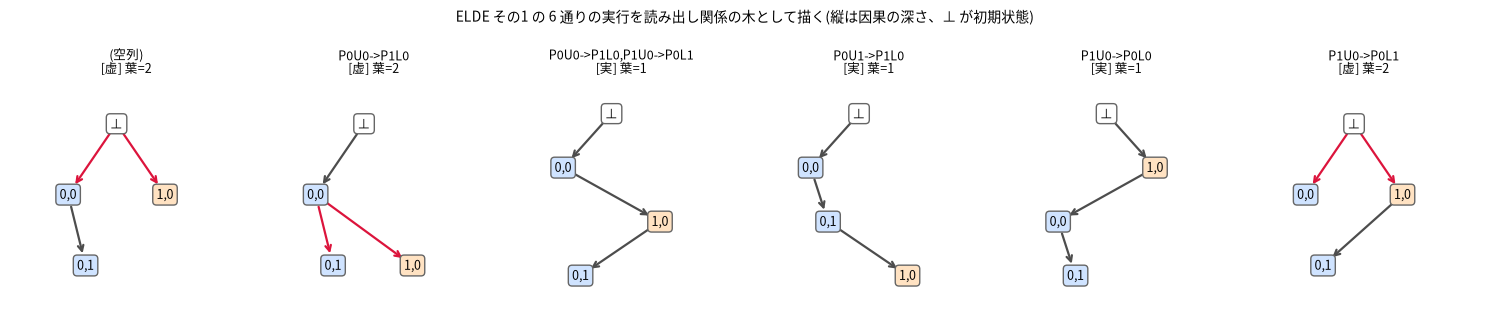

In [34]:
def depth_of(rf, v):
    d = 0
    while v != INIT:
        v = rf[v]; d += 1
    return d

def draw_rf(ax, rf, title="", P=None):
    if P is None:
        P = 1 + max(q for q, m in rf)
    rd = readers(rf)
    pos = {INIT: ((P - 1) / 2, 0)}
    for v in rf:
        q, m = v
        pos[v] = (q + 0.18 * m, -depth_of(rf, v))
    for v, par in rf.items():
        (x0, y0), (x1, y1) = pos[par], pos[v]
        col = "crimson" if rd[par] > 1 else "0.3"
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                    arrowprops=dict(arrowstyle="->", color=col, lw=1.6,
                                    shrinkA=9, shrinkB=9))
    for v, (x, y) in pos.items():
        lab = "⊥" if v == INIT else f"{v[0]},{v[1]}"
        fc = "white" if v == INIT else ["#cfe3ff", "#ffe2c2", "#d8f5d0"][v[0] % 3]
        ax.text(x, y, lab, ha="center", va="center", fontsize=9,
                bbox=dict(boxstyle="round,pad=0.3", fc=fc, ec="0.4"))
    ys = [y for x, y in pos.values()]
    ax.set_xlim(-0.6, P - 0.4 + 0.2); ax.set_ylim(min(ys) - 0.6, 0.6)
    ax.set_title(title, fontsize=9); ax.axis("off")

fig, axes = plt.subplots(1, 6, figsize=(15, 3.2))
for ax, sp in zip(axes, alive):
    rf = e0.rf_of(sp)
    kind = "実" if is_linear(rf) else "虚"
    draw_rf(ax, rf, f"{elde0_str(sp) or '(空列)'}\n[{kind}] 葉={len(leaves(rf))}", P=2)
fig.suptitle("ELDE その1 の 6 通りの実行を読み出し関係の木として描く(縦は因果の深さ、⊥ が初期状態)", fontsize=10)
plt.tight_layout(); plt.show()

### 4.2 定理 1

**定理 1(実実行の判定).** プロセスの CS 全体を $V$($|V|=N$)とし、$\mathrm{rf}: V \to V\cup\{\bot\}$ が、各 CS $(q,m)$ に「自分の直前の CS($m=0$ なら $\bot$)」か「他のプロセスの CS」を割り当て、プログラム順序と $\mathrm{rf}$ を合わせた関係が循環しないとする(ELDE その1 の実行はすべてこの形をしている)。このとき次は同値である。

1. $\mathrm{rf}$ はある実実行(CS の全順序で、各 CS が直前の CS の結果を読み、最初の CS が $\bot$ を読むもの)から来る。
2. $V\cup\{\bot\}$ のどの要素も、高々一度しか読まれない(子が高々一つ)。
3. 木の葉(誰にも読まれない状態)がちょうど一つ。

さらに、このとき実実行は $\mathrm{rf}$ から一意に決まる。

**証明.** (1⇒2) 実実行では各 CS の親は全順序での直前の CS で、直前が同じ CS は二つない。
(2⇒1) 子が高々一つなら、根から辿ると木は一本道 $\bot\to v_1\to\cdots\to v_N$ である(根付き木で分岐がなければ道)。この順に並べる。プログラム順序 $(q,m-1)\prec(q,m)$ がこの順と逆向きだとすると、道に沿った $\mathrm{rf}$ の辺とプログラム順序の辺で循環ができて仮定に反する。よってこの順はプログラム順序と両立し、各 CS は直前の CS の結果を読むから実実行である。
(2⇔3) 根付き木では「葉の数 $= 1 + \sum_{v} \max(c_v - 1, 0)$」($c_v$ は $v$ の子の数)が成り立つ(辺の数 $N$ $=$ 子の数の総和、頂点の数 $N+1$ $=$ 葉の数 $+$ 内部頂点の数、から出る)。よって葉が一つ ⇔ すべての $c_v\le 1$。∎

**Lean での形.** 下の Lean のセルの `ImagExec.T1.thm1`。「循環しない」は、それと同値な「rf の辺とプログラム順序の辺に沿って真に増える番号 $\rho$ がある」で表した。(2⇒1) の証明では、$\bot$ からの深さ(⊥ を読む CS が 1)を全順序に使う。どの状態も高々一度しか読まれないなら、深さが同じ CS は一つしかなく、深さの小さいものはすべて祖先になる。(2⇔3) は「葉の数 $+$ 読まれた状態の数 $= N+1$」という数え上げで示す。

$\ell - 1 = \sum_v \max(c_v-1,0)$ は「余分なコピーの回数」であり、**虚実行は $\ell$ 個の世界に分かれた実行** だと言える。葉の一つ一つがそれぞれの世界の最終状態である。

これで JRF の問 A に答えたことになる。判定は「各 unlock 状態を読んだ CS の数を数える」だけでよい。JRF が「難しい」と感じたのは、lock 仕様(受け渡しの列)だけを見ていたからだろう。lock 仕様には「自分の手元の状態で続けた」という既定の受け渡しが書かれていない。それを書き足して木にすると、判定は自明になる。

以下で、いくつかのプロセス構成について確かめる。`straight_procs(Ls)` は、プロセス $q$ がちょうど `Ls[q]` 回 CS を実行し、CS ごとに自分の印を状態に書き足していく直線的なプログラムである(状態が履歴をすべて覚えるので、違う実行は違う状態になる)。

In [35]:
print(f"{'Ls':>10} {'ELDE0':>6} {'うち線形':>6} {'実実行':>6}  一致")
for Ls in [(1, 1), (2, 1), (2, 2), (3, 2), (3, 3), (1, 1, 1), (2, 1, 1), (2, 2, 1)]:
    ps = straight_procs(Ls)
    e = Elde0(ps, list(Ls)); al = e.run()
    E0 = {canon(e.rf_of(s)) for s in al}
    lin = {k for k in E0 if is_linear(dict(k))}
    R = {r.key() for r in enumerate_real(ps)}
    print(f"{str(Ls):>10} {len(E0):>6} {len(lin):>8} {len(R):>8}  {lin == R}")

        Ls  ELDE0   うち線形    実実行  一致
    (1, 1)      3        2        2  True
    (2, 1)      6        3        3  True
    (2, 2)     19        6        6  True
    (3, 2)     45       10       10  True
    (3, 3)    141       20       20  True
 (1, 1, 1)     13        6        6  True
 (2, 1, 1)     39       12       12  True
 (2, 2, 1)    157       30       30  True


#### Lean: 定理 1(`lean/Thm1.lean`)

定理 1 の Lean 4 + Mathlib(v4.34.1)による証明。Lean のセルはどれも `test.lean` に書き出すだけで、検査はノートの最後(付録)でまとめて行う。最初のセルはファイルの頭(`import Mathlib`)も書く。

CS の集合を有限型 `V`、読み出し関係を `par : V → Option V`(`none` が ⊥)、プログラム順序を `po` で表す。`Causal` が「循環しない」、`IsReal` が実実行、`leaves` が葉の集合で、`thm1` が定理 1 である。

In [36]:
%%writefile test.lean
import Mathlib

set_option autoImplicit false
set_option linter.deprecated false

namespace ImagExec.T1

variable {V : Type}

/-- 因果的: rf の辺(読まれた側 → 読んだ側)と po の辺に沿って真に増える番号がある。 -/
def Causal (par : V → Option V) (po : V → V → Prop) : Prop :=
  ∃ ρ : V → ℕ, (∀ v u, par v = some u → ρ u < ρ v) ∧ (∀ u v, po u v → ρ u < ρ v)

/-- 全順序 σ で、v は σ で直前の CS(なければ ⊥)を読む。 -/
def ReadsPrev (σ : V → ℕ) (par : V → Option V) (v : V) : Prop :=
  match par v with
  | none => ∀ w, ¬ σ w < σ v
  | some u => σ u < σ v ∧ ∀ w, σ w < σ v → σ w ≤ σ u

/-- 実実行: CS の全順序(プログラム順序と両立)で、各 CS が直前の CS の結果を読むもの。 -/
def IsReal (par : V → Option V) (po : V → V → Prop) : Prop :=
  ∃ σ : V → ℕ, Function.Injective σ ∧ (∀ u v, po u v → σ u < σ v) ∧ ∀ v, ReadsPrev σ par v

/-- 葉: 誰にも読まれない状態(⊥ も含めて数える)。 -/
def leaves [Fintype V] [DecidableEq V] (par : V → Option V) : Finset (Option V) :=
  Finset.univ.filter (fun x => ∀ v, par v ≠ x)


Overwriting test.lean


In [37]:
%%writefile -a test.lean
/-! ### (2) ⇔ (3): どの状態も高々一度しか読まれない ⇔ 葉がちょうど一つ -/

theorem card_leaves [Fintype V] [DecidableEq V] (par : V → Option V) :
    (leaves par).card + (Finset.univ.image par).card = Fintype.card V + 1 := by
  classical
  have h : leaves par = Finset.univ \ Finset.univ.image par := by
    ext x; simp [leaves]
  rw [h, Finset.card_sdiff_of_subset (Finset.subset_univ _), Finset.card_univ,
    Fintype.card_option]
  have := Finset.card_le_univ (Finset.univ.image par)
  rw [Fintype.card_option] at this
  omega

theorem injective_iff_one_leaf [Fintype V] [DecidableEq V] (par : V → Option V) :
    Function.Injective par ↔ (leaves par).card = 1 := by
  have hc := card_leaves par
  have e : Function.Injective par ↔ (Finset.univ.image par).card = Fintype.card V := by
    rw [← Finset.card_univ, Finset.card_image_iff, Finset.coe_univ, Set.injOn_univ]
  rw [e]
  omega


Appending to test.lean


In [38]:
%%writefile -a test.lean
/-! ### (1) ⇒ (2): 実実行では、どの状態も高々一度しか読まれない -/

theorem real_injective {par : V → Option V} {po : V → V → Prop} (h : IsReal par po) :
    Function.Injective par := by
  obtain ⟨σ, hσ, -, hr⟩ := h
  intro a b hab
  by_contra hne
  have side : ∀ a b, σ a < σ b → par a = par b → False := by
    intro a b hlt he
    have ha := hr a
    have hb := hr b
    unfold ReadsPrev at ha hb
    rw [← he] at hb
    cases hpa : par a with
    | none => rw [hpa] at hb; exact hb a hlt
    | some u =>
      rw [hpa] at ha hb
      exact absurd (hb.2 a hlt) (not_le.mpr ha.1)
  rcases lt_or_gt_of_ne (fun h => hne (hσ h)) with h | h
  · exact side a b h hab
  · exact side b a h hab.symm


Appending to test.lean


In [39]:
%%writefile -a test.lean
/-! ### (2) ⇒ (1): 線形なら、根からの深さが実実行の順序になる -/

section Depth
variable (par : V → Option V) (ρ : V → ℕ) (hρ : ∀ v u, par v = some u → ρ u < ρ v)

/-- ⊥ からの深さ(⊥ を読む CS が 1)。 -/
def depth (par : V → Option V) (ρ : V → ℕ) (hρ : ∀ v u, par v = some u → ρ u < ρ v)
    (v : V) : ℕ :=
  match hp : par v with
  | none => 1
  | some u => depth par ρ hρ u + 1
termination_by ρ v
decreasing_by exact hρ v u hp

include hρ in
theorem depth_none {v : V} (h : par v = none) : depth par ρ hρ v = 1 := by
  rw [depth]; split <;> simp_all

include hρ in
theorem depth_some {v u : V} (h : par v = some u) :
    depth par ρ hρ v = depth par ρ hρ u + 1 := by
  rw [depth]; split <;> simp_all

include hρ in
theorem depth_pos (v : V) : 1 ≤ depth par ρ hρ v := by
  cases h : par v with
  | none => rw [depth_none par ρ hρ h]
  | some u => rw [depth_some par ρ hρ h]; omega

/-- 祖先(⊥ 側へたどれる CS、自分を含む)。 -/
inductive Anc : V → V → Prop
  | refl (v : V) : Anc v v
  | step {u v w : V} : par v = some u → Anc w u → Anc w v

include hρ in
/-- 深さ d(w) ≤ d(v) なら、v の祖先に深さ d(w) のものがいる。 -/
theorem exists_anc (v : V) : ∀ k, 1 ≤ k → k ≤ depth par ρ hρ v →
    ∃ a, Anc par a v ∧ depth par ρ hρ a = k := by
  induction v using (measure ρ).wf.induction with
  | h v ih =>
    intro k hk1 hk
    rcases Nat.lt_or_eq_of_le hk with hlt | heq
    · cases hp : par v with
      | none => rw [depth_none par ρ hρ hp] at hlt; omega
      | some u =>
        rw [depth_some par ρ hρ hp] at hlt
        obtain ⟨a, ha, hd⟩ := ih u (hρ v u hp) k hk1 (by omega)
        exact ⟨a, Anc.step hp ha, hd⟩
    · exact ⟨v, Anc.refl v, heq.symm⟩

include hρ in
theorem anc_rho {a v : V} (h : Anc par a v) : ρ a ≤ ρ v := by
  induction h with
  | refl => exact le_refl _
  | step hp _ ih => exact le_trans ih (hρ _ _ hp).le

include hρ in
theorem depth_injective (hinj : Function.Injective par) :
    Function.Injective (depth par ρ hρ) := by
  have key : ∀ k, ∀ a b, depth par ρ hρ a = k → depth par ρ hρ b = k → a = b := by
    intro k
    induction k with
    | zero => intro a _ ha _; have := depth_pos par ρ hρ a; omega
    | succ k ih =>
      intro a b ha hb
      cases hpa : par a with
      | none =>
        cases hpb : par b with
        | none => exact hinj (hpa.trans hpb.symm)
        | some ub =>
          rw [depth_none par ρ hρ hpa] at ha
          rw [depth_some par ρ hρ hpb] at hb
          have := depth_pos par ρ hρ ub; omega
      | some ua =>
        cases hpb : par b with
        | none =>
          rw [depth_some par ρ hρ hpa] at ha
          rw [depth_none par ρ hρ hpb] at hb
          have := depth_pos par ρ hρ ua; omega
        | some ub =>
          rw [depth_some par ρ hρ hpa] at ha
          rw [depth_some par ρ hρ hpb] at hb
          have := ih ua ub (by omega) (by omega)
          subst this
          exact hinj (hpa.trans hpb.symm)
  intro a b h
  exact key _ a b rfl h.symm

end Depth

theorem injective_real [Fintype V] {par : V → Option V} {po : V → V → Prop} (hc : Causal par po)
    (hinj : Function.Injective par) : IsReal par po := by
  obtain ⟨ρ, hρ, hpo⟩ := hc
  let d := depth par ρ hρ
  have dinj := depth_injective par ρ hρ hinj
  refine ⟨d, dinj, fun u v huv => ?_, fun v => ?_⟩
  · -- d(v) ≤ d(u) なら v は u の祖先で、po u v と合わせて循環する
    by_contra hc'
    push Not at hc'
    obtain ⟨a, ha, hd⟩ := exists_anc par ρ hρ u (d v) (depth_pos par ρ hρ v) hc'
    have : a = v := dinj hd
    subst this
    have := anc_rho par ρ hρ ha
    have := hpo u a huv
    omega
  · unfold ReadsPrev
    cases hp : par v with
    | none =>
      intro w hw
      have := depth_pos par ρ hρ w
      have := depth_none par ρ hρ hp
      simp only [d] at hw
      omega
    | some u =>
      have h1 := depth_some par ρ hρ hp
      refine ⟨by simp only [d]; omega, fun w hw => ?_⟩
      simp only [d] at hw ⊢
      omega

/-- **定理 1.** 因果的な rf について、次は同値:
(1) 実実行から来る、(2) どの状態も高々一度しか読まれない、(3) 葉がちょうど一つ。 -/
theorem thm1 [Fintype V] [DecidableEq V] (par : V → Option V) (po : V → V → Prop) (hc : Causal par po) :
    (IsReal par po ↔ Function.Injective par) ∧
    (Function.Injective par ↔ (leaves par).card = 1) :=
  ⟨⟨real_injective, injective_real hc⟩, injective_iff_one_leaf par⟩

end ImagExec.T1


Appending to test.lean


ELDE その1 の lock 仕様のうち、木が線形なものは、ELDE その3 の実実行とちょうど一対一に対応する。JRF はその3 で「elde_2.pl から elde_0.pl の lock 仕様への変換は割と簡単だが、逆は難しい」と書いた。逆向き(その1 の仕様のどれが実か)は、定理 1 で簡単に決まる。

### 4.3 JRF の「左開・右開」判定との関係

JRF は最初、「最初のロック」と「最後のロック」だけ調べればよいと考えた(日記 [cocolog:89156596] の「左開実行」「右開実行」)。木の言葉で言えば、

- 左の条件: $\bot$ を読む CS は一つだけ($\bot$ の子が一つ)。
- 右の条件: 誰にも読まれない「各プロセスの最後の CS」は一つだけ。

である。これは定理 1 の条件 2 を、根と、各プロセスの最後の CS についてだけ調べたものにあたる。JRF 自身が気づいたとおり、これだけでは足りない。途中の状態がコピーされる場合があるからである。何件すり抜けるか数えてみる。

In [40]:
def jrf_simple_ok(rf, Ls):
    rd = readers(rf)
    if rd[INIT] > 1:
        return False
    last_leaves = [q for q, L in enumerate(Ls) if rd[(q, L - 1)] == 0]
    return len(last_leaves) <= 1

for Ls in [(2, 2), (3, 2), (3, 3), (2, 2, 1)]:
    ps = straight_procs(Ls)
    I = [r for r in enumerate_imag(ps) if is_elde0(r.rf)]
    imag = [r for r in I if not is_linear(r.rf)]
    slip = [r for r in imag if jrf_simple_ok(r.rf, Ls)]
    print(f"Ls={Ls}: 虚実行 {len(imag)} 件のうち、左右の判定をすり抜けるもの {len(slip)} 件")
    if slip and Ls == (3, 3):
        ex = slip[0]
        print("   例:", elde0_str(cross_edges(ex.rf)))

Ls=(2, 2): 虚実行 13 件のうち、左右の判定をすり抜けるもの 2 件
Ls=(3, 2): 虚実行 35 件のうち、左右の判定をすり抜けるもの 9 件
Ls=(3, 3): 虚実行 121 件のうち、左右の判定をすり抜けるもの 38 件
   例: P0U0->P1L0,P0U2->P1L2
Ls=(2, 2, 1): 虚実行 127 件のうち、左右の判定をすり抜けるもの 10 件


すり抜ける例では、途中の CS の状態が「他のプロセスに渡され、かつ自分でも続けて使われる」。上の例 P0U0->P1L0,P0U2->P1L2 では、プロセス 0 の最初の状態がプロセス 1 に渡されたのに、プロセス 0 も同じ状態で続けている。JRF が 1.1 節の引用で最初に挙げた「間のロックに前後関係がない」場合は、木で見ればすべてこの「途中のコピー」である。

## §5 lock 仕様の特徴づけと数え上げ ―― 定理 2 と虚実行の階層

### 5.1 ELDE その1 の lock 仕様は何を表すか

ELDE その1 は、lock 仕様を次の条件で生成していた(`_make_lock_spec_tree`)。任意の $j<k$ について、

$$
p_k = p_j \Rightarrow n_k > n_j,\quad p_k = q_j \Rightarrow n_k \ge m_j,\quad q_k = q_j \Rightarrow m_k > m_j,\quad q_k = p_j \Rightarrow m_k > n_j .
$$

これは、プロセスごとに **局所時刻** を「lock $m$ は時刻 $2m$、unlock $n$ は時刻 $2n+1$」と決めると、仕様の各項 $\pi p\upsilon n\to\pi q\lambda m$ は「$p$ の時刻 $2n+1$ と $q$ の時刻 $2m$ を結ぶ受け渡し」で、**仕様の列は、関わる各プロセスの局所時刻について狭義に増加する**、という条件と同じである(上の四つの不等式を局所時刻に直すと、ちょうど狭義の増加になる)。

**定理 2(ELDE その1 の特徴づけ).** 定理 1 の設定の $\mathrm{rf}$ について、

1. $\mathrm{rf}$ が ELDE その1 の lock 仕様で表される ⇔ 他プロセスからの読み出し(受け渡し)全体に、各プロセスの局所時刻について狭義に単調な並べ方が存在する ⇔ 同じ局所時刻を二つの受け渡しが使わず、局所時刻の先後から作るグラフが循環しない。
2. lock 仕様から作る $\mathrm{rf}$ は、仕様に現れる受け渡しの **集合** だけで決まり、集合が違えば $\mathrm{rf}$ も違う。
3. プロセスが **3 個以下** なら、受け渡しの集合が同じ lock 仕様は一つしかない。したがって lock 仕様と $\mathrm{rf}$ は一対一に対応する。**4 個以上では一対一にならない。**

**証明.** (1) 仕様の列は定義により局所時刻について単調だから、衝突はなく、グラフの辺は列の中で前から後ろへ向かうので循環しない。逆に、条件を満たす受け渡しの集合からは、先行するもののない項(循環しないので有限集合には必ずある)を一つずつ取り出して並べれば(位相的整列)、仕様が得られる。(2) lock $(q,m)$ を受け取る受け渡しは、衝突がないので高々一つで、$\mathrm{rf}(q,m)$ はそれで決まる。逆に $\mathrm{rf}$ から受け渡しは読み取れる。(3) 3 プロセスなら、どの二つの受け渡しも(それぞれ 2 個のプロセスに関わるので)共通のプロセスを持ち、そこでの局所時刻の大小で順序が決まる。4 プロセスなら、$\pi0\upsilon0\to\pi1\lambda0$ と $\pi2\upsilon0\to\pi3\lambda0$ のように共通のプロセスを持たない二項は、どちらの順にも並べられ、同じ $\mathrm{rf}$ を与える二つの仕様になる。∎

0.1.0 では「一対一」をプロセス数の制限なしに述べていた。そこでは 3 プロセスまでしか総当りしていなかったため、この誤りに気づかなかった。Lean の証明を書く途中で、4 プロセスでは成り立たないことがわかった。§5.1 の終わりの Lean のセルの `valid_cond`・`cond_valid`(1)、`srcE_eq_iff`(2)、`valid_unique`・`not_unique_four`(3)が Lean の形である。`before_iff` は、JRF の生成規則の四つの不等式が「共有するどのプロセスでも局所時刻が増える」と同値であることを示す。

関数 `is_elde0` が (1) の条件の判定である。総当りで確かめる。最後の行が 4 プロセスの場合である。

In [41]:
print(f"{'Ls':>12} {'ELDE0 仕様数':>10} {'rf の種類':>8} {'定理2の条件を満たす rf':>16} 一致")
for Ls in [(1, 1), (2, 1), (2, 2), (3, 1), (3, 2), (3, 3), (1, 1, 1), (2, 1, 1), (2, 2, 1), (1, 1, 1, 1)]:
    ps = straight_procs(Ls)
    e = Elde0(ps, list(Ls)); al = e.run()
    E0 = {canon(e.rf_of(s)) for s in al}
    C = {r.key() for r in enumerate_imag(ps) if is_elde0(r.rf)}
    print(f"{str(Ls):>12} {len(al):>12} {len(E0):>10} {len(C):>18}   {E0 == C}")

          Ls  ELDE0 仕様数   rf の種類    定理2の条件を満たす rf 一致
      (1, 1)            3          3                  3   True
      (2, 1)            6          6                  6   True
      (2, 2)           19         19                 19   True
      (3, 1)           10         10                 10   True
      (3, 2)           45         45                 45   True
      (3, 3)          141        141                141   True
   (1, 1, 1)           13         13                 13   True
   (2, 1, 1)           39         39                 39   True
   (2, 2, 1)          157        157                157   True
(1, 1, 1, 1)           85         73                 73   True


3 プロセスまでは仕様の数と $\mathrm{rf}$ の種類が一致し、仕様 → $\mathrm{rf}$ は単射である。4 プロセス (1,1,1,1) では仕様が 85 通り、$\mathrm{rf}$ が 73 種類で、12 通りの重複がある。どの場合も、(1) の条件で判定した集合とは一致する。

重複の例を見ておく。

In [42]:
ps4 = straight_procs((1, 1, 1, 1))
e4 = Elde0(ps4, [1, 1, 1, 1]); al4 = e4.run()
by_rf = defaultdict(list)
for sp in al4:
    by_rf[canon(e4.rf_of(sp))].append(sp)
dups = [v for v in by_rf.values() if len(v) > 1]
print(f"仕様 {len(al4)} 通り、rf {len(by_rf)} 種類、二通りの仕様を持つ rf {len(dups)} 種類")
for v in dups[:3]:
    print("   ", "  と  ".join(elde0_str(sp) for sp in v))

仕様 85 通り、rf 73 種類、二通りの仕様を持つ rf 12 種類
    P0U0->P1L0,P2U0->P3L0  と  P2U0->P3L0,P0U0->P1L0
    P0U0->P1L0,P3U0->P2L0  と  P3U0->P2L0,P0U0->P1L0
    P0U0->P2L0,P1U0->P3L0  と  P1U0->P3L0,P0U0->P2L0


**lock 仕様と rf はどちらが情報を多く持つか.** 仕様には「自分の直前の状態を読む」が書かれていないが、それは仕様から決まるので、rf が仕様より多くを持つわけではない。仕様が rf より多く持つのは、上の例のような **共通のプロセスを持たない受け渡しの並び順** だけである。そしてその順序は、どの CS が受け取る状態にも、出力にも現れない。各 CS の入力は rf だけで決まるからである。独立な出来事の並び順の違いを同じものとみなすのは、Mazurkiewicz のトレース(1977)の考え方と同じで、rf は「同じとみなした後の形」にあたる。逆に rf は、仕様では書けない実行(§5.3 の T・I・B・L)も表せる。確かめておく。

In [43]:
ps = straight_procs((2, 1, 1, 1))
e = Elde0(ps, [2, 1, 1, 1]); al = e.run()
seen = defaultdict(set)
for sp in al:
    states = tuple(tuple(r) for r in e.run_spec(sp))     # 各プロセスの unlock 状態の列
    seen[canon(e.rf_of(sp))].add((states, e.outputs_of(sp)))
print(f"仕様 {len(al)} 通り、rf {len(seen)} 種類。同じ rf の仕様は状態も出力もすべて同じ: {all(len(v) == 1 for v in seen.values())}")

仕様 352 通り、rf 292 種類。同じ rf の仕様は状態も出力もすべて同じ: True


#### Lean: 定理 2(`lean/Thm23.lean` の前半)

プロセスを `Fin P`、プロセス `q` の CS の数を `L q` とする。lock 仕様の項 `Item`(`P{p}U{n}->P{q}L{m}`)は、プロセス `p` の局所時刻 `2n+1` と `q` の局所時刻 `2m` を占める(`time`)。`Before e e'` は「共有するどのプロセスでも局所時刻が増える」で、`before_iff` がそれと JRF の四つの不等式との同値を示す。`Valid L l` が ELDE その1 の生成する仕様、`Cond S` が定理 2 (1) の条件(衝突なし・非巡回)、`srcE l` が仕様から作る rf である。

- `valid_cond`・`cond_valid`: 定理 2 (1)
- `srcE_eq_iff`: 定理 2 (2)
- `valid_unique`(3 プロセス以下)・`not_unique_four`(4 プロセスの反例): 定理 2 (3)

In [44]:
%%writefile -a test.lean
namespace ImagExec

/-! ## 0. 共通の言葉

* プロセスは `Fin P`。プロセス `q` は `L q` 回クリティカルセクション(CS)を実行する。
* CS `(q, m)` の lock を局所時刻 `2m`、unlock を局所時刻 `2m+1` とする。
* 「読み出し元」`Src P := Option (Fin P × ℕ)`。`none` は初期状態 ⊥、
  `some (p, n)` はプロセス `p` の `n` 番目の unlock 状態。
-/

abbrev Src (P : ℕ) := Option (Fin P × ℕ)

/-- 自分の直前の状態(`m = 0` なら ⊥)。 -/
def own {P : ℕ} (q : Fin P) (m : ℕ) : Src P :=
  if m = 0 then none else some (q, m - 1)


Appending to test.lean


In [45]:
%%writefile -a test.lean
/-! ## 1. ELDE その1 の lock 仕様 -/

/-- lock 仕様の一項 `P{p}U{n}->P{q}L{m}`: プロセス `p` の unlock `n` の状態を、
プロセス `q` の lock `m` に渡す(受け渡し)。 -/
@[ext]
structure Item (P : ℕ) where
  p : Fin P
  n : ℕ
  q : Fin P
  m : ℕ
  hpq : p ≠ q
deriving DecidableEq

namespace Item
variable {P : ℕ}

/-- 項 `e` がプロセス `r` の局所時刻をどこで占めるか。 -/
def time (e : Item P) (r : Fin P) : Option ℕ :=
  if r = e.p then some (2 * e.n + 1) else if r = e.q then some (2 * e.m) else none

/-- 列の中で `e` が `e'` より前にあってよい条件: 共有するどのプロセスでも局所時刻が狭義に増える。 -/
def Before (e e' : Item P) : Prop :=
  ∀ r t t', e.time r = some t → e'.time r = some t' → t < t'

theorem time_p (e : Item P) : e.time e.p = some (2 * e.n + 1) := by simp [time]
theorem time_q (e : Item P) : e.time e.q = some (2 * e.m) := by
  simp [time, Ne.symm e.hpq]

/-- JRF の `_make_lock_spec_tree` の四つの不等式(任意の j < k について)。 -/
theorem before_iff (e e' : Item P) :
    Before e e' ↔
      (e'.p = e.p → e'.n > e.n) ∧ (e'.p = e.q → e'.n ≥ e.m) ∧
      (e'.q = e.q → e'.m > e.m) ∧ (e'.q = e.p → e'.m > e.n) := by
  constructor
  · intro h
    refine ⟨fun hh => ?_, fun hh => ?_, fun hh => ?_, fun hh => ?_⟩
    · have := h e.p _ _ (time_p e) (by rw [← hh]; exact time_p e'); omega
    · have := h e.q _ _ (time_q e) (by rw [← hh]; exact time_p e'); omega
    · have := h e.q _ _ (time_q e) (by rw [← hh]; exact time_q e'); omega
    · have := h e.p _ _ (time_p e) (by rw [← hh]; exact time_q e'); omega
  · rintro ⟨a, b, c, d⟩ r t t' ht ht'
    unfold time at ht ht'
    by_cases r1 : r = e.p
    · rw [if_pos r1] at ht; cases ht
      by_cases r3 : r = e'.p
      · rw [if_pos r3] at ht'; cases ht'; have := a (r3.symm.trans r1); omega
      · rw [if_neg r3] at ht'
        by_cases r4 : r = e'.q
        · rw [if_pos r4] at ht'; cases ht'; have := d (r4.symm.trans r1); omega
        · rw [if_neg r4] at ht'; cases ht'
    · rw [if_neg r1] at ht
      by_cases r2 : r = e.q
      · rw [if_pos r2] at ht; cases ht
        by_cases r3 : r = e'.p
        · rw [if_pos r3] at ht'; cases ht'; have := b (r3.symm.trans r2); omega
        · rw [if_neg r3] at ht'
          by_cases r4 : r = e'.q
          · rw [if_pos r4] at ht'; cases ht'; have := c (r4.symm.trans r2); omega
          · rw [if_neg r4] at ht'; cases ht'
      · rw [if_neg r2] at ht; cases ht

theorem not_before_self (e : Item P) : ¬ Before e e := by
  intro h; have := h e.p _ _ (time_p e) (time_p e); omega

end Item

open Item

/-- 局所時刻を共有する(どちらの順にも並べられない)二項。 -/
def Prec {P : ℕ} (e e' : Item P) : Prop :=
  ∃ r t t', e.time r = some t ∧ e'.time r = some t' ∧ t < t'

/-- ELDE その1 が生成する(切られない)lock 仕様: 列が `Before` について pairwise で、
各項が lock 回数の範囲に収まる。 -/
def Valid {P : ℕ} (L : Fin P → ℕ) (l : List (Item P)) : Prop :=
  l.Pairwise Before ∧ ∀ e ∈ l, e.n < L e.p ∧ e.m < L e.q

/-- 定理 2 の条件(受け渡しの集合 `S` について):
(衝突なし)同じ局所時刻を二つの項が使わない、
(非巡回)局所時刻の先後から作るグラフが循環しない。 -/
def Cond {P : ℕ} (S : Finset (Item P)) : Prop :=
  (∀ e ∈ S, ∀ e' ∈ S, ∀ r t, e.time r = some t → e'.time r = some t → e = e') ∧
  (∀ e ∈ S, ¬ Relation.TransGen (fun a b => a ∈ S ∧ b ∈ S ∧ Prec a b) e e)

/-- lock 仕様から読み出し関係 rf を作る: `(q, m)` を lock 側に持つ項があればその unlock 状態、
なければ自分の直前の状態。 -/
def srcE {P : ℕ} (l : List (Item P)) (q : Fin P) (m : ℕ) : Src P :=
  match l.find? (fun e => decide (e.q = q ∧ e.m = m)) with
  | some e => some (e.p, e.n)
  | none => own q m


Appending to test.lean


In [46]:
%%writefile -a test.lean
/-! ## 2. 定理 2 -/

section Thm2
variable {P : ℕ}

theorem valid_nodup_rel {L : Fin P → ℕ} {l : List (Item P)} (hl : Valid L l)
    {e e' : Item P} (he : e ∈ l) (he' : e' ∈ l) (hne : e ≠ e') :
    Before e e' ∨ Before e' e := by
  obtain ⟨i, hi, rfl⟩ := List.getElem_of_mem he
  obtain ⟨j, hj, rfl⟩ := List.getElem_of_mem he'
  have hp := List.pairwise_iff_getElem.mp hl.1
  rcases lt_trichotomy i j with h | h | h
  · exact Or.inl (hp i j hi hj h)
  · subst h; exact absurd rfl hne
  · exact Or.inr (hp j i hj hi h)

/-- 定理 2(a) 前半: ELDE その1 の lock 仕様の受け渡しの集合は条件を満たす。 -/
theorem valid_cond {L : Fin P → ℕ} {l : List (Item P)} (hl : Valid L l) :
    Cond l.toFinset := by
  constructor
  · intro e he e' he' r t h1 h2
    simp only [List.mem_toFinset] at he he'
    by_contra hne
    rcases valid_nodup_rel hl he he' hne with h | h
    · have := h r t t h1 h2; omega
    · have := h r t t h2 h1; omega
  · -- 位置 idxOf が真に増える
    have key : ∀ a b, (a ∈ l.toFinset ∧ b ∈ l.toFinset ∧ Prec a b) →
        l.idxOf a < l.idxOf b := by
      rintro a b ⟨ha, hb, r, t, t', h1, h2, h3⟩
      simp only [List.mem_toFinset] at ha hb
      have hia := List.idxOf_lt_length_of_mem ha
      have hib := List.idxOf_lt_length_of_mem hb
      have ea : l[l.idxOf a] = a := List.getElem_idxOf hia
      have eb : l[l.idxOf b] = b := List.getElem_idxOf hib
      have hp := List.pairwise_iff_getElem.mp hl.1
      rcases lt_trichotomy (l.idxOf a) (l.idxOf b) with h | h | h
      · exact h
      · exfalso
        have : a = b := by rw [← ea, ← eb]; simp [h]
        subst this; rw [h1] at h2; cases h2; omega
      · exfalso
        have := hp _ _ hib hia h
        rw [ea, eb] at this
        have := this r t' t h2 h1; omega
    intro e _ h
    have : ∀ a b, Relation.TransGen
        (fun a b => a ∈ l.toFinset ∧ b ∈ l.toFinset ∧ Prec a b) a b →
        l.idxOf a < l.idxOf b := by
      intro a b hab
      induction hab with
      | single h => exact key _ _ h
      | tail _ h ih => exact lt_trans ih (key _ _ h)
    exact lt_irrefl _ (this e e h)

theorem cond_mono {S T : Finset (Item P)} (h : S ⊆ T) (hT : Cond T) : Cond S := by
  refine ⟨fun e he e' he' => hT.1 e (h he) e' (h he'), fun e he hc => hT.2 e (h he) ?_⟩
  exact Relation.TransGen.mono (p := fun a b => a ∈ T ∧ b ∈ T ∧ Prec a b)
    (fun _ _ hab => ⟨h hab.1, h hab.2.1, hab.2.2⟩) e e hc

/-- 有限で非巡回なら、前に何も来ない(極小な)項がある。 -/
theorem exists_minimal {S : Finset (Item P)} (hS : Cond S) (hne : S.Nonempty) :
    ∃ e ∈ S, ∀ e' ∈ S, ¬ Prec e' e := by
  classical
  let R : S → S → Prop := fun a b =>
    Relation.TransGen (fun a b => a ∈ S ∧ b ∈ S ∧ Prec a b) a.1 b.1
  have : IsTrans S R := ⟨fun _ _ _ h1 h2 => Relation.TransGen.trans h1 h2⟩
  have : Std.Irrefl R := ⟨fun a h => hS.2 a.1 a.2 h⟩
  have wf : WellFounded R := Finite.wellFounded_of_trans_of_irrefl R
  obtain ⟨x, hx⟩ := hne
  obtain ⟨m, -, hm⟩ := wf.has_min Set.univ ⟨⟨x, hx⟩, trivial⟩
  refine ⟨m.1, m.2, fun e' he' hp => hm ⟨e', he'⟩ trivial ?_⟩
  exact Relation.TransGen.single ⟨he', m.2, hp⟩

/-- 定理 2(a) 後半: 条件を満たす受け渡しの集合は、ELDE その1 の lock 仕様として並べられる
(位相的整列)。 -/
theorem cond_valid (L : Fin P → ℕ) (S : Finset (Item P)) (hS : Cond S)
    (hb : ∀ e ∈ S, e.n < L e.p ∧ e.m < L e.q) :
    ∃ l : List (Item P), Valid L l ∧ l.toFinset = S := by
  classical
  induction hc : S.card generalizing S with
  | zero =>
    refine ⟨[], ⟨List.Pairwise.nil, by simp⟩, ?_⟩
    rw [Finset.card_eq_zero] at hc; simp [hc]
  | succ k ih =>
    have hne : S.Nonempty := by
      rw [← Finset.card_pos]; omega
    obtain ⟨e, he, hmin⟩ := exists_minimal hS hne
    obtain ⟨l', ⟨hp', hb'⟩, hl'⟩ := ih (S.erase e) (cond_mono (Finset.erase_subset _ _) hS)
      (fun x hx => hb x (Finset.mem_of_mem_erase hx)) (by rw [Finset.card_erase_of_mem he]; omega)
    refine ⟨e :: l', ⟨?_, ?_⟩, ?_⟩
    · refine List.Pairwise.cons (fun x hx => ?_) hp'
      have hx' : x ∈ S.erase e := by rw [← hl']; simpa using hx
      have hxe : x ≠ e := Finset.ne_of_mem_erase hx'
      have hxS := Finset.mem_of_mem_erase hx'
      intro r t t' h1 h2
      rcases lt_trichotomy t t' with h | h | h
      · exact h
      · subst h; exact absurd (hS.1 e he x hxS r t h1 h2).symm hxe
      · exact absurd ⟨r, t', t, h2, h1, h⟩ (hmin x hxS)
    · intro x hx
      rcases List.mem_cons.mp hx with rfl | hx
      · exact hb x he
      · exact hb' x hx
    · rw [List.toFinset_cons, hl', Finset.insert_erase he]

/-- `srcE` の性質: lock 側に `(q,m)` を持つ項があればその unlock 状態を読む。 -/
theorem srcE_of_mem {L : Fin P → ℕ} {l : List (Item P)} (hl : Valid L l) {e : Item P}
    (he : e ∈ l) : srcE l e.q e.m = some (e.p, e.n) := by
  unfold srcE
  cases hf : l.find? (fun x => decide (x.q = e.q ∧ x.m = e.m)) with
  | none =>
    rw [List.find?_eq_none] at hf
    exact absurd (by simp) (hf e he)
  | some x =>
    have hx := List.mem_of_find?_eq_some hf
    have hpx := List.find?_some hf
    simp only [decide_eq_true_eq] at hpx
    have : x = e := (valid_cond hl).1 x (by simpa using hx) e (by simpa using he) e.q (2 * e.m)
      (by rw [← hpx.1, ← hpx.2]; exact time_q x) (time_q e)
    subst this; rfl

theorem srcE_of_not_mem {l : List (Item P)} {q : Fin P} {m : ℕ}
    (h : ∀ e ∈ l, ¬ (e.q = q ∧ e.m = m)) : srcE l q m = own q m := by
  unfold srcE
  have : l.find? (fun e => decide (e.q = q ∧ e.m = m)) = none := by
    rw [List.find?_eq_none]; intro x hx; simpa using h x hx
  rw [this]

theorem own_ne_cross {q p : Fin P} {m n : ℕ} (h : p ≠ q) : own q m ≠ some (p, n) := by
  unfold own; split_ifs <;> simp [Ne.symm h]

/-- 定理 2(b): lock 仕様 → rf は、受け渡しの集合だけで決まり、集合が違えば rf も違う。 -/
theorem srcE_eq_iff {L : Fin P → ℕ} {l₁ l₂ : List (Item P)} (h₁ : Valid L l₁)
    (h₂ : Valid L l₂) : (∀ q m, srcE l₁ q m = srcE l₂ q m) ↔ (∀ e, e ∈ l₁ ↔ e ∈ l₂) := by
  have half : ∀ {l₁ l₂ : List (Item P)}, Valid L l₁ → Valid L l₂ →
      (∀ q m, srcE l₁ q m = srcE l₂ q m) → ∀ e, e ∈ l₁ → e ∈ l₂ := by
    intro l₁ l₂ h₁ h₂ H e he
    have h := H e.q e.m
    rw [srcE_of_mem h₁ he] at h
    by_cases hx : ∃ x ∈ l₂, x.q = e.q ∧ x.m = e.m
    · obtain ⟨x, hx, hq, hm⟩ := hx
      have h' := srcE_of_mem h₂ hx
      rw [hq, hm, ← h] at h'
      simp only [Option.some.injEq, Prod.mk.injEq] at h'
      have : x = e := Item.ext h'.1.symm h'.2.symm hq hm
      exact this ▸ hx
    · push Not at hx
      rw [srcE_of_not_mem (fun x hx' hh => hx x hx' hh.1 hh.2)] at h
      exact absurd h.symm (own_ne_cross e.hpq)
  constructor
  · intro H e
    exact ⟨half h₁ h₂ H e, half h₂ h₁ (fun q m => (H q m).symm) e⟩
  · intro H q m
    by_cases hx : ∃ x ∈ l₁, x.q = q ∧ x.m = m
    · obtain ⟨x, hx, rfl, rfl⟩ := hx
      rw [srcE_of_mem h₁ hx, srcE_of_mem h₂ ((H x).mp hx)]
    · push Not at hx
      rw [srcE_of_not_mem (fun x hx' hh => hx x hx' hh.1 hh.2),
        srcE_of_not_mem (fun x hx' hh => hx x ((H x).mpr hx') hh.1 hh.2)]

/-- 3 プロセス以下では、どの二項も必ずどこかのプロセスを共有する。 -/
theorem share_of_le_three (hP : P ≤ 3) (e e' : Item P) :
    ∃ r t t', e.time r = some t ∧ e'.time r = some t' := by
  have h1 := e.hpq; have h2 := e'.hpq
  have : e.p = e'.p ∨ e.p = e'.q ∨ e.q = e'.p ∨ e.q = e'.q := by
    rw [Fin.ext_iff, Fin.ext_iff, Fin.ext_iff, Fin.ext_iff]
    rw [Ne, Fin.ext_iff] at h1 h2
    have := e.p.2; have := e.q.2; have := e'.p.2; have := e'.q.2
    omega
  rcases this with h | h | h | h
  · exact ⟨e.p, _, _, time_p e, by rw [h]; exact time_p e'⟩
  · exact ⟨e.p, _, _, time_p e, by rw [h]; exact time_q e'⟩
  · exact ⟨e.q, _, _, time_q e, by rw [h]; exact time_p e'⟩
  · exact ⟨e.q, _, _, time_q e, by rw [h]; exact time_q e'⟩

/-- 定理 2(c): 3 プロセス以下では、受け渡しの集合が同じ lock 仕様は列として一つしかない。
したがって lock 仕様と rf は一対一に対応する。 -/
theorem valid_unique (hP : P ≤ 3) {L : Fin P → ℕ} :
    ∀ {l₁ l₂ : List (Item P)}, Valid L l₁ → Valid L l₂ → (∀ e, e ∈ l₁ ↔ e ∈ l₂) → l₁ = l₂ := by
  intro l₁
  induction l₁ with
  | nil =>
    intro l₂ _ _ H
    cases l₂ with
    | nil => rfl
    | cons b t => exact absurd ((H b).mpr (by simp)) (by simp)
  | cons a t₁ ih =>
    intro l₂ h₁ h₂ H
    cases l₂ with
    | nil => exact absurd ((H a).mp (by simp)) (by simp)
    | cons b t₂ =>
      have hp₁ := List.pairwise_cons.mp h₁.1
      have hp₂ := List.pairwise_cons.mp h₂.1
      have v₁ : Valid L t₁ := ⟨hp₁.2, fun e he => h₁.2 e (by simp [he])⟩
      have v₂ : Valid L t₂ := ⟨hp₂.2, fun e he => h₂.2 e (by simp [he])⟩
      have hab : a = b := by
        by_contra hne
        have hb : b ∈ t₁ := by
          have := (H b).mpr (by simp)
          rcases List.mem_cons.mp this with h | h
          · exact absurd h.symm hne
          · exact h
        have ha : a ∈ t₂ := by
          have := (H a).mp (by simp)
          rcases List.mem_cons.mp this with h | h
          · exact absurd h hne
          · exact h
        have x := hp₁.1 b hb
        have y := hp₂.1 a ha
        obtain ⟨r, t, t', h1, h2⟩ := share_of_le_three hP a b
        have := x r t t' h1 h2; have := y r t' t h2 h1; omega
      subst hab
      have na₁ : a ∉ t₁ := fun h => not_before_self a (hp₁.1 a h)
      have na₂ : a ∉ t₂ := fun h => not_before_self a (hp₂.1 a h)
      congr 1
      refine ih v₁ v₂ (fun e => ?_)
      constructor
      · intro he
        have hne : e ≠ a := fun h => na₁ (h ▸ he)
        have := (H e).mp (by simp [he])
        rcases List.mem_cons.mp this with h | h
        · exact absurd h hne
        · exact h
      · intro he
        have hne : e ≠ a := fun h => na₂ (h ▸ he)
        have := (H e).mpr (by simp [he])
        rcases List.mem_cons.mp this with h | h
        · exact absurd h hne
        · exact h

/-- 定理 2(c) の限界: 4 プロセスでは、共通のプロセスを持たない二項はどちらの順にも並べられ、
同じ rf を与える二つの lock 仕様ができる(report0 の「一対一」は 3 プロセスまで)。 -/
theorem not_unique_four :
    ∃ l₁ l₂ : List (Item 4), Valid (fun _ => 1) l₁ ∧ Valid (fun _ => 1) l₂ ∧
      l₁ ≠ l₂ ∧ ∀ q m, srcE l₁ q m = srcE l₂ q m := by
  let e₁ : Item 4 := ⟨0, 0, 1, 0, by decide⟩
  let e₂ : Item 4 := ⟨2, 0, 3, 0, by decide⟩
  have b₁ : Before e₁ e₂ := by
    intro r t t' h1 h2
    simp only [Item.time, e₁, e₂] at h1 h2
    fin_cases r <;> simp_all
  have b₂ : Before e₂ e₁ := by
    intro r t t' h1 h2
    simp only [Item.time, e₁, e₂] at h1 h2
    fin_cases r <;> simp_all
  have v₁ : Valid (fun _ => 1) [e₁, e₂] :=
    ⟨by simp [b₁], by intro e he; simp at he; rcases he with rfl | rfl <;> simp [e₁, e₂]⟩
  have v₂ : Valid (fun _ => 1) [e₂, e₁] :=
    ⟨by simp [b₂], by intro e he; simp at he; rcases he with rfl | rfl <;> simp [e₁, e₂]⟩
  refine ⟨[e₁, e₂], [e₂, e₁], v₁, v₂, by simp [e₁, e₂], ?_⟩
  exact (srcE_eq_iff v₁ v₂).mpr (fun e => by simp [or_comm])

end Thm2


Appending to test.lean


### 5.2 2 プロセスの場合の数え上げ

2 プロセスなら、仕様は「プロセス 0 の局所時刻 $0,\dots,2a-1$ と、プロセス 1 の局所時刻 $0,\dots,2b-1$ を、偶奇が異なる点どうし、交差しないように結ぶ部分マッチング」になる(受け渡しは必ず一方の unlock(奇数)と他方の lock(偶数)を結ぶ)。$f(i,j)$ を「プロセス 0 の最初の $i$ 点とプロセス 1 の最初の $j$ 点の間の、そういうマッチングの数」とすると、包除原理で

$$
f(i,j) = f(i-1,j) + f(i,j-1) - f(i-1,j-1) + [\,i-1 \not\equiv j-1 \pmod 2\,]\; f(i-1,j-1),\qquad f(i,0)=f(0,j)=1
$$

となり、ELDE その1 の仕様数は $f(2a,2b)$ である。これは Delannoy 数(斜めの一歩を許す格子路の数)の漸化式で、斜めの一歩を偶奇の異なる点にだけ許したものである。

**閉じた式.** 漸化式を書き直すと $f(i,j) = f(i-1,j) + f(i,j-1) - [\,i \equiv j \pmod 2\,]\, f(i-1,j-1)$ で、母関数 $F(x,y) = \sum f(i,j)x^iy^j$ と、そのうち $i \equiv j$ の項だけを集めた $D(x,y) = (F(x,y) + F(-x,-y))/2$ について $F\,(1 - x - y) + xy\,D = 1$ が成り立つ。$(x,y)$ を $(-x,-y)$ に換えた式と連立させて解くと

$$ F(x,y) = \frac{1 + x + y}{1 - x^2 - xy - y^2} $$

となる。$f(2a,2b)$ は全体の次数が偶数の係数なので分子の $1$ だけが効き、$(x^2 + xy + y^2)^{a+b}$ の $x^{2a}y^{2b}$ の係数として

$$ f(2a,2b) = \sum_{m=0}^{\min(a,b)} \frac{(a+b)!}{(a-m)!\,(b-m)!\,(2m)!} $$

を得る($m$ は、$(x^2 + xy + y^2)^{a+b}$ を展開するときに $xy$ を選ぶ回数 $2m$ の半分)。対角線では、和の最大の項は $m \approx a/3$ にあり、鞍点の評価から

$$ f(2a,2a) \sim \sqrt{\frac{3}{8\pi a}}\; 9^a $$

となる。実実行の数 $\binom{2a}{a} \sim 4^a/\sqrt{\pi a}$ との比は $\sqrt{3/8}\,(9/4)^a$ で、指数関数的に開く。

In [47]:
print("漸化式 f(2a,2b):")
for a in range(1, 6):
    print("  a=%d:" % a, [elde0_count_2(a, b) for b in range(1, 6)])
print("総当りとの照合:", all(elde0_count_2(a, b) == len(Elde0(straight_procs((a, b)), [a, b]).run())
                         for a, b in [(1, 1), (2, 1), (2, 2), (3, 2), (3, 3)]))
print()
print("対角線 a=b:  ELDE0 仕様数 vs 実実行数 C(2a,a)")
for a in range(1, 9):
    print(f"  a={a}: {elde0_count_2(a, a):>12}  {math.comb(2*a, a):>8}   比 {elde0_count_2(a, a)/math.comb(2*a, a):8.1f}")
print()
# 閉じた式 Σ (a+b)!/((a-m)!(b-m)!(2m)!) と、漸近式 √(3/(8πa))·9^a
from fractions import Fraction
closed = lambda a, b: sum(math.factorial(a + b) // (math.factorial(a - m) * math.factorial(b - m) * math.factorial(2 * m))
                          for m in range(min(a, b) + 1))
print("閉じた式と漸化式の一致(a, b ≦ 7):", all(closed(a, b) == elde0_count_2(a, b) for a in range(1, 8) for b in range(1, 8)))
for a in [10, 100, 1000]:
    v = closed(a, a)
    print(f"  a={a:>4}: 倍率 f(2a,2a)/f(2a-2,2a-2) = {v / closed(a - 1, a - 1):.4f},  f(2a,2a)/(√(3/(8πa))·9^a) = "
          f"{float(Fraction(v, 9 ** a)) / math.sqrt(3 / (8 * math.pi * a)):.5f}")

漸化式 f(2a,2b):
  a=1: [3, 6, 10, 15, 21]
  a=2: [6, 19, 45, 90, 161]
  a=3: [10, 45, 141, 357, 784]
  a=4: [15, 90, 357, 1107, 2907]
  a=5: [21, 161, 784, 2907, 8953]
総当りとの照合: True

対角線 a=b:  ELDE0 仕様数 vs 実実行数 C(2a,a)
  a=1:            3         2   比      1.5
  a=2:           19         6   比      3.2
  a=3:          141        20   比      7.0
  a=4:         1107        70   比     15.8
  a=5:         8953       252   比     35.5
  a=6:        73789       924   比     79.9
  a=7:       616227      3432   比    179.6
  a=8:      5196627     12870   比    403.8

閉じた式と漸化式の一致(a, b ≦ 7): True
  a=  10: 倍率 f(2a,2a)/f(2a-2,2a-2) = 8.5471,  f(2a,2a)/(√(3/(8πa))·9^a) = 0.99063
  a= 100: 倍率 f(2a,2a)/f(2a-2,2a-2) = 8.9550,  f(2a,2a)/(√(3/(8πa))·9^a) = 0.99906


  a=1000: 倍率 f(2a,2a)/f(2a-2,2a-2) = 8.9955,  f(2a,2a)/(√(3/(8πa))·9^a) = 0.99991


実実行の数は二項係数 $\binom{a+b}{a}$(CS の並べ方)で、およそ $4^a$ で増える。ELDE その1 の仕様数は、$a$ が一つ増えるごとに 8 倍を超える勢いで増え、その倍率は $1/\sqrt{a}$ の補正のためにゆっくり 9 に近づく(漸近式どおり)。実実行との比はどんどん開く。JRF の言う「余計なものまで(大量に)チェックしている」は定量的にもそのとおりである。

### 5.3 虚実行の階層

ELDE その1 は「虚」の一つの切り方にすぎない。制約を順に緩めると、次の階層ができる。

| 記号 | 名前 | 各 CS が読めるもの | 備考 |
|---|---|---|---|
| R | 実実行 | 全順序での直前の CS | ELDE その3 |
| E0 | ELDE その1 | 自分の直前、または他者からの受け渡し(定理 2 の条件つき) | |
| T | トンネル実行 | 排他を無視して動き、lock の時点で最新の unlock 状態 | §6。2 プロセスでは E0 = T |
| I | 因果的コピー | 自分の直前、または既に書かれた他者の任意の状態 | プログラム順序 ∪ rf が非巡回 |
| B | 時間逆行 | I と同じ候補だが、rf だけが非巡回ならよい | 自分の後の CS の影響を、前の CS が受けうる |
| L | 時間ループ | 候補から任意に | rf の循環 = 未来の自分の出力を読む |

別の系統として、分散システムの **fork 線形化可能性**(Mazières & Shasha 2002)に対応する「各プロセスが自分の枝から離れない」虚実行 Fk もある。悪意のあるサーバーが利用者ごとに別の歴史を見せる(fork させる)状況のモデルで、一度分かれた利用者は互いの更新を二度と見ない。ELDE その1 の虚実行は、他人の枝に乗り移ることができる(自分のそれまでの書き込みを失う)点で、これとも違う。

In [48]:
print(f"{'Ls':>10} {'R':>5} {'E0':>6} {'T':>6} {'I':>6} {'B':>7} {'L':>8} | {'Fk':>5}")
for Ls in [(1, 1), (2, 1), (2, 2), (3, 2), (1, 1, 1), (2, 1, 1), (3, 3), (2, 2, 1)]:
    ps = straight_procs(Ls)
    Rs = {r.key() for r in enumerate_real(ps)}
    I_ = enumerate_imag(ps)
    Is = {r.key() for r in I_}
    E0s = {r.key() for r in I_ if is_elde0(r.rf)}
    Ts = set(tunnel_paths(Ls))
    assert Rs <= E0s <= Ts <= Is          # 集合としての包含
    Fk = len(enumerate_imag(ps, level="fork"))
    B, L = count_rf_only(Ls)
    print(f"{str(Ls):>10} {len(Rs):>5} {len(E0s):>6} {len(Ts):>6} {len(Is):>6} {B:>7} {L:>8} | {Fk:>5}")

        Ls     R     E0      T      I       B        L |    Fk
    (1, 1)     2      3      3      3       3        4 |     3
    (2, 1)     3      6      6      7       7       12 |     5
    (2, 2)     6     19     19     30      32       81 |    11
    (3, 2)    10     45     45    108     126      432 |    19
 (1, 1, 1)     6     13     16     16      16       27 |    16
 (2, 1, 1)    12     39     51     63      65      144 |    37
    (3, 3)    20    141    141    594     847     4096 |    39
 (2, 2, 1)    30    157    227    378     425     1280 |   104


いずれも $R \subseteq E0 \subseteq T \subseteq I \subseteq B \subseteq L$ が成り立つ。前の四つの包含は上のセルで集合として確かめており(`assert`)、$I\subseteq B\subseteq L$ は定義から明らかである。2 プロセスでは $E0 = T$ で(定理 3 (i))、3 プロセスでは $E0 \subsetneq T$ になる。ELDE その1 は、3 プロセス以上では「一つの unlock 状態を二つの他プロセスへ渡す」ことを許していない(局所時刻が衝突する)からである。

### 5.4 虚実行と「ほかの cut」の違い(問 B への答え)

ELDE その1 の実行中に cut されるものは二種類あった。

1. **lock 仕様が長すぎる**(`lock spec is too long`): 実際には起きない unlock の状態を渡そうとしている。
2. **途中で終わった**: 仕様が、実行されなかった lock を参照している。

これらは「存在しない出来事」を参照しており、**局所的に** 意味をなさない。それに対して虚実行は、

- どの CS も、実際に存在し、自分より前に書かれた状態を読んでいる(局所的には完全に正しい)。
- ただ、全体として「一つの状態は一度しか使えない」という **大域的な保存則(線形性)** を破っている。

という点で、まったく性格が違う。数学でよく出てくる「拡張概念」は、たいていこの型をしている。

- 負の数: 「引き算はいつでもできる」という局所的な規則は残し、「量は 0 以上」という大域的な制約を捨てる。
- 虚数: 「方程式はいつでも解ける」を残し、「2 乗すれば 0 以上」を捨てる。
- 確率論の **局所整合な擬似周辺分布**(グラフィカルモデルの Bethe 近似などで現れる): どの小部分の分布も互いに整合しているのに、それらをまとめる全体の分布は存在しない(Wainwright & Jordan 2008)。
- 量子力学の **擬確率分布**(Wigner 関数): 周辺分布は正しいが、全体は負の値をとりうる。

JRF は 2022 年に、ホフスタッター『GEB』の「超自然数」を読んで、虚実行もこうした「拡張概念」の一つにすぎないのかもしれない、と書いた。上の整理でいえば、**虚実行は「局所的には正しく、大域的な線形性だけを破る実行」として、きちんと特定された拡張概念である**。その意味で、ほかの cut とは明確に区別できる。

### 5.5 階層の上では、実行は「一周して整合するもの」として決まる

§5.3 の表の B(時間逆行)と L(時間ループ)は、JRF の言う虚実行をさらに押し広げたものである。虚実行は「状態をコピーしてよい」実行だったが、B と L では、まだ書かれていない状態(相手や自分の **未来** の出力)まで読んでよい。表ではこれらを数えただけだったが、ここに大事な違いがある。**B と L では、プロセスを前から順に走らせて実行を決めることができない。一周して元に戻る(自己無撞着な)状態の組だけが、実行として存在する。**

理由を見るために、出力が何に依存するかを考える。ELDE のプロセスには局所変数があるので、CS $(q,m)$ の出力(unlock の状態)は、$(q,m)$ 自身が読んだ状態だけでなく、同じプロセスのそれより前の CS が読んだ状態にも依存する(たとえば §7.2 の二段階の加算は、前の CS で覚えた値を次の CS で書く)。したがって依存関係は

- **rf の辺**: $\mathrm{rf}(v)$ の出力が、$v$ の入力になる。
- **プログラム順序(po)の辺**: $(q,m-1)$ までの入力が、$(q,m)$ の出力に効く。

を合わせたものになる。

**定理 4(実行の決まり方).** rf を一つ固定する。

1. rf ∪ po が循環しない(階層の I 以下)なら、どんな決定的なプロセスでも、その rf の実行(各 CS が受け取る状態の組)は **ちょうど一つ** ある。前から順に計算すればよい。
2. rf ∪ po が循環する(B または L)なら、ある決定的なプロセスでは実行が **一つもなく**、別のプロセスでは **二つ以上** ある。実行は、各 CS の入力についての連立方程式「$v$ の入力 $= \mathrm{rf}(v)$ の出力」の解(不動点)として決まる。

**証明.** (1) rf ∪ po の位相的な順に、各 CS の入力を「rf の親の出力」として計算していける。親の出力はそれより前の入力だけで決まるから、値は一通りに決まる。(2) 循環のうち最短のものを一つとる。その上の各 CS が、循環の一つ手前の入力だけを(局所変数に覚えるなどして)そのまま出力し、循環の外の CS は定数を出力するようにプロセスを書く。状態を $\{0,1\}$ とすると、すべて素通しなら循環は 0 と 1 のどちらでも整合し(解が二つ)、一か所だけ $0\leftrightarrow1$ を入れ替えれば整合する値がない(解がない)。最短の循環をとるのは、一つの CS の出力に二つの役目を負わせないためである。∎

Lean では、(1) を入力の依存関係に沿った整礎な再帰として、(2) を状態を整数にして「循環を含む強連結な部分の中の入力 + 1」を出力させる作り方で証明した(下のセル)。

#### Lean: 定理 4(`lean/Thm4.lean`)

CS の集合を有限型 `V`、`Frame` を読み出し関係 `rf`・プログラム順序 `po`・初期状態の組、`Proc` を各 CS の出力 `out`(自分と同じプロセスの前の CS の入力だけで決まる、`loc`)とする。`IsExec` が「各 CS の入力 = `rf` の出力」を満たす入力の組(自己無撞着な実行)、`E` が rf ∪ po の辺、`D` が入力の依存である。

- `thm4_1`: 定理 4 (1)。rf ∪ po が循環しなければ、実行はちょうど一つ(依存 `D` が整礎なので、それに沿って前から計算でき、一意性も同じ帰納法で出る)。
- `thm4_2`: 定理 4 (2)。rf ∪ po が循環すれば(po は狭義の順序)、状態を整数として、実行が一つもないプロセスと二つ以上あるプロセスがある。本文の証明(最短の循環と {0,1})とは作り方を変え、循環を含む強連結な部分 `Comp` を使い、「その中の入力 + 1」を出力させて最小値で矛盾させる(`path_split`・`D_cycle`・`comp_pred`)。

In [49]:
%%writefile -a test.lean
end ImagExec

namespace ImagExec.T4

open Relation Classical

/-! ## 1. モデル

CS の集合 `V`(有限)。`rf v` は CS `v` が読む状態を書いた CS(`none` は初期状態)。`po w u` は
「`w` は `u` と同じプロセスで `u` より前」。CS `u` の出力は、`u` 自身と、同じプロセスでそれより前の CS が
受け取った入力だけで決まる(局所変数がある)。実行とは、各 CS が受け取る入力の組 `x` で、
「`v` の入力 = `rf v` の出力」を満たすもの。 -/

structure Frame (V S : Type) where
  rf : V → Option V
  po : V → V → Prop
  init : S

/-- 各 CS の出力。`u` の出力は、`u` と `u` より前の CS の入力だけで決まる。 -/
structure Proc {V S : Type} (F : Frame V S) where
  out : V → (V → S) → S
  loc : ∀ u x y, (∀ w, w = u ∨ F.po w u → x w = y w) → out u x = out u y

variable {V S : Type}

/-- `v` が受け取る入力(`rf v` の出力、または初期状態)。 -/
def inp {F : Frame V S} (P : Proc F) (x : V → S) (v : V) : S :=
  (F.rf v).elim F.init (fun u => P.out u x)

/-- 実行: 一周して整合する入力の組。 -/
def IsExec {F : Frame V S} (P : Proc F) (x : V → S) : Prop := ∀ v, x v = inp P x v

/-- rf ∪ po の辺。 -/
def E (F : Frame V S) (a b : V) : Prop := F.rf b = some a ∨ F.po a b

/-- 入力の依存: `v` の入力は、`w` の入力に依存しうる(`w` から `rf v` までプロセスの中で進む)。 -/
def D (F : Frame V S) (w v : V) : Prop := ∃ u, F.rf v = some u ∧ (w = u ∨ F.po w u)

theorem inp_loc {F : Frame V S} (P : Proc F) (x y : V → S) (v : V)
    (h : ∀ w, D F w v → x w = y w) : inp P x v = inp P y v := by
  unfold inp
  cases hv : F.rf v with
  | none => rfl
  | some u =>
    exact P.loc u x y (fun w hw => h w ⟨u, hv, hw⟩)

theorem D_sub_E (F : Frame V S) {w v : V} (h : D F w v) : TransGen (E F) w v := by
  obtain ⟨u, hv, hw | hw⟩ := h
  · subst hw
    exact TransGen.single (Or.inl hv)
  · exact TransGen.tail (TransGen.single (Or.inr hw)) (Or.inl hv)

/-! ## 2. 定理 4 (1): rf ∪ po が循環しなければ、実行はちょうど一つ -/

theorem thm4_1 [Finite V] (F : Frame V S) (P : Proc F)
    (hac : ∀ a, ¬ TransGen (E F) a a) : ∃! x, IsExec P x := by
  -- 依存 D の推移閉包は狭義の順序なので、有限集合の上で整礎
  have hirr : ∀ a, ¬ TransGen (D F) a a := by
    intro a h
    apply hac a
    have key : ∀ b c, TransGen (D F) b c → TransGen (E F) b c := by
      intro b c hbc
      induction hbc with
      | single h => exact D_sub_E F h
      | tail _ h ih => exact ih.trans (D_sub_E F h)
    exact key a a h
  have : IsTrans V (TransGen (D F)) := ⟨fun _ _ _ => TransGen.trans⟩
  have : Std.Irrefl (TransGen (D F)) := ⟨hirr⟩
  have hwfT : WellFounded (TransGen (D F)) := Finite.wellFounded_of_trans_of_irrefl _
  have hwf : WellFounded (D F) := Subrelation.wf (fun h => TransGen.single h) hwfT
  -- 存在: D に沿った整礎な再帰で、前から順に計算する
  let x : V → S := hwf.fix (fun v rec =>
    inp P (fun w => if h : D F w v then rec w h else F.init) v)
  have hx : IsExec P x := by
    intro v
    show hwf.fix _ v = _
    rw [WellFounded.fix_eq]
    apply inp_loc
    intro w hw
    simp [hw, x]
  refine ⟨x, hx, fun y hy => ?_⟩
  -- 一意性: D に沿った帰納法
  funext v
  induction v using hwf.induction with
  | _ v ih =>
    rw [hy v, hx v]
    exact inp_loc P y x v (fun w hw => ih w hw)

/-! ## 3. 定理 4 (2): rf ∪ po が循環すれば、実行のないプロセスも、二つ以上あるプロセスもある

状態を整数とする。循環から、入力の依存 `D` の循環が得られる。その循環を含む強連結な部分 `C` の各 CS は、
`C` の中の CS の入力に依存する CS から読んでいる。そこで、そういう CS が「`C` の中の入力 + 1」を出力するようにすれば、
`C` の中で入力が最小の CS で矛盾する(実行がない)。「`C` の中の入力」をそのまま出力するようにすれば、
`C` の上で一定の値はどれも整合する(実行が二つ以上)。 -/

/-- `po` を広げた「同じか前」。 -/
def Le (F : Frame V S) (a b : V) : Prop := a = b ∨ F.po a b

/-- rf ∪ po の道は、po だけの道か、D の道を含む。 -/
theorem path_split (F : Frame V S) (hpt : ∀ a b c, F.po a b → F.po b c → F.po a c)
    {a b : V} (h : TransGen (E F) a b) :
    F.po a b ∨ ∃ v t, D F a v ∧ ReflTransGen (D F) v t ∧ Le F t b := by
  induction h with
  | single h =>
    rcases h with h | h
    · exact Or.inr ⟨_, _, ⟨a, h, Or.inl rfl⟩, ReflTransGen.refl, Or.inl rfl⟩
    · exact Or.inl h
  | @tail c b _ hcb ih =>
    rcases ih with hac | ⟨v, t, hav, hvt, htc⟩
    · rcases hcb with h | h
      · exact Or.inr ⟨b, b, ⟨c, h, Or.inr hac⟩, ReflTransGen.refl, Or.inl rfl⟩
      · exact Or.inl (hpt _ _ _ hac h)
    · rcases hcb with h | h
      · have : D F t b := by
          rcases htc with e | e
          · exact ⟨c, h, Or.inl e⟩
          · exact ⟨c, h, Or.inr e⟩
        exact Or.inr ⟨v, b, hav, hvt.tail this, Or.inl rfl⟩
      · refine Or.inr ⟨v, t, hav, hvt, ?_⟩
        rcases htc with e | e
        · subst e; exact Or.inr h
        · exact Or.inr (hpt _ _ _ e h)

/-- rf ∪ po の循環から、入力の依存 D の循環が得られる(po は狭義の順序)。 -/
theorem D_cycle (F : Frame V S) (hpt : ∀ a b c, F.po a b → F.po b c → F.po a c)
    (hpi : ∀ a, ¬ F.po a a) {a : V} (h : TransGen (E F) a a) : ∃ t, TransGen (D F) t t := by
  rcases path_split F hpt h with h1 | ⟨v, t, hav, hvt, hta⟩
  · exact absurd h1 (hpi a)
  · refine ⟨t, ?_⟩
    obtain ⟨u, hu, hau⟩ := hav
    have htv : D F t v := by
      refine ⟨u, hu, ?_⟩
      rcases hta with e | e
      · subst e; exact hau
      · rcases hau with e' | e'
        · subst e'; exact Or.inr e
        · exact Or.inr (hpt _ _ _ e e')
    exact TransGen.head' htv hvt

section Cycle

variable (F : Frame V S) (t : V) (ht : TransGen (D F) t t)
include ht

/-- 循環を含む強連結な部分。 -/
def Comp : Set V := {v | TransGen (D F) t v ∧ TransGen (D F) v t}

omit ht in
theorem mem_comp_t : t ∈ Comp F t ↔ TransGen (D F) t t := by
  simp [Comp]

/-- `C` の各 CS には、`C` の中に D の前の CS がある。 -/
theorem comp_pred {v : V} (hv : v ∈ Comp F t) : ∃ p ∈ Comp F t, D F p v := by
  obtain ⟨htv, hvt⟩ := hv
  rcases TransGen.tail'_iff.mp htv with ⟨p, hp, hpv⟩
  refine ⟨p, ⟨?_, TransGen.head hpv hvt⟩, hpv⟩
  rcases ReflTransGen.cases_tail hp with e | ⟨q, hq, hqp⟩
  · subst e; exact ht
  · exact TransGen.tail' hq hqp

end Cycle

/-- `C` の CS が読む CS(`rf v` の中身)。 -/
noncomputable def src (F : Frame V S) (v : V) (h : ∃ p, D F p v) : V :=
  Classical.choose (Classical.choose_spec h)

theorem src_spec (F : Frame V S) (v : V) (h : ∃ p, D F p v) :
    F.rf v = some (src F v h) := (Classical.choose_spec (Classical.choose_spec h)).1

/-- **定理 4 (2).** rf ∪ po が循環すれば(po は狭義の順序)、整数の状態で、
実行が一つもないプロセスと、実行が二つ以上あるプロセスがある。 -/
theorem thm4_2 [Finite V] (F : Frame V ℤ) (hpt : ∀ a b c, F.po a b → F.po b c → F.po a c)
    (hpi : ∀ a, ¬ F.po a a) {a : V} (hcyc : TransGen (E F) a a) :
    (∃ P : Proc F, ∀ x, ¬ IsExec P x) ∧
    (∃ P : Proc F, ∃ x y, IsExec P x ∧ IsExec P y ∧ x ≠ y) := by
  obtain ⟨t, ht⟩ := D_cycle F hpt hpi hcyc
  set C := Comp F t with hC
  -- C の各 CS v について、C の中の前の CS pred v と、v が読む CS
  have hpred : ∀ v, v ∈ C → ∃ p ∈ C, D F p v := fun v hv => comp_pred F t ht hv
  -- 「C の CS が読んでいる CS」u について、それを読む C の CS の前の CS を一つ選ぶ
  let isSrc : V → Prop := fun u => ∃ v ∈ C, F.rf v = some u
  have pick : ∀ u, isSrc u → ∃ p ∈ C, p = u ∨ F.po p u := by
    rintro u ⟨v, hv, hvu⟩
    obtain ⟨p, hp, u', hu', hpu⟩ := hpred v hv
    rw [hvu] at hu'
    cases hu'
    exact ⟨p, hp, hpu⟩
  let pr : V → V := fun u => if h : isSrc u then Classical.choose (pick u h) else u
  have pr_spec : ∀ u, isSrc u → pr u ∈ C ∧ (pr u = u ∨ F.po (pr u) u) := by
    intro u hu
    simp only [pr]
    rw [dite_eq_left_of_eq_true (eq_true hu)]
    exact Classical.choose_spec (pick u hu)
  -- 出力「C の中の入力 + k」(k = 1 なら実行なし、k = 0 なら実行が二つ以上)
  let mk : ℤ → Proc F := fun k =>
    { out := fun u x => if isSrc u then x (pr u) + k else 0
      loc := by
        intro u x y hxy
        by_cases hu : isSrc u
        · simp only [hu, ite_true]
          rw [hxy _ (pr_spec u hu).2]
        · simp [hu] }
  -- C の CS の入力は、C の中のある CS の入力 + k
  have step : ∀ k x, IsExec (mk k) x → ∀ v ∈ C, ∃ p ∈ C, x v = x p + k := by
    intro k x hx v hv
    obtain ⟨p, hp, u, hu, -⟩ := hpred v hv
    have hs : isSrc u := ⟨v, hv, hu⟩
    refine ⟨pr u, (pr_spec u hs).1, ?_⟩
    rw [hx v]
    simp [inp, hu, mk, hs]
  have htC : t ∈ C := (mem_comp_t F t).mpr ht
  constructor
  · refine ⟨mk 1, fun x hx => ?_⟩
    -- C の中で入力が最小の CS で矛盾
    have hfin : C.Finite := Set.toFinite C
    obtain ⟨m, hm, hmin⟩ := Set.exists_min_image C x hfin ⟨t, htC⟩
    obtain ⟨p, hp, hxp⟩ := step 1 x hx m hm
    have := hmin p hp
    omega
  · -- C の上で一定の値 c をとる実行が、c ごとに一つずつある
    let sol : ℤ → V → ℤ := fun c v =>
      match F.rf v with
      | none => F.init
      | some u => if isSrc u then c else 0
    have hsol : ∀ c, IsExec (mk 0) (sol c) := by
      intro c v
      simp only [inp, sol, mk]
      cases hv : F.rf v with
      | none => simp
      | some u =>
        simp only [Option.elim]
        by_cases hu : isSrc u
        · simp only [hu, ite_true, add_zero]
          -- pr u は C の CS なので、C の CS を読む CS を読んでいる
          obtain ⟨hpC, -⟩ := pr_spec u hu
          obtain ⟨q, -, u', hu', -⟩ := hpred (pr u) hpC
          have : isSrc u' := ⟨pr u, hpC, hu'⟩
          simp [hu', this]
        · simp [hu]
    refine ⟨mk 0, sol 0, sol 1, hsol 0, hsol 1, fun e => ?_⟩
    have := congrFun e t
    obtain ⟨p, -, u, hu, -⟩ := hpred t htC
    have hs : isSrc u := ⟨t, htC, hu⟩
    simp [sol, hu, hs] at this

end ImagExec.T4

namespace ImagExec

open Item


Appending to test.lean


つまり、**階層の I 以下では、どの rf が許されるかは組合せの条件で決まり(定理 1〜3)、rf を決めれば実行は自動的に一つ決まる。B と L では、rf を決めても実行があるとは限らない。存在するかどうか、いくつあるかは、プロセスの中身と自己無撞着性で決まる。** これは「lock 仕様で実行が決まる」のとは別の、実行の決まり方である。report2 §8.5(定理 E′)では、状態の値を保存して誰にでも渡せるスケジューラで(プロセスの継続を一度ずつしか使わずに)作れる rf が、ちょうど rf ∪ po が循環しないもの、すなわち I 以下であることを示した。B・L は、どんなスケジューラでも作れない。時間旅行の物理でいう自己無撞着原理(Friedman ら 1990)と同じ形で、§10.4 の時間ループの解 $x=\pm i$ はその L の場合にあたる。

`consistent_executions(procs, rf, Ls, domain)` は、各 CS が受け取る状態を `domain` から総当りで仮定し、ELDE と同じ再生(`replay`)で出力を計算して、一周して整合するものだけを返す。2 プロセス・CS 2 個ずつで、ありうる rf(循環を含めて 81 種類)をすべて調べる。状態は $v\in\{0,1,2\}$。

In [50]:
dom = [(("v", k),) for k in range(3)]
init3 = (("v", 0),)

def twophase3(d):      # 局所変数あり: 1 回目の CS で v を覚え、2 回目に「覚えた値 + d」を書く
    def p(out):
        s = yield LOCK; t = get(s, "v", 0); yield unlock(s)
        s = yield LOCK; yield unlock(put(s, "v", (t + d) % 3))
    return Proc(p)

def stateless3(d):     # 局所変数なし: どの CS も「読んだ v + d」を書く
    def p(out):
        for _ in range(2):
            s = yield LOCK; yield unlock(put(s, "v", (get(s, "v", 0) + d) % 3))
    return Proc(p)

name_of = {"I": "I 以下(rf∪po 非巡回)", "B": "B(rf だけ非巡回)", "L": "L(rf が循環)"}
for title, pp in [("局所変数あり", [twophase3(1), twophase3(2)]), ("局所変数なし", [stateless3(1), stateless3(2)])]:
    stat = defaultdict(Counter)
    for rf in all_rf((2, 2)):
        stat[dep_level(rf, (2, 2))][len(consistent_executions(pp, rf, (2, 2), dom, init3))] += 1
    print(f"[{title}] 「実行の個数: その個数になる rf の数」")
    for lv in "IBL":
        print(f"   {name_of[lv]:<16} {dict(sorted(stat[lv].items()))}")

[局所変数あり] 「実行の個数: その個数になる rf の数」
   I 以下(rf∪po 非巡回)  {1: 30}
   B(rf だけ非巡回)      {1: 2}
   L(rf が循環)        {0: 18, 1: 13, 3: 18}
[局所変数なし] 「実行の個数: その個数になる rf の数」
   I 以下(rf∪po 非巡回)  {1: 30}
   B(rf だけ非巡回)      {1: 2}
   L(rf が循環)        {0: 12, 3: 35, 9: 2}


I 以下の 30 種類は、どちらのプロセスでも実行がちょうど一つである(定理 4 (1))。L では、実行が一つもない rf(親殺し型)と、いくつもある rf(ブートストラップ型)が現れる。

B は 2 種類しかない。その一つは

$$ (0,0) \leftarrow \bot,\quad (1,1) \leftarrow (0,0),\quad (0,1) \leftarrow (1,1),\quad (1,0) \leftarrow (0,1) $$

で、rf だけをたどれば $\bot \to (0,0) \to (1,1) \to (0,1) \to (1,0)$ と一本道である。しかしプロセス 1 は、後の CS $(1,1)$ の出力を局所変数を通じて前の CS $(1,0)$ の入力に依存させうる。その $(1,0)$ の入力は $(0,1)$ の出力で、それは $(1,1)$ の出力に依存する。**共有状態は一本道に流れていても、局所変数を通じて循環が閉じる。** 局所変数のないプロセスでは B も一つに決まるのはそのためである。上の二段階のプロセスでは、たまたまどちらの B も一つに決まった。局所変数を表で与えたランダムなプロセスで試すと、B でも 0 個・2 個が現れる。

In [51]:
import random
random.seed(1)

def table_proc(tab):   # tab[m][(1..m 回目に読んだ v の組)] = m 回目に書く v
    def p(out):
        hist = []
        for m in range(2):
            s = yield LOCK; hist.append(get(s, "v", 0))
            yield unlock(put(s, "v", tab[m][tuple(hist)]))
    return Proc(p)

B_rfs = [rf for rf in all_rf((2, 2)) if dep_level(rf, (2, 2)) == "B"]
I_rfs = [rf for rf in all_rf((2, 2)) if dep_level(rf, (2, 2)) == "I"]
statB, statI = Counter(), Counter()
for trial in range(300):
    pp = [table_proc([{k: random.randrange(3) for k in itertools.product(range(3), repeat=m + 1)}
                         for m in range(2)]) for q in range(2)]
    for rf in B_rfs:
        statB[len(consistent_executions(pp, rf, (2, 2), dom, init3))] += 1
    for rf in I_rfs:
        statI[len(consistent_executions(pp, rf, (2, 2), dom, init3))] += 1
print("ランダムなプロセス 300 組")
print("  B の rf:      実行の個数の分布", dict(sorted(statB.items())))
print("  I 以下の rf:  実行の個数の分布", dict(sorted(statI.items())))

ランダムなプロセス 300 組
  B の rf:      実行の個数の分布 {0: 144, 1: 328, 2: 126, 3: 2}
  I 以下の rf:  実行の個数の分布 {1: 9000}


**注意: 自己無撞着な実行は、実実行ではない.** 階層の各段には、別々の二つの問いが重なっている。

1. **どの rf を許すか.** 実と虚を分けるのはこちらで、定理 1(線形 ⇔ 実)と定理 2・3 が答えた。
2. **その rf に合う実行が存在するか.** 自己無撞着性(consistency)はこちらの問いで、I 以下では自動的に「ちょうど一つ」になり、B・L ではじめて「ない」「いくつもある」が起きる(定理 4)。

そして階層は、じつは二つの軸を緩めている。

| | **因果的**(rf ∪ po が循環しない: 未来を読まない) | **非因果的**(未来を読む) |
|---|---|---|
| **線形**(どの状態も高々一度しか読まれない) | 実実行 R | 非因果的な「実」実行 |
| **コピーあり** | JRF の虚実行(E0・T・I) | 非因果的な虚実行 |

JRF の虚実行は、因果は守ったまま「コピー」の軸を緩めたものである。B・L は、さらに「因果(時間の向き)」の軸を緩めたもので、自己無撞着性はその代償として現れる。右の列でも、線形かどうかで「実」と「虚」に分けられる。たとえば上の B の例 $\bot\to(0,0)\to(1,1)\to(0,1)\to(1,0)$ は、どの状態も一度しか読まれない線形な rf で、**非因果的だが、コピーはしていない**。右上の欄を、自己無撞着な実行が存在する線形な rf からなる「非因果的な実実行」のクラスとして定義すれば、右下(非因果的な虚実行)と区別できる。定理 1 が「循環しない」を仮定していたのは、左の列だけを扱っていたからである。

2 プロセス・CS 2 個ずつで、ありうる 81 種類の rf を四つの欄に分けて数える。

In [52]:
quad = Counter()
for rf in all_rf((2, 2)):
    quad[("因果的" if dep_level(rf, (2, 2)) == "I" else "非因果的", "線形" if is_linear(rf) else "コピーあり")] += 1
for lin in ["線形", "コピーあり"]:
    print(f"{lin:<6}  因果的 {quad[('因果的', lin)]:>3}   非因果的 {quad[('非因果的', lin)]:>3}")
print("因果的で線形な 6 種類 = 実実行の数 C(4,2):", len(enumerate_real(straight_procs((2, 2)))))

線形      因果的   6   非因果的  13
コピーあり   因果的  24   非因果的  38
因果的で線形な 6 種類 = 実実行の数 C(4,2): 6


**補足: 弱いメモリモデルの「load buffering」と「out-of-thin-air」.** 右の列は空想ではない。ロックを使わない(データ競合のある)プログラムを ARM や POWER の実機で走らせると、`r1 = x; y = 1 ‖ r2 = y; x = 1` で $r_1 = r_2 = 1$ という結果が実際に起きる(load buffering)。それぞれの読みが、相手の「後の」書き込みを読んでいて、rf は循環しないが rf ∪ po は循環する。B の段の、線形な実行そのものである。さらに `r1 = x; y = r1 ‖ r2 = y; x = r2` で $r_1 = r_2 = 42$ のような値が「自分で自分を正当化する」ことを、プログラミング言語のメモリモデルは禁じたいが、きちんと禁じる規則を書くのは難しい。これが **out-of-thin-air 問題** で(Boehm & Demsky 2014)、定理 4 (2) の「自己無撞着な実行がいくつもある」場合にあたる。Batty ら(2015)は、C/C++11 のように候補実行ごとの条件を課すやり方では、今のコンパイラ最適化のもとでこの問題が解けないことを示した。ELDE はロックを使う(データ競合がない)ので、実機でこれらが起きることはない。しかし非因果的な段は、ロックをはずした並列処理の現実に対応している。これは report2(部品に意味を与える問題)§7 で、promise と certification を「未来の値を部品の意味に入れ、その自己無撞着性を部品の中で確かめる仕組み」として扱った。

## §6 進行グラフ ―― 定理 3: 虚実行は禁止領域をすり抜ける

### 6.1 進行グラフ

2 プロセスの並列実行を平面上の道として描く方法は古い。Dijkstra(1968)のセマフォの議論のころからあり、Coffman, Elphick, Shoshani(1971)のデッドロックの古典的な論文で **進行グラフ(progress graph)** として使われた。横軸にプロセス 0 の進み具合、縦軸にプロセス 1 の進み具合をとり、実行を左下から右上への単調な道として描く。両方が同時に同じロックを持つ点は **禁止領域** で、実行の道はそこを通れない。

ここではプロセス $q$ の進み具合を「lock/unlock の事象をいくつ済ませたか」とする。プロセス 0 は横座標が奇数のときロックを持ち、プロセス 1 は縦座標が奇数のときロックを持つ。よって座標が(奇数, 奇数)の点が禁止点になる。

### 6.2 定理 3

排他を無視して、プロセスの lock/unlock 事象を任意の順で並べ(2 プロセスなら格子上の任意の単調な道)、各 lock は **その時点で最も新しい unlock の状態** を読むことにする。これを **トンネル意味論** と呼ぶ。プロセスが 3 個以上でも、「事象の並べ方」を道と呼び、二つ以上のプロセスが同時にロックを持つ点を禁止点と呼ぶ。

**定理 3.** (i)(2 プロセス)トンネル意味論の道から得られる $\mathrm{rf}$ の全体は、ELDE その1 の実行の全体 E0 にちょうど一致する。(ii)(プロセスはいくつでもよい)ある $\mathrm{rf}$ が実実行である ⇔ その $\mathrm{rf}$ を与える道のうちに、禁止点を一つも通らないものがある。さらに強く、$\mathrm{rf}$ を与える **どの** 道についても、$\mathrm{rf}$ が実実行である ⇔ その道は禁止点を通らない。

**証明(ii).** 禁止点を通らない道では、常に高々一つのプロセスしかロックを持たないから、それは普通の実実行で、最新の unlock は全順序での直前の CS である。逆に、道が禁止点を通るとする。**初めて** 禁止点に入る瞬間を考える。そこでは、あるプロセス $p$ がロックを持っている間に、別のプロセス $q$ がロックを取る。$p$ の lock と $q$ の lock の間には、unlock が一つもない(もしあれば、その unlock をしたプロセスは $p$ の lock の時点でロックを持っていたか、$p$ がロックを持つ間にロックを取ったかのどちらかで、どちらにしても、それより前に禁止点に入っている)。よって二つの lock は同じ「最新の unlock 状態」(または $\bot$)を読む。その状態は二度読まれるので、定理 1 によりその $\mathrm{rf}$ は虚である。

**証明(i)の筋.** トンネル ⊆ E0: 道から他プロセスからの読み出しを集め、各受け渡しに「受け取る lock の時刻」を割り当てる。すると、局所時刻の先後のグラフの辺に沿って、この時刻は真に増える(「最も新しい unlock を読む」ことから場合分けで示せる)。よってグラフは循環せず、衝突もないので、定理 2 (1) で並べれば lock 仕様になる。E0 ⊆ トンネル: lock 仕様から道を作る。各 unlock 事象を「その unlock 以前に局所時刻を持つ受け渡しの数」で並べ(同数なら受け渡しに使われる unlock を先に)、各 lock を、それが読むべき unlock の直後に置く。2 プロセスではどの受け渡しも両方のプロセスに局所時刻を持つので、この数が仕様の列の中での位置そのものになり、プログラム順序と「最も新しい unlock」の条件がちょうど満たされる。∎

0.1.0 では (ii) を 2 プロセスについてだけ述べ、(i) は総当りで確かめただけだった。§6.2 の終わりの Lean のセルの `thm3_ii`・`thm3_ii_strong`(任意のプロセス数)、`thm3_i`(2 プロセス)、`tunnel_not_e0_three`(3 プロセスでは E0 ⊊ トンネル)が Lean の形である。下では小さな場合を総当りで確かめる。

つまり **虚実行とは、進行グラフで禁止領域を「すり抜けた」道** である。禁止領域の中では、二つのプロセスがそれぞれ自分のコピーを持って同時に CS を実行している。

In [53]:
for Ls in [(1, 1), (2, 1), (2, 2), (3, 2), (3, 3)]:
    ps = straight_procs(Ls)
    tp = tunnel_paths(Ls)
    T = set(tp)
    E0 = {r.key() for r in enumerate_imag(ps) if is_elde0(r.rf)}
    ok2 = all(is_linear(dict(k)) == any(not path_crosses_forbidden(p) for p in paths) for k, paths in tp.items())
    print(f"Ls={Ls}:  (i) T == E0: {T == E0}   (ii) 実 ⇔ 禁止点を避ける道あり: {ok2}")
print()
print("3 プロセス((ii) の強い形: どの道についても 実 ⇔ その道は禁止点を通らない)")
for Ls in [(1, 1, 1), (2, 1, 1), (2, 2, 1)]:
    tp = tunnel_paths(Ls)
    strong = all(is_linear(dict(k)) == (not path_crosses_forbidden(p)) for k, paths in tp.items() for p in paths)
    print(f"Ls={Ls}:  道 {sum(len(v) for v in tp.values())} 本, rf {len(tp)} 種類,  成立: {strong}")

Ls=(1, 1):  (i) T == E0: True   (ii) 実 ⇔ 禁止点を避ける道あり: True
Ls=(2, 1):  (i) T == E0: True   (ii) 実 ⇔ 禁止点を避ける道あり: True
Ls=(2, 2):  (i) T == E0: True   (ii) 実 ⇔ 禁止点を避ける道あり: True
Ls=(3, 2):  (i) T == E0: True   (ii) 実 ⇔ 禁止点を避ける道あり: True
Ls=(3, 3):  (i) T == E0: True   (ii) 実 ⇔ 禁止点を避ける道あり: True

3 プロセス((ii) の強い形: どの道についても 実 ⇔ その道は禁止点を通らない)
Ls=(1, 1, 1):  道 90 本, rf 16 種類,  成立: True
Ls=(2, 1, 1):  道 420 本, rf 51 種類,  成立: True
Ls=(2, 2, 1):  道 3150 本, rf 227 種類,  成立: True


#### Lean: 定理 3(`lean/Thm23.lean` の後半)

道は、各事象 `(r, t)`(プロセス `r` の局所時刻 `t`)に大域時刻を与える単射 `τ` で、各プロセスの中では局所時刻の順に並ぶもの(`Arr`)。lock は「その時点で最も新しい unlock 状態」を読む(`TReads`)。`Avoids` は禁止点を通らないこと、`IsReal` は CS の全順序 `σ` で各 CS が直前の CS を読む実実行である。

- `thm3_ii`・`thm3_ii_strong`: 定理 3 (ii)(任意のプロセス数)。要は `cross_double_read`(初めて禁止領域に入る瞬間の二つの lock は同じ状態を読む)と `real_linear`(実実行ではどの状態も高々一度しか読まれない)。
- `thm3_i`: 定理 3 (i)(2 プロセス)。`tunnel_to_e0` と、lock 仕様から道 `tau` を作る `e0_to_tunnel`。
- `tunnel_not_e0_three`: 3 プロセスでは E0 ⊊ トンネル。

In [54]:
%%writefile -a test.lean
/-! ## 3. 進行グラフ・トンネル意味論・実実行 -/

section Sched
variable {P : ℕ}

/-- 時刻 `x` の時点で「最も新しいもの」(時刻関数 `g`、各プロセスの個数 `K`)が `s` である。
`none` は「まだ何もない」(初期状態 ⊥)。 -/
def MostRecent (K : Fin P → ℕ) (g : Fin P × ℕ → ℕ) (x : ℕ) : Src P → Prop
  | none => ∀ p n, n < K p → ¬ g (p, n) < x
  | some (p, n) => n < K p ∧ g (p, n) < x ∧
      ∀ p' n', n' < K p' → g (p', n') < x → g (p', n') ≤ g (p, n)

/-- 範囲内で単射。 -/
def InjOn' (K : Fin P → ℕ) (g : Fin P × ℕ → ℕ) : Prop :=
  ∀ p n p' n', n < K p → n' < K p' → g (p, n) = g (p', n') → p = p' ∧ n = n'

theorem mostRecent_unique {K : Fin P → ℕ} {g : Fin P × ℕ → ℕ} (hg : InjOn' K g)
    {x y : ℕ} {s s' : Src P} (h : MostRecent K g x s) (h' : MostRecent K g y s')
    (hxy : ∀ p n, n < K p → (g (p, n) < x ↔ g (p, n) < y)) : s = s' := by
  match s, s', h, h' with
  | none, none, _, _ => rfl
  | none, some (a, b), h, ⟨hb, hl, _⟩ => exact absurd ((hxy a b hb).mpr hl) (h a b hb)
  | some (a, b), none, ⟨hb, hl, _⟩, h' => exact absurd ((hxy a b hb).mp hl) (h' a b hb)
  | some (a, b), some (a', b'), ⟨hb, hl, hm⟩, ⟨hb', hl', hm'⟩ =>
    have e1 := hm' a b hb ((hxy a b hb).mp hl)
    have e2 := hm a' b' hb' ((hxy a' b' hb').mpr hl')
    obtain ⟨rfl, rfl⟩ := hg a b a' b' hb hb' (le_antisymm e1 e2)
    rfl

/-- lock/unlock 事象の並べ方(進行グラフ上の単調な道)。事象 `(r, t)` はプロセス `r` の
局所時刻 `t`(`t < 2 L r`、偶数が lock、奇数が unlock)で、`τ` はその大域時刻。
排他は課さない。 -/
structure Arr (L : Fin P → ℕ) (τ : Fin P × ℕ → ℕ) : Prop where
  mono : ∀ r t t', t < t' → t' < 2 * L r → τ (r, t) < τ (r, t')
  inj : ∀ r t r' t', t < 2 * L r → t' < 2 * L r' → τ (r, t) = τ (r', t') → r = r' ∧ t = t'

/-- unlock 事象の時刻。 -/
def uT (τ : Fin P × ℕ → ℕ) : Fin P × ℕ → ℕ := fun x => τ (x.1, 2 * x.2 + 1)

/-- トンネル意味論: lock `(q, m)` は、その時点で最も新しい unlock 状態を読む。 -/
def TReads (L : Fin P → ℕ) (τ : Fin P × ℕ → ℕ) (q : Fin P) (m : ℕ) (s : Src P) : Prop :=
  MostRecent L (uT τ) (τ (q, 2 * m)) s

def IsTunnel (L : Fin P → ℕ) (rf : Fin P → ℕ → Src P) : Prop :=
  ∃ τ, Arr L τ ∧ ∀ q m, m < L q → TReads L τ q m (rf q m)

/-- 道が禁止領域(二つのプロセスが同時にロックを持つ点)を通らない。 -/
def Avoids (L : Fin P → ℕ) (τ : Fin P × ℕ → ℕ) : Prop :=
  ∀ p n q m, p ≠ q → n < L p → m < L q →
    τ (p, 2 * n + 1) < τ (q, 2 * m) ∨ τ (q, 2 * m + 1) < τ (p, 2 * n)

/-- 実実行: CS の全順序(時刻 `σ`)で、各 CS は直前の CS の結果を読む。 -/
structure RArr (L : Fin P → ℕ) (σ : Fin P × ℕ → ℕ) : Prop where
  mono : ∀ r m m', m < m' → m' < L r → σ (r, m) < σ (r, m')
  inj : InjOn' L σ

def IsReal (L : Fin P → ℕ) (rf : Fin P → ℕ → Src P) : Prop :=
  ∃ σ, RArr L σ ∧ ∀ q m, m < L q → MostRecent L σ (σ (q, m)) (rf q m)

variable {L : Fin P → ℕ}

theorem Arr.lt_of {τ : Fin P × ℕ → ℕ} (hA : Arr L τ) {r : Fin P} {t t' : ℕ}
    (ht : t < 2 * L r) (_ht' : t' < 2 * L r) (h : τ (r, t) < τ (r, t')) : t < t' := by
  by_contra hc
  rcases Nat.lt_or_eq_of_le (not_lt.mp hc) with h' | h'
  · exact absurd (hA.mono r t' t h' ht) (not_lt.mpr h.le)
  · subst h'; exact lt_irrefl _ h

theorem Arr.le_of_le {τ : Fin P × ℕ → ℕ} (hA : Arr L τ) {r : Fin P} {t t' : ℕ}
    (ht' : t' < 2 * L r) (h : t ≤ t') : τ (r, t) ≤ τ (r, t') := by
  rcases Nat.lt_or_eq_of_le h with h | h
  · exact (hA.mono r t t' h ht').le
  · rw [h]

theorem Arr.uinj {τ : Fin P × ℕ → ℕ} (hA : Arr L τ) : InjOn' L (uT τ) := by
  intro p n p' n' hn hn' h
  obtain ⟨h1, h2⟩ := hA.inj p _ p' _ (by omega) (by omega) h
  exact ⟨h1, by omega⟩

theorem Arr.ne {τ : Fin P × ℕ → ℕ} (hA : Arr L τ) {r r' : Fin P} {t t' : ℕ}
    (ht : t < 2 * L r) (ht' : t' < 2 * L r') (h : r ≠ r' ∨ t ≠ t') : τ (r, t) ≠ τ (r', t') := by
  intro he
  obtain ⟨h1, h2⟩ := hA.inj r t r' t' ht ht' he
  rcases h with h | h <;> contradiction

/-- 定理 3(ii) ⇒: 実実行は、禁止領域を避ける道として描ける(CS を lock・unlock の二事象に分ける)。 -/
theorem real_to_tunnel {rf : Fin P → ℕ → Src P} (h : IsReal L rf) :
    ∃ τ, Arr L τ ∧ Avoids L τ ∧ ∀ q m, m < L q → TReads L τ q m (rf q m) := by
  obtain ⟨σ, hσ, hr⟩ := h
  refine ⟨fun x => 2 * σ (x.1, x.2 / 2) + x.2 % 2, ⟨?_, ?_⟩, ?_, ?_⟩
  · intro r t t' htt ht'
    dsimp only
    rcases Nat.lt_or_eq_of_le (Nat.div_le_div_right (c := 2) htt.le) with h | h
    · have := hσ.mono r _ _ h (by omega)
      omega
    · rw [h]; omega
  · intro r t r' t' ht ht' he
    simp only at he
    have hp : t % 2 = t' % 2 := by omega
    have hs : σ (r, t / 2) = σ (r', t' / 2) := by omega
    obtain ⟨h1, h2⟩ := hσ.inj r _ r' _ (by omega) (by omega) hs
    exact ⟨h1, by omega⟩
  · intro p n q m hpq hn hm
    have hne : σ (p, n) ≠ σ (q, m) := fun he => hpq (hσ.inj p n q m hn hm he).1
    simp only [show (2 * n + 1) / 2 = n by omega, show (2 * n + 1) % 2 = 1 by omega,
      show 2 * m / 2 = m by omega, show 2 * m % 2 = 0 by omega,
      show (2 * m + 1) / 2 = m by omega, show (2 * m + 1) % 2 = 1 by omega,
      show 2 * n / 2 = n by omega, show 2 * n % 2 = 0 by omega]
    omega
  · intro q m hm
    have key := hr q m hm
    unfold TReads uT
    simp only [show ∀ k, (2 * k + 1) / 2 = k by omega, show ∀ k, (2 * k + 1) % 2 = 1 by omega,
      show 2 * m / 2 = m by omega, show 2 * m % 2 = 0 by omega]
    match hrf : rf q m, key with
    | none, key => intro p n hn h; dsimp only at h; exact key p n hn (by omega)
    | some (p, n), ⟨hn, hl, hmx⟩ =>
      refine ⟨hn, ?_, fun p' n' hn' h => ?_⟩
      · dsimp only; omega
      · dsimp only at h ⊢; have := hmx p' n' hn' (by omega); omega

/-- 定理 3(ii) ⇐: 禁止領域を避ける道のトンネル意味論は実実行である。 -/
theorem avoid_to_real {rf : Fin P → ℕ → Src P} {τ : Fin P × ℕ → ℕ} (hA : Arr L τ)
    (hv : Avoids L τ) (hr : ∀ q m, m < L q → TReads L τ q m (rf q m)) : IsReal L rf := by
  -- lock より前に lock を取った CS は、その lock より前に unlock を済ませている
  have before : ∀ q m a b, m < L q → b < L a → τ (a, 2 * b) < τ (q, 2 * m) →
      τ (a, 2 * b + 1) < τ (q, 2 * m) := by
    intro q m a b hm hb h
    by_cases haq : a = q
    · subst haq
      have := hA.lt_of (by omega) (by omega) h
      exact hA.mono a _ _ (by omega) (by omega)
    · rcases hv a b q m haq hb hm with h' | h'
      · exact h'
      · exact absurd (lt_trans h' h) (not_lt.mpr (hA.mono q _ _ (by omega) (by omega)).le)
  refine ⟨fun x => τ (x.1, 2 * x.2), ⟨fun r m m' h h' => hA.mono r _ _ (by omega) (by omega),
    fun p n p' n' hn hn' he => ?_⟩, fun q m hm => ?_⟩
  · obtain ⟨h1, h2⟩ := hA.inj p _ p' _ (by omega) (by omega) he; exact ⟨h1, by omega⟩
  · have key := hr q m hm
    unfold TReads uT at key
    simp only
    match hrf : rf q m, key with
    | none, key => intro a b hb h; exact key a b hb (before q m a b hm hb h)
    | some (p, n), ⟨hn, hl, hmx⟩ =>
      refine ⟨hn, lt_trans (hA.mono p _ _ (by omega) (by omega)) hl, fun a b hb h => ?_⟩
      simp only at h ⊢
      by_contra hc
      push Not at hc
      have u := hmx a b hb (before q m a b hm hb h)
      simp only at u
      -- L(a,b) が CS (p,n) の内側にある
      have i1 : τ (a, 2 * b) < τ (p, 2 * n + 1) :=
        lt_of_lt_of_le (hA.mono a _ _ (by omega) (by omega)) u
      by_cases hap : a = p
      · subst hap
        have := hA.lt_of (by omega) (by omega) hc
        have := hA.lt_of (by omega) (by omega) i1
        omega
      · rcases hv a b p n hap hb hn with h' | h'
        · have := hA.mono a (2 * b) (2 * b + 1) (by omega) (by omega)
          exact absurd (lt_trans (lt_trans h' hc) this) (lt_irrefl _)
        · exact absurd (lt_trans h' i1) (lt_irrefl _)

/-- 実実行では、どの状態も高々一つの CS にしか読まれない(定理 1 の線形性)。 -/
theorem real_linear {rf : Fin P → ℕ → Src P} (h : IsReal L rf) {p q : Fin P} {n m : ℕ}
    (hn : n < L p) (hm : m < L q) (hne : (p, n) ≠ (q, m)) : rf p n ≠ rf q m := by
  obtain ⟨σ, hσ, hr⟩ := h
  intro he
  have hs : σ (p, n) ≠ σ (q, m) := by
    intro h'; obtain ⟨h1, h2⟩ := hσ.inj p n q m hn hm h'; exact hne (by rw [h1, h2])
  have side : ∀ (p q : Fin P) n m, n < L p → m < L q → σ (p, n) < σ (q, m) →
      ∀ s, MostRecent L σ (σ (p, n)) s → MostRecent L σ (σ (q, m)) s → False := by
    intro p q n m hn hm hlt s h1 h2
    match s, h1, h2 with
    | none, _, h2 => exact h2 p n hn hlt
    | some (a, b), ⟨_, hl, _⟩, ⟨_, _, hmx⟩ =>
      exact absurd (hmx p n hn hlt) (not_le.mpr hl)
  rcases lt_or_gt_of_ne hs with h' | h'
  · exact side p q n m hn hm h' _ (hr p n hn) (he ▸ hr q m hm)
  · exact side q p m n hm hn h' _ (hr q m hm) (he ▸ hr p n hn)

/-- 道が禁止点を通ると、二つの lock が同じ unlock 状態(または ⊥)を読む。
(最初に禁止領域に入る瞬間を取ると、二つの lock の間には unlock が一つもない。) -/
theorem cross_double_read {rf : Fin P → ℕ → Src P} {τ : Fin P × ℕ → ℕ} (hA : Arr L τ)
    (hv : ¬ Avoids L τ) (hr : ∀ q m, m < L q → TReads L τ q m (rf q m)) :
    ∃ p n q m, n < L p ∧ m < L q ∧ (p, n) ≠ (q, m) ∧ rf p n = rf q m := by
  classical
  let Ov : ℕ → Prop := fun t => ∃ p n q m, p ≠ q ∧ n < L p ∧ m < L q ∧
    τ (p, 2 * n) < τ (q, 2 * m) ∧ τ (q, 2 * m) < τ (p, 2 * n + 1) ∧ τ (q, 2 * m) = t
  have hex : ∃ t, Ov t := by
    unfold Avoids at hv
    push Not at hv
    obtain ⟨p, n, q, m, hpq, hn, hm, h1, h2⟩ := hv
    have d1 := hA.ne (r := p) (r' := q) (t := 2 * n) (t' := 2 * m) (by omega) (by omega)
      (Or.inl hpq)
    have d2 := hA.ne (r := p) (r' := q) (t := 2 * n + 1) (t' := 2 * m) (by omega) (by omega)
      (Or.inl hpq)
    have d3 := hA.ne (r := q) (r' := p) (t := 2 * m + 1) (t' := 2 * n) (by omega) (by omega)
      (Or.inl (Ne.symm hpq))
    rcases lt_or_gt_of_ne d1 with h | h
    · exact ⟨_, p, n, q, m, hpq, hn, hm, h, lt_of_le_of_ne h1 (Ne.symm d2), rfl⟩
    · exact ⟨_, q, m, p, n, Ne.symm hpq, hm, hn, h, lt_of_le_of_ne h2 (Ne.symm d3), rfl⟩
  obtain ⟨p, n, q, m, hpq, hn, hm, o1, o2, ho⟩ := Nat.find_spec hex
  have hmin := fun t (ht : t < Nat.find hex) => Nat.find_min hex ht
  refine ⟨p, n, q, m, hn, hm, fun h => hpq (Prod.mk.inj h).1, ?_⟩
  refine mostRecent_unique hA.uinj (hr p n hn) (hr q m hm) (fun a b hb => ?_)
  unfold uT
  simp only
  constructor
  · intro h; exact lt_trans h o1
  · intro h
    by_contra hc
    have hc' : τ (p, 2 * n) < τ (a, 2 * b + 1) := by
      have := hA.ne (r := p) (r' := a) (t := 2 * n) (t' := 2 * b + 1) (by omega) (by omega)
        (Or.inr (by omega))
      exact lt_of_le_of_ne (not_lt.mp hc) this
    by_cases hap : a = p
    · subst hap
      have := hA.lt_of (by omega) (by omega) hc'
      have := hA.le_of_le (r := a) (t := 2 * n + 1) (t' := 2 * b + 1) (by omega) (by omega)
      exact absurd (lt_of_le_of_lt this h) (not_lt.mpr o2.le)
    · have d := hA.ne (r := a) (r' := p) (t := 2 * b) (t' := 2 * n) (by omega) (by omega)
        (Or.inl hap)
      have ab := hA.mono a (2 * b) (2 * b + 1) (by omega) (by omega)
      rcases lt_or_gt_of_ne d with h' | h'
      · exact hmin _ (ho ▸ o1) ⟨a, b, p, n, hap, hb, hn, h', hc', rfl⟩
      · exact hmin _ (ho ▸ lt_trans ab h)
          ⟨p, n, a, b, Ne.symm hap, hn, hb, h', lt_trans (lt_trans ab h) o2, rfl⟩

/-- **定理 3(ii)**(任意のプロセス数). rf が実実行である ⇔ その rf を与える道のうちに
禁止点を通らないものがある。さらに強く、rf を与える道のどれか一つについて
「実 ⇔ その道が禁止点を通らない」(実の rf を与える道はすべて禁止点を避ける)。 -/
theorem thm3_ii (rf : Fin P → ℕ → Src P) :
    IsReal L rf ↔ ∃ τ, Arr L τ ∧ Avoids L τ ∧ ∀ q m, m < L q → TReads L τ q m (rf q m) :=
  ⟨real_to_tunnel, fun ⟨_, hA, hv, hr⟩ => avoid_to_real hA hv hr⟩

theorem thm3_ii_strong (rf : Fin P → ℕ → Src P) (τ : Fin P × ℕ → ℕ) (hA : Arr L τ)
    (hr : ∀ q m, m < L q → TReads L τ q m (rf q m)) : IsReal L rf ↔ Avoids L τ := by
  constructor
  · intro h
    by_contra hv
    obtain ⟨p, n, q, m, hn, hm, hne, he⟩ := cross_double_read hA hv hr
    exact real_linear h hn hm hne he
  · intro hv; exact avoid_to_real hA hv hr

end Sched


Appending to test.lean


In [55]:
%%writefile -a test.lean
/-! ## 4. 定理 3(i): 2 プロセスでは トンネル意味論 = ELDE その1 -/

/-- ELDE その1 の実行(lock 仕様から作られる rf)。 -/
def IsE0 {P : ℕ} (L : Fin P → ℕ) (rf : Fin P → ℕ → Src P) : Prop :=
  ∃ l, Valid L l ∧ ∀ q m, m < L q → srcE l q m = rf q m

theorem srcE_bound {P : ℕ} {L : Fin P → ℕ} {l : List (Item P)} (hl : Valid L l) {q p : Fin P}
    {m n : ℕ} (hm : m < L q) (h : srcE l q m = some (p, n)) : n < L p := by
  by_cases hx : ∃ e ∈ l, e.q = q ∧ e.m = m
  · obtain ⟨e, he, rfl, rfl⟩ := hx
    rw [srcE_of_mem hl he] at h
    simp only [Option.some.injEq, Prod.mk.injEq] at h
    obtain ⟨rfl, rfl⟩ := h
    exact (hl.2 e he).1
  · rw [srcE_of_not_mem (fun x hx' hh => hx ⟨x, hx', hh⟩)] at h
    unfold own at h
    split_ifs at h with hm0
    simp only [Option.some.injEq, Prod.mk.injEq] at h
    obtain ⟨rfl, rfl⟩ := h
    omega

/-- トンネル意味論で他プロセスから読まないなら、自分の直前の状態を読んでいる。 -/
theorem tunnel_own {P : ℕ} {L : Fin P → ℕ} {τ : Fin P × ℕ → ℕ} (hA : Arr L τ) {q : Fin P}
    {m : ℕ} {s : Src P} (hm : m < L q) (h : TReads L τ q m s)
    (hs : ∀ p n, s = some (p, n) → p = q) : s = own q m := by
  unfold TReads uT at h
  match s, h with
  | none, h =>
    unfold own
    by_cases hm0 : m = 0
    · simp [hm0]
    · exact absurd (hA.mono q (2 * (m - 1) + 1) (2 * m) (by omega) (by omega))
        (h q (m - 1) (by omega))
  | some (p, n), ⟨hn, hl, hmx⟩ =>
    have := hs p n rfl
    subst this
    try dsimp only at hl hmx
    have h1 := hA.lt_of (by omega) (by omega) hl
    have hm0 : m ≠ 0 := by omega
    have h2 := hmx p (m - 1) (by omega) (hA.mono p _ _ (by omega) (by omega))
    try simp only [uT] at h2
    have h3 : 2 * (m - 1) + 1 ≤ 2 * n + 1 := by
      by_contra hc
      exact absurd (hA.mono p _ _ (not_le.mp hc) (by omega)) (not_lt.mpr h2)
    unfold own
    rw [if_neg hm0]
    congr 2
    omega

section Two

theorem fin2_other (a b c : Fin 2) (hab : a ≠ b) (hca : c ≠ a) : c = b := by
  revert a b c; decide

/-- 2 プロセスでは、どの項も両方のプロセスの局所時刻を占める。 -/
def tm (e : Item 2) (r : Fin 2) : ℕ := if r = e.p then 2 * e.n + 1 else 2 * e.m

theorem time_two (e : Item 2) (r : Fin 2) : e.time r = some (tm e r) := by
  unfold Item.time tm
  by_cases h : r = e.p
  · simp [h]
  · have := fin2_other e.p e.q r e.hpq h
    rw [if_neg h, if_neg h, if_pos this]

theorem tm_p (e : Item 2) : tm e e.p = 2 * e.n + 1 := by simp [tm]
theorem tm_q (e : Item 2) : tm e e.q = 2 * e.m := by simp [tm, Ne.symm e.hpq]

variable {L : Fin 2 → ℕ}

/-! ### トンネル ⊆ E0 -/

def crossItem (rf : Fin 2 → ℕ → Src 2) (q : Fin 2) (m : ℕ) : Option (Item 2) :=
  match rf q m with
  | some (p, n) => if h : p ≠ q then some ⟨p, n, q, m, h⟩ else none
  | none => none

/-- rf のうち他プロセスからの読み出し(受け渡し)の一覧。 -/
def crossList (L : Fin 2 → ℕ) (rf : Fin 2 → ℕ → Src 2) : List (Item 2) :=
  (List.finRange 2).flatMap (fun q => (List.range (L q)).filterMap (crossItem rf q))

theorem mem_crossList {rf : Fin 2 → ℕ → Src 2} {e : Item 2} :
    e ∈ crossList L rf ↔ e.m < L e.q ∧ rf e.q e.m = some (e.p, e.n) := by
  unfold crossList
  simp only [List.mem_flatMap, List.mem_finRange, true_and, List.mem_filterMap, List.mem_range]
  constructor
  · rintro ⟨q, m, hm, hc⟩
    unfold crossItem at hc
    split at hc
    · rename_i p n hpn
      split_ifs at hc with h
      cases hc
      exact ⟨hm, hpn⟩
    · cases hc
  · rintro ⟨hm, hr⟩
    exact ⟨e.q, e.m, hm, by simp [crossItem, hr, e.hpq]⟩

theorem tunnel_to_e0 {rf : Fin 2 → ℕ → Src 2} (h : IsTunnel L rf) : IsE0 L rf := by
  obtain ⟨τ, hA, hr⟩ := h
  set S := (crossList L rf).toFinset with hS
  have memS : ∀ e, e ∈ S ↔ e.m < L e.q ∧ rf e.q e.m = some (e.p, e.n) := by
    intro e; rw [hS, List.mem_toFinset, mem_crossList]
  have rd : ∀ e ∈ S, TReads L τ e.q e.m (some (e.p, e.n)) := by
    intro e he; obtain ⟨hm, h⟩ := (memS e).mp he; rw [← h]; exact hr _ _ hm
  have bnd : ∀ e ∈ S, e.n < L e.p ∧ e.m < L e.q :=
    fun e he => ⟨(rd e he).1, ((memS e).mp he).1⟩
  -- 同じ unlock 状態を、同じプロセスの二つの lock が読むことはない
  have twice : ∀ (p q : Fin 2) n m m', m < m' → m' < L q →
      TReads L τ q m (some (p, n)) → TReads L τ q m' (some (p, n)) → False := by
    intro p q n m m' hlt hm' h1 h2
    obtain ⟨hn, hl1, -⟩ := h1
    obtain ⟨-, -, hmx⟩ := h2
    try simp only [uT] at hl1 hmx
    have a1 := hA.mono q (2 * m) (2 * m + 1) (by omega) (by omega)
    have a2 := hA.mono q (2 * m + 1) (2 * m') (by omega) (by omega)
    have := hmx q m (by omega) a2
    try simp only [uT] at this
    omega
  -- 後の unlock を前の lock が、前の unlock を後の lock が読むことはない
  have cross_mono : ∀ (p q : Fin 2) n n' m m', n < n' → m' < m → m < L q →
      TReads L τ q m' (some (p, n')) → TReads L τ q m (some (p, n)) → False := by
    intro p q n n' m m' hn hm hmq h1 h2
    obtain ⟨hn', hl1, -⟩ := h1
    obtain ⟨-, -, hmx⟩ := h2
    try simp only [uT] at hl1 hmx
    have a1 := hA.mono q (2 * m') (2 * m) (by omega) (by omega)
    have := hmx p n' hn' (lt_trans hl1 a1)
    try simp only [uT] at this
    have := hA.mono p (2 * n + 1) (2 * n' + 1) (by omega) (by omega)
    omega
  have noColl : ∀ e ∈ S, ∀ e' ∈ S, ∀ r t, e.time r = some t → e'.time r = some t → e = e' := by
    intro e he e' he' r t h1 h2
    rw [time_two] at h1 h2
    have h1 := Option.some.inj h1
    have h2 := Option.some.inj h2
    unfold tm at h1 h2
    by_cases r1 : r = e.p
    · rw [if_pos r1] at h1
      by_cases r2 : r = e'.p
      · rw [if_pos r2] at h2
        have hp : e.p = e'.p := r1.symm.trans r2
        have hn : e.n = e'.n := by omega
        have hq : e.q = e'.q :=
          (fin2_other e'.p e'.q e.q e'.hpq (by rw [← hp]; exact Ne.symm e.hpq)).trans rfl
        have ra := rd e he
        have rb := rd e' he'
        rw [← hp, ← hn, ← hq] at rb
        rcases lt_trichotomy e.m e'.m with hm | hm | hm
        · exact absurd (twice _ _ _ _ _ hm (by rw [hq]; exact (bnd e' he').2) ra rb) id
        · exact Item.ext hp hn hq hm
        · exact absurd (twice _ _ _ _ _ hm (bnd e he).2 rb ra) id
      · rw [if_neg r2] at h2; omega
    · rw [if_neg r1] at h1
      by_cases r2 : r = e'.p
      · rw [if_pos r2] at h2; omega
      · rw [if_neg r2] at h2
        have hq : e.q = e'.q :=
          (fin2_other e.p e.q r e.hpq r1).symm.trans (fin2_other e'.p e'.q r e'.hpq r2)
        have hm : e.m = e'.m := by omega
        have e1 := ((memS e).mp he).2
        have e2 := ((memS e').mp he').2
        rw [hq, hm, e2] at e1
        simp only [Option.some.injEq, Prod.mk.injEq] at e1
        exact Item.ext e1.1.symm e1.2.symm hq hm
  have key : ∀ a b, a ∈ S → b ∈ S → Prec a b → τ (a.q, 2 * a.m) < τ (b.q, 2 * b.m) := by
    rintro a b ha hb ⟨r, t, t', h1, h2, h3⟩
    rw [time_two] at h1 h2
    have h1 := Option.some.inj h1
    have h2 := Option.some.inj h2
    unfold tm at h1 h2
    obtain ⟨ran, ram⟩ := bnd a ha
    obtain ⟨rbn, rbm⟩ := bnd b hb
    have ra := rd a ha
    have rb := rd b hb
    by_cases r1 : r = a.p
    · rw [if_pos r1] at h1
      by_cases r2 : r = b.p
      · -- 両方 unlock 側
        rw [if_pos r2] at h2
        have hp : a.p = b.p := r1.symm.trans r2
        have hq : a.q = b.q :=
          fin2_other b.p b.q a.q b.hpq (by rw [← hp]; exact Ne.symm a.hpq)
        have hn : a.n < b.n := by omega
        rcases lt_trichotomy a.m b.m with hm | hm | hm
        · rw [hq]; exact hA.mono _ _ _ (by omega) (by omega)
        · exfalso
          have e1 := ((memS a).mp ha).2
          have e2 := ((memS b).mp hb).2
          rw [hq, hm, e2] at e1
          simp only [Option.some.injEq, Prod.mk.injEq] at e1
          omega
        · exfalso
          rw [← hq, ← hp] at rb
          exact cross_mono a.p a.q a.n b.n a.m b.m hn hm ram rb ra
      · -- a は unlock 側、b は lock 側
        rw [if_neg r2] at h2
        have hbq : r = b.q := fin2_other b.p b.q r b.hpq r2
        have hbp : b.p = a.q := fin2_other a.p a.q b.p a.hpq (by
          intro hh; exact b.hpq (hh.trans (r1.symm.trans hbq)))
        have hqq : b.q ≠ a.q := by rw [← hbq, r1]; exact a.hpq
        by_contra hc
        push Not at hc
        have hne := hA.ne (r := b.q) (r' := a.q) (t := 2 * b.m) (t' := 2 * a.m)
          (by omega) (by omega) (Or.inl hqq)
        have hlt := lt_of_le_of_ne hc hne
        obtain ⟨-, hlb, hmb⟩ := rb
        obtain ⟨-, hla, hma⟩ := ra
        try simp only [uT] at hlb hmb hla hma
        have x1 : τ (a.p, 2 * a.n + 1) < τ (b.q, 2 * b.m) := by
          have : a.p = b.q := r1.symm.trans hbq
          rw [this]; exact hA.mono _ _ _ (by omega) (by omega)
        have u1 := hmb a.p a.n ran x1
        have u2 := hma b.p b.n rbn (lt_trans hlb hlt)
        try simp only [uT] at u1 u2
        have := (hA.uinj b.p b.n a.p a.n rbn ran (le_antisymm u2 u1)).1
        exact b.hpq (this.trans (r1.symm.trans hbq))
    · rw [if_neg r1] at h1
      have haq : r = a.q := fin2_other a.p a.q r a.hpq r1
      by_cases r2 : r = b.p
      · -- a は lock 側、b は unlock 側
        rw [if_pos r2] at h2
        have hab : a.q = b.p := haq.symm.trans r2
        have x1 : τ (a.q, 2 * a.m) < τ (b.p, 2 * b.n + 1) := by
          rw [hab]; exact hA.mono _ _ _ (by omega) (by omega)
        exact lt_trans x1 rb.2.1
      · -- 両方 lock 側
        rw [if_neg r2] at h2
        have hbq : r = b.q := fin2_other b.p b.q r b.hpq r2
        have hab : a.q = b.q := haq.symm.trans hbq
        rw [hab]
        exact hA.mono _ _ _ (by omega) (by omega)
  have acyc : ∀ e ∈ S, ¬ Relation.TransGen (fun a b => a ∈ S ∧ b ∈ S ∧ Prec a b) e e := by
    intro e _ hc
    have : ∀ a b, Relation.TransGen (fun a b => a ∈ S ∧ b ∈ S ∧ Prec a b) a b →
        τ (a.q, 2 * a.m) < τ (b.q, 2 * b.m) := by
      intro a b hab
      induction hab with
      | single h => exact key _ _ h.1 h.2.1 h.2.2
      | tail _ h ih => exact lt_trans ih (key _ _ h.1 h.2.1 h.2.2)
    exact lt_irrefl _ (this e e hc)
  obtain ⟨l, hl, hlS⟩ := cond_valid L S ⟨noColl, acyc⟩ bnd
  have memL : ∀ e, e ∈ l ↔ e ∈ S := fun e => by rw [← hlS, List.mem_toFinset]
  refine ⟨l, hl, fun q m hm => ?_⟩
  by_cases hc : ∃ p n, rf q m = some (p, n) ∧ p ≠ q
  · obtain ⟨p, n, hpn, hpq⟩ := hc
    have he : (⟨p, n, q, m, hpq⟩ : Item 2) ∈ l := (memL _).mpr ((memS _).mpr ⟨hm, hpn⟩)
    rw [hpn]
    exact srcE_of_mem hl he
  · rw [srcE_of_not_mem (fun x hx hh => by
      obtain ⟨hq, hm'⟩ := hh
      have := ((memS x).mp ((memL x).mp hx)).2
      rw [hq, hm'] at this
      exact hc ⟨x.p, x.n, this, hq ▸ x.hpq⟩)]
    refine (tunnel_own hA hm (hr q m hm) (fun p n h => ?_)).symm
    by_contra hpq
    exact hc ⟨p, n, h, hpq⟩

/-! ### E0 ⊆ トンネル: lock 仕様から道を作る

unlock 事象を「その unlock 以前に局所時刻を持つ項の数」`cnt` で並べ(同数なら受け渡しに
使われる unlock を先に)、各 lock はその読み出し元の unlock の直後に置く。 -/

section Constr
variable (L : Fin 2 → ℕ) (l : List (Item 2))

def cnt (r : Fin 2) (n : ℕ) : ℕ := l.countP (fun e => decide (tm e r ≤ 2 * n + 1))

def flag (r : Fin 2) (n : ℕ) : ℕ := if ∃ e ∈ l, e.p = r ∧ e.n = n then 0 else 1

def MM : ℕ := 2 * (L 0 + L 1) + 2

def code : Src 2 → ℕ
  | none => 0
  | some (r, n) => (2 * cnt l r n + flag l r n) * MM L + (2 * n + r.val + 1)

def tau (x : Fin 2 × ℕ) : ℕ :=
  if x.2 % 2 = 1 then 3 * code L l (some (x.1, x.2 / 2))
  else 3 * code L l (srcE l x.1 (x.2 / 2)) + 1 + x.1.val

end Constr

theorem count_ge {α : Type} (l : List α) (f : α → ℕ)
    (hs : ∀ i j (hi : i < l.length) (hj : j < l.length), i < j → f l[i] < f l[j])
    {x k : ℕ} (hk : k < l.length) (hx : f l[k] ≤ x) :
    k + 1 ≤ l.countP (fun a => decide (f a ≤ x)) := by
  have h1 : (l.take (k + 1)).countP (fun a => decide (f a ≤ x)) = k + 1 := by
    rw [List.countP_eq_length.mpr]
    · simp; omega
    intro a ha
    obtain ⟨j, hj, rfl⟩ := List.mem_take_iff_getElem.mp ha
    simp only [decide_eq_true_eq]
    rcases Nat.lt_or_eq_of_le (show j ≤ k by omega) with h | h
    · exact le_trans (hs j k _ hk h).le hx
    · subst h; exact hx
  have := List.countP_append (p := fun a => decide (f a ≤ x)) (l₁ := l.take (k + 1))
    (l₂ := l.drop (k + 1))
  rw [List.take_append_drop] at this
  omega

theorem count_le {α : Type} (l : List α) (f : α → ℕ)
    (hs : ∀ i j (hi : i < l.length) (hj : j < l.length), i < j → f l[i] < f l[j])
    {x k : ℕ} (hk : k < l.length) (hx : x < f l[k]) :
    l.countP (fun a => decide (f a ≤ x)) ≤ k := by
  have h1 : (l.drop k).countP (fun a => decide (f a ≤ x)) = 0 := by
    rw [List.countP_eq_zero]
    intro a ha
    obtain ⟨j, hj, rfl⟩ := List.mem_drop_iff_getElem.mp ha
    simp only [decide_eq_true_eq, not_le]
    rcases Nat.eq_zero_or_pos j with h | h
    · subst h; simpa using hx
    · exact lt_trans hx (hs k (k + j) hk _ (by omega))
  have h2 := List.countP_le_length (p := fun a => decide (f a ≤ x)) (l := l.take k)
  have := List.countP_append (p := fun a => decide (f a ≤ x)) (l₁ := l.take k) (l₂ := l.drop k)
  rw [List.take_append_drop] at this
  simp at h2
  omega

section ConstrBasic
variable {l : List (Item 2)}

theorem flag_le (r : Fin 2) (n : ℕ) : flag l r n ≤ 1 := by unfold flag; split_ifs <;> omega

theorem b_lt {r : Fin 2} {n : ℕ} (hn : n < L r) : 2 * n + r.val + 1 < MM L := by
  unfold MM
  have : L r ≤ L 0 + L 1 := by fin_cases r <;> simp
  have := r.isLt
  omega

theorem code_pos (x : Fin 2 × ℕ) : 1 ≤ code L l (some x) := by
  obtain ⟨r, n⟩ := x; simp only [code]; omega

theorem code_none : code L l none = 0 := rfl

theorem lexA {A A' b b' M : ℕ} (h : A < A') (hb : b < M) : A * M + b < A' * M + b' := by
  have : (A + 1) * M ≤ A' * M := Nat.mul_le_mul_right M h
  nlinarith

theorem lexB {A A' b b' M : ℕ} (h : A ≤ A') (hb : b < b') : A * M + b < A' * M + b' := by
  have : A * M ≤ A' * M := Nat.mul_le_mul_right M h
  omega

theorem lexInj {A A' b b' M : ℕ} (h : A * M + b = A' * M + b') (hb : b < M) (hb' : b' < M) :
    b = b' := by
  have h1 : (b + A * M) % M = (b' + A' * M) % M := by rw [Nat.add_comm b, Nat.add_comm b', h]
  rwa [Nat.add_mul_mod_self_right, Nat.add_mul_mod_self_right, Nat.mod_eq_of_lt hb,
    Nat.mod_eq_of_lt hb'] at h1

theorem tau_u (r : Fin 2) (n : ℕ) : tau L l (r, 2 * n + 1) = 3 * code L l (some (r, n)) := by
  unfold tau
  simp only [show (2 * n + 1) % 2 = 1 by omega, show (2 * n + 1) / 2 = n by omega, if_true]

theorem tau_l (r : Fin 2) (m : ℕ) :
    tau L l (r, 2 * m) = 3 * code L l (srcE l r m) + 1 + r.val := by
  unfold tau
  simp only [show 2 * m % 2 = 0 by omega, show 2 * m / 2 = m by omega]
  rfl

end ConstrBasic

section ConstrLemmas
variable {l : List (Item 2)} (hl : Valid L l)
include hl

theorem sorted_two (r : Fin 2) : ∀ i j (hi : i < l.length) (hj : j < l.length), i < j →
    tm l[i] r < tm l[j] r := by
  intro i j hi hj hij
  exact (List.pairwise_iff_getElem.mp hl.1 i j hi hj hij) r _ _ (time_two _ r) (time_two _ r)

theorem cnt_ge {r : Fin 2} {n k : ℕ} (hk : k < l.length) (hx : tm l[k] r ≤ 2 * n + 1) :
    k + 1 ≤ cnt l r n :=
  count_ge l (fun e => tm e r) (sorted_two hl r) hk hx

theorem cnt_le {r : Fin 2} {n k : ℕ} (hk : k < l.length) (hx : 2 * n + 1 < tm l[k] r) :
    cnt l r n ≤ k :=
  count_le l (fun e => tm e r) (sorted_two hl r) hk hx

theorem code_succ {r : Fin 2} {n : ℕ} :
    code L l (some (r, n)) < code L l (some (r, n + 1)) := by
  unfold code
  apply lexB _ (by omega)
  have f1 := flag_le (l := l) r n
  by_cases ht : ∃ e ∈ l, e.p = r ∧ e.n = n + 1
  · obtain ⟨e, he, hp, hn⟩ := ht
    have f0 : flag l r (n + 1) = 0 := by unfold flag; rw [if_pos ⟨e, he, hp, hn⟩]
    obtain ⟨j, hj, hje⟩ := List.getElem_of_mem he
    have tj : tm l[j] r = 2 * (n + 1) + 1 := by rw [hje, ← hp, tm_p, hn]
    have c1 := cnt_le hl (r := r) (n := n) hj (by rw [tj]; omega)
    have c2 := cnt_ge hl (r := r) (n := n + 1) hj (by rw [tj])
    omega
  · have f0 : flag l r (n + 1) = 1 := by unfold flag; rw [if_neg ht]
    have : cnt l r n ≤ cnt l r (n + 1) :=
      List.countP_mono_left (fun x _ h => by simp only [decide_eq_true_eq] at h ⊢; omega)
    omega

theorem code_mono {r : Fin 2} {n n' : ℕ} (h : n ≤ n') :
    code L l (some (r, n)) ≤ code L l (some (r, n')) := by
  induction n', h using Nat.le_induction with
  | base => exact le_refl _
  | succ k _ ih => exact le_trans ih (code_succ hl).le

/-- 読み出し元は、自分の unlock より前に並ぶ。 -/
theorem code_src_lt {q : Fin 2} {m : ℕ} (hm : m < L q) :
    code L l (srcE l q m) < code L l (some (q, m)) := by
  by_cases hx : ∃ e ∈ l, e.q = q ∧ e.m = m
  · obtain ⟨e, he, hq, hm'⟩ := hx
    subst hq hm'
    rw [srcE_of_mem hl he]
    obtain ⟨k, hk, hke⟩ := List.getElem_of_mem he
    unfold code
    apply lexA _ (b_lt (hl.2 e he).1)
    have f0 : flag l e.p e.n = 0 := by unfold flag; rw [if_pos ⟨e, he, rfl, rfl⟩]
    have c1 : cnt l e.p e.n ≤ k + 1 := by
      by_cases hk1 : k + 1 < l.length
      · apply cnt_le hl hk1
        have := sorted_two hl e.p k (k + 1) hk hk1 (by omega)
        rw [hke, tm_p] at this; exact this
      · have := List.countP_le_length (p := fun x => decide (tm x e.p ≤ 2 * e.n + 1)) (l := l)
        unfold cnt; omega
    have c2 : k + 1 ≤ cnt l e.q e.m := cnt_ge hl hk (by rw [hke, tm_q]; omega)
    have f1 := flag_le (l := l) e.q e.m
    by_cases ht : ∃ e' ∈ l, e'.p = e.q ∧ e'.n = e.m
    · obtain ⟨e', he', hp', hn'⟩ := ht
      obtain ⟨j, hj, hje⟩ := List.getElem_of_mem he'
      have tj : tm l[j] e.q = 2 * e.m + 1 := by rw [hje, ← hp', tm_p, hn']
      have hkj : k < j := by
        by_contra hc
        push Not at hc
        rcases Nat.lt_or_eq_of_le hc with h | h
        · have := sorted_two hl e.q j k hj hk h
          rw [tj, hke, tm_q] at this; omega
        · subst h
          have : e = e' := hke.symm.trans hje
          exact e.hpq (this ▸ hp')
      have c3 : j + 1 ≤ cnt l e.q e.m := cnt_ge hl hj (by rw [tj])
      omega
    · have f2 : flag l e.q e.m = 1 := by unfold flag; rw [if_neg ht]
      omega
  · rw [srcE_of_not_mem (fun x hx' h => hx ⟨x, hx', h⟩)]
    unfold own
    by_cases hm0 : m = 0
    · rw [if_pos hm0]; exact code_pos (l := l) _
    · rw [if_neg hm0]
      have := code_succ hl (r := q) (n := m - 1)
      rwa [show m - 1 + 1 = m by omega] at this

/-- 読み出し元は、自分の直前の unlock 以後に並ぶ。 -/
theorem code_le_src {q : Fin 2} {m : ℕ} (hm0 : 0 < m) (hm : m < L q) :
    code L l (some (q, m - 1)) ≤ code L l (srcE l q m) := by
  by_cases hx : ∃ e ∈ l, e.q = q ∧ e.m = m
  · obtain ⟨e, he, hq, hm'⟩ := hx
    subst hq hm'
    rw [srcE_of_mem hl he]
    obtain ⟨k, hk, hke⟩ := List.getElem_of_mem he
    unfold code
    apply le_of_lt
    apply lexA _ (b_lt (by omega))
    have f0 : flag l e.p e.n = 0 := by unfold flag; rw [if_pos ⟨e, he, rfl, rfl⟩]
    have c1 : cnt l e.q (e.m - 1) ≤ k := cnt_le hl hk (by rw [hke, tm_q]; omega)
    have c2 : k + 1 ≤ cnt l e.p e.n := cnt_ge hl hk (by rw [hke, tm_p])
    have f1 := flag_le (l := l) e.q (e.m - 1)
    omega
  · rw [srcE_of_not_mem (fun x hx' h => hx ⟨x, hx', h⟩)]
    unfold own
    rw [if_neg (by omega)]

theorem tau_step {r : Fin 2} {t : ℕ} (ht : t + 1 < 2 * L r) :
    tau L l (r, t) < tau L l (r, t + 1) := by
  have hr := r.isLt
  obtain ⟨m, rfl | rfl⟩ : ∃ m, t = 2 * m ∨ t = 2 * m + 1 := ⟨t / 2, by omega⟩
  · rw [tau_l, tau_u]
    have := code_src_lt hl (q := r) (m := m) (by omega)
    omega
  · rw [tau_u, show 2 * m + 1 + 1 = 2 * (m + 1) by ring, tau_l]
    have := code_le_src hl (q := r) (m := m + 1) (by omega) (by omega)
    simp only [Nat.add_sub_cancel] at this
    omega

theorem tau_arr : Arr L (tau L l) := by
  constructor
  · intro r t t' htt ht'
    induction t', htt using Nat.le_induction with
    | base => exact tau_step hl ht'
    | succ k hk ih => exact lt_trans (ih (by omega)) (tau_step hl ht')
  · intro r t r' t' ht ht' he
    have hr := r.isLt
    have hr' := r'.isLt
    obtain ⟨m, rfl | rfl⟩ : ∃ m, t = 2 * m ∨ t = 2 * m + 1 := ⟨t / 2, by omega⟩ <;>
    obtain ⟨m', rfl | rfl⟩ : ∃ m, t' = 2 * m ∨ t' = 2 * m + 1 := ⟨t' / 2, by omega⟩
    · -- lock と lock
      rw [tau_l, tau_l] at he
      have hrr : r = r' := Fin.ext (by omega)
      subst hrr
      have hc : code L l (srcE l r m) = code L l (srcE l r m') := by omega
      refine ⟨rfl, ?_⟩
      by_contra hne
      have side : ∀ a b, a < b → b < L r → code L l (srcE l r a) = code L l (srcE l r b) →
          False := by
        intro a b hab hb hc
        have x1 := code_src_lt hl (q := r) (m := a) (by omega)
        have x2 := code_mono hl (r := r) (n := a) (n' := b - 1) (by omega)
        have x3 := code_le_src hl (q := r) (m := b) (by omega) hb
        omega
      rcases lt_or_gt_of_ne (show m ≠ m' by omega) with h | h
      · exact side m m' h (by omega) hc
      · exact side m' m h (by omega) hc.symm
    · rw [tau_l, tau_u] at he; omega
    · rw [tau_u, tau_l] at he; omega
    · -- unlock と unlock
      rw [tau_u, tau_u] at he
      have hc : code L l (some (r, m)) = code L l (some (r', m')) := by omega
      unfold code at hc
      have := lexInj hc (b_lt (by omega)) (b_lt (by omega))
      have hrr : r = r' := Fin.ext (by omega)
      exact ⟨hrr, by omega⟩

theorem tau_reads {q : Fin 2} {m : ℕ} (hm : m < L q) :
    TReads L (tau L l) q m (srcE l q m) := by
  unfold TReads
  rw [tau_l]
  have hq := q.isLt
  cases hs : srcE l q m with
  | none =>
    intro p n hn h
    have cp := code_pos (L := L) (l := l) (p, n)
    simp only [uT, tau_u, code_none] at h
    omega
  | some x =>
    obtain ⟨p, n⟩ := x
    have cp := code_pos (L := L) (l := l) (p, n)
    refine ⟨srcE_bound hl hm hs, ?_, fun p' n' _ h => ?_⟩
    · simp only [uT, tau_u]; omega
    · simp only [uT, tau_u] at h ⊢; omega

end ConstrLemmas

theorem e0_to_tunnel {rf : Fin 2 → ℕ → Src 2} (h : IsE0 L rf) : IsTunnel L rf := by
  obtain ⟨l, hl, hr⟩ := h
  exact ⟨tau L l, tau_arr hl, fun q m hm => hr q m hm ▸ tau_reads hl hm⟩

/-- **定理 3(i)**(2 プロセス). トンネル意味論の道から得られる rf の全体は、
ELDE その1 の lock 仕様が表す rf の全体 E0 にちょうど一致する。 -/
theorem thm3_i (rf : Fin 2 → ℕ → Src 2) : IsTunnel L rf ↔ IsE0 L rf :=
  ⟨tunnel_to_e0, e0_to_tunnel⟩

end Two

/-- 3 プロセスでは E0 ⊊ T: 一つの unlock 状態を二つの他プロセスが読むトンネル実行は、
ELDE その1 の lock 仕様では表せない(局所時刻が衝突する)。 -/
theorem tunnel_not_e0_three :
    ∃ rf : Fin 3 → ℕ → Src 3, IsTunnel (fun _ => 1) rf ∧ ¬ IsE0 (fun _ => 1) rf := by
  let rf : Fin 3 → ℕ → Src 3 := fun q _ => if q = 0 then none else some (0, 0)
  -- 道: L0 U0 L1 L2 U1 U2
  let τ : Fin 3 × ℕ → ℕ := fun x =>
    if x.1 = 0 then x.2 else if x.1 = 1 then (if x.2 = 0 then 2 else 4)
    else (if x.2 = 0 then 3 else 5)
  refine ⟨rf, ⟨τ, ⟨?_, ?_⟩, ?_⟩, ?_⟩
  · intro r t t' h h'
    have : t = 0 ∧ t' = 1 := by omega
    obtain ⟨rfl, rfl⟩ := this
    fin_cases r <;> simp [τ]
  · intro r t r' t' h h' he
    have : t < 2 := by omega
    have : t' < 2 := by omega
    fin_cases r <;> fin_cases r' <;> interval_cases t <;> interval_cases t' <;> simp_all [τ]
  · intro q m hm
    simp only at hm
    have : m = 0 := by omega
    subst this
    fin_cases q
    · intro p n hn h
      simp only at hn
      have : n = 0 := by omega
      subst this
      fin_cases p <;> simp [τ, uT] at h
    · refine ⟨by omega, by simp [τ, uT], fun p' n' hn' h => ?_⟩
      simp only at hn'
      have : n' = 0 := by omega
      subst this
      fin_cases p' <;> simp [τ, uT] at h ⊢
    · refine ⟨by omega, by simp [τ, uT], fun p' n' hn' h => ?_⟩
      simp only at hn'
      have : n' = 0 := by omega
      subst this
      fin_cases p' <;> simp [τ, uT] at h ⊢
  · rintro ⟨l, hl, hr⟩
    have get : ∀ q : Fin 3, q ≠ 0 → ∃ e ∈ l, e.q = q ∧ e.m = 0 ∧ e.p = 0 ∧ e.n = 0 := by
      intro q hq
      have h := hr q 0 (by simp)
      by_cases hx : ∃ e ∈ l, e.q = q ∧ e.m = 0
      · obtain ⟨e, he, rfl, hm⟩ := hx
        have := srcE_of_mem hl he
        rw [hm, h] at this
        simp only [rf, hq, if_false, Option.some.injEq, Prod.mk.injEq] at this
        exact ⟨e, he, rfl, hm, this.1.symm, this.2.symm⟩
      · rw [srcE_of_not_mem (fun x hx' hh => hx ⟨x, hx', hh⟩)] at h
        simp [own, rf, hq] at h
    obtain ⟨e₁, he₁, hq₁, -, hp₁, hn₁⟩ := get 1 (by decide)
    obtain ⟨e₂, he₂, hq₂, -, hp₂, hn₂⟩ := get 2 (by decide)
    have := (valid_cond hl).1 e₁ (by simpa using he₁) e₂ (by simpa using he₂) 0 1
      (by rw [← hp₁, time_p, hn₁]) (by rw [← hp₂, time_p, hn₂])
    rw [this, hq₂] at hq₁
    exact absurd hq₁ (by decide)

end ImagExec


Appending to test.lean


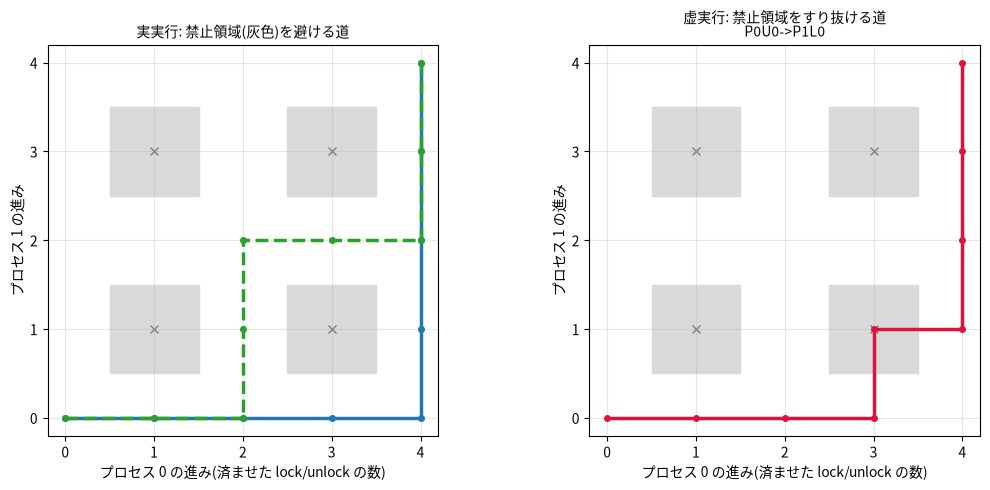

In [56]:
def path_xy(path):
    x = y = 0; pts = [(0, 0)]
    for (q, k, m) in path:
        if q == 0: x += 1
        else: y += 1
        pts.append((x, y))
    return pts

def draw_progress(ax, a, b, paths_and_styles, title):
    for i in range(1, 2 * a, 2):
        for j in range(1, 2 * b, 2):
            ax.add_patch(plt.Rectangle((i - 0.5, j - 0.5), 1, 1, color="0.85", zorder=0))
            ax.plot([i], [j], "x", color="0.5", zorder=1)
    for path, kw in paths_and_styles:
        xs, ys = zip(*path_xy(path))
        ax.plot(xs, ys, **kw)
    ax.set_xticks(range(2 * a + 1)); ax.set_yticks(range(2 * b + 1))
    ax.set_xlabel("プロセス 0 の進み(済ませた lock/unlock の数)")
    ax.set_ylabel("プロセス 1 の進み")
    ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.set_title(title, fontsize=10)

a, b = 2, 2
tp = tunnel_paths((a, b))
real_keys = [k for k in tp if is_linear(dict(k))]
imag_keys = [k for k in tp if not is_linear(dict(k))]
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
styles = [dict(color="tab:blue", lw=2.5, marker="o", ms=4),
          dict(color="tab:green", lw=2.5, marker="o", ms=4, ls="--")]
sel = [(next(p for p in tp[k] if not path_crosses_forbidden(p)), styles[i]) for i, k in enumerate(real_keys[:2])]
draw_progress(axes[0], a, b, sel, "実実行: 禁止領域(灰色)を避ける道")
k = imag_keys[0]
sel = [(tp[k][0], dict(color="crimson", lw=2.5, marker="o", ms=4))]
draw_progress(axes[1], a, b, sel, "虚実行: 禁止領域をすり抜ける道\n" + (elde0_str(cross_edges(dict(k))) or "(空列)"))
plt.tight_layout(); plt.show()

### 6.3 有向位相幾何との関係(問 C への手がかり)

進行グラフは、1990 年代から **有向代数的位相幾何(directed algebraic topology)** として理論化されている(Fajstrup, Goubault, Raussen ら。まとまった教科書は Fajstrup, Goubault, Haucourt, Mimram, Raussen 2016)。そこでは

- 実行 = 禁止領域を除いた空間の中の **有向道**(dipath)、
- 結果が同じになる実行 = 有向道の **有向ホモトピー**(禁止領域のどちら側を通るかが同じ)、
- **デッドロック** = そこから先に進めない点(禁止領域の「角」にはまり込む領域)、

と定式化される。単一ロックの場合、有向ホモトピー類は「CS の順序」すなわち ELDE その3 の lock 仕様と一対一に対応する。JRF が問 C で望んだ「デッドロックの連続・不連続」は、この分野の言葉では、道の空間の連結成分や、デッドロック領域への入り口の幾何として語られている。§9.2 で 2 ロックの場合を描く。

定理 3 はこの絵に一つの読み方を加える。**虚実行は、禁止領域を障壁と見たとき、その障壁を通り抜ける道** である。物理学では、古典的に禁止された領域を通り抜けることを **トンネル効果** といい、そこでは運動量が虚数になる。この類比は §10.3 でもう一度取り上げる。

## §7 虚実行の使い道 ―― 健全な過大近似とその精錬

### 7.1 JRF の観察

> 「虚実行」群の中に「実実行」というべきものがすべて入っているので、「虚実行」群全体でテストに合格したものは「実実行」においてもテストに合格すると言える

これは計算機科学では **健全な過大近似(sound over-approximation)** と呼ばれる考え方そのものである。抽象解釈(Cousot & Cousot 1977)は、プログラムの本当のふるまいの集合を、扱いやすいより大きな集合で置き換えて性質を証明する。大きい集合で「悪いことは起きない」と示せれば、本物でも起きない。そのかわり、大きい集合には本物にはない **偽の反例(false alarm)** が混じる。

並列プログラムの検証には、これとよく似た **スレッド・モジュラー** な抽象がある(Flanagan & Qadeer 2003、Owicki–Gries 1976 や Jones の rely-guarantee 1983 の流れ)。各スレッドは「他のスレッドが作りうる共有状態のどれか」を読むと考えて、スレッドごとに別々に調べる。虚実行の階層(§5.3)の上の方(I や B)は、まさにこの種の抽象の具体例になっている。

### 7.2 例: 加算が失われるか

二つのプロセスが共有変数 `v` に 1 を 2 回ずつ足す。

- **原子的な版**: 読みと書きを同じ CS の中で行う。
- **二段階の版**: ある CS で `v` を読んで手元に覚え、次の CS で「覚えた値 + 1」を書く(典型的なバグ。ロックは使っているのに加算が失われる)。

性質「最後に v = 4」を調べる。虚実行では世界がいくつかに分かれるので、「すべての世界の最終状態で v = 4」を調べることにする。

In [57]:
def mk_atomic(n):
    def p(out):
        for _ in range(n):
            s = yield LOCK
            yield unlock(put(s, "v", get(s, "v", 0) + 1))
    return p

def mk_twophase(n):
    def p(out):
        for _ in range(n):
            s = yield LOCK; t = get(s, "v", 0); yield unlock(s)      # 読んで覚える
            s = yield LOCK; yield unlock(put(s, "v", t + 1))         # 覚えた値+1 を書く
    return p

for name, mk in [("原子的", mk_atomic), ("二段階", mk_twophase)]:
    ps = [Proc(mk(2)), Proc(mk(2))]
    R = enumerate_real(ps)
    E0 = [r for r in enumerate_imag(ps) if is_elde0(r.rf)]
    real_v = Counter(get(r.finals[r.seq[-1][0]], "v", 0) for r in R)
    bad_imag = [r for r in E0 if any(get(s, "v", 0) != 4 for s in world_finals(r))]
    bad_imag_real = [r for r in bad_imag if is_linear(r.rf)]
    print(f"[{name}] 実実行 {len(R)} 通り, 最終 v の分布 {dict(real_v)}")
    print(f"        ELDE0 の実行 {len(E0)} 通り, うち性質を破るもの {len(bad_imag)} 通り"
          f" → 線形(本物の反例) {len(bad_imag_real)} 通り / 偽の反例 {len(bad_imag) - len(bad_imag_real)} 通り")

[原子的] 実実行 6 通り, 最終 v の分布 {4: 6}
        ELDE0 の実行 19 通り, うち性質を破るもの 13 通り → 線形(本物の反例) 0 通り / 偽の反例 13 通り


[二段階] 実実行 70 通り, 最終 v の分布 {4: 6, 3: 32, 2: 32}
        ELDE0 の実行 1107 通り, うち性質を破るもの 1101 通り → 線形(本物の反例) 64 通り / 偽の反例 1037 通り


- 原子的な版では、実実行はすべて v = 4 で、性質は正しい。ところが虚実行では性質を破るものが多数ある。どれも線形でない、つまり **偽の反例** である。状態がコピーされると、増分が別々の世界に散らばって、どの世界にも 4 回分が揃わない。
- 二段階の版では、実実行にも v = 2, 3 が現れる(本物のバグ)。虚実行の中の反例のうち、線形なものが本物の反例である。

ここから次の手順が考えられる。これは反例に導かれた抽象の精錬(CEGAR, Clarke ら 2000)の、ごく素朴な形である。

1. まず虚実行の集合で性質を調べる。全部通れば、実実行でも正しい(健全)。
2. 反例が見つかったら、定理 1 で線形かどうかを調べる。線形なら本物のバグ。
3. 線形でなければ偽の反例なので、その分岐(コピー)を禁じて探索を絞る。

### 7.3 どんな性質なら虚実行で調べてよいか

上の例からわかるのは、**「v = 4」のような保存則は、虚実行で調べると必ず偽の反例が出る** ということである。保存則は「一つの状態を一度しか使わない」という線形性に依存しているからである。

逆に、**各 CS が局所的に保つ性質** は虚実行でも正しい。たとえば「どの CS も v を減らさない」「v は 0 以上」のような不変条件 $J$ は、「$J(s)$ なら $J(\mathrm{CS}(s))$」がすべての CS について成り立てば、どんな木の上でも、根から帰納法で成り立つ。木であっても一本道であっても、各頂点の状態は根からの道に沿って CS を順に施したものだからである。

つまり、

- **帰納的な不変条件**(各 CS が保つ局所的な性質)は、虚実行で調べても失うものがない。帰納的なら、虚実行でも実実行でも成り立つ。ただし、実実行では成り立つが帰納的でない性質(個数や「ちょうど何回」に関わるもの。§7.2 の「最後に v = 4」がその例)は、虚実行では破れることがある。
- **保存則・個数・「ちょうど一度」**(大域的な性質)は、虚実行で調べると偽の反例が出る。

JRF の「「虚実行」を含めたテスト…という考え方がもしかすると有用かもしれない」は、前者についてはそのとおりである。虚実行の集合は大きいが、不変条件の検査は CS ごとの局所的な検査に分解できる(状態の集合を固定点まで広げればよい)。そうすれば、総当りの数の爆発そのものを避けられる。これがスレッド・モジュラー検証の発想である。report2 §6 で、状態の数が指数から多項式に下がること、局所的な不変条件は正しく判定でき個数の性質は偽の警報になることを実測した。

## §8 線形性 ―― コピーと移動、保存則、デッドロック

ここまでの結果を一言でまとめると、**実実行は状態を移動させる実行で、虚実行は状態をコピーしてしまう実行** である。

### 8.1 ロックは「一つしかない物」を受け渡す仕組み

ロックの本質は、共有状態という **一つしかない物** を、プロセスの間で手渡すことにある。手渡した側の手元には何も残らない。ELDE その1 の規則「受け渡しがなければ自分の手元の状態で続ける」は、手渡した後も手元にコピーが残ることを許していた。これが虚実行を生んだ。

この「一度しか使えない」という性質は、論理学では **線形論理**(Girard 1987)が扱う。普通の論理では仮定を何度でも使える(縮約規則)し、使わなくてもよい(弱化規則)。線形論理ではこの二つを制限し、仮定を資源として「ちょうど一度」使う。線形論理には、資源をコピー可能にする様相 $!A$ があり、

- 実実行 = 状態を線形な資源として扱った実行、
- 虚実行 = 状態に $!$ をつけて、コピー(縮約)と破棄(弱化。誰にも読まれない葉)を許した実行、

と言える。

物理では、量子状態は複製できない(複製不可能定理、Wootters & Zurek 1982)。古典的な情報はいくらでもコピーできる。逆向きの対応になるのは面白いが、**本物の実行は複製できない資源の受け渡しとしてしか起きない**、という点は共通している。

### 8.2 ラムダ式との関係(JRF 2011 の直観)

JRF は 2011 年に「lock と(高階論理で使われる)ラムダ式の関係みたいなのが私には見えはじめてる」と書いた。木の見方をとると、これに具体的な形を与えられる。CS $c$ は状態から状態への関数 $f_c$ で、実実行は

$$ f_{v_N}(\cdots f_{v_2}(f_{v_1}(\bot))\cdots) $$

という一本の合成になる。中間の値はどれもちょうど一度使われる(**線形ラムダ項**)。虚実行は、ある中間の値を二度使う項、たとえば

$$ \mathrm{let}\ s = f_{(0,0)}(\bot)\ \mathrm{in}\ \big(\, f_{(0,1)}(s),\ f_{(1,0)}(s) \,\big) $$

で、結果は二つの値の組(二つの世界)になる。$\mathrm{let}$ による **共有** が縮約にあたる。ELDE その1 が数えていたのは、CS を部品とする「共有ありの項」全体、その3 が数えていたのは「線形な項」全体だと言える。

### 8.3 デッドロックは線形性から生まれる

虚実行の世界では **デッドロックが起きない**。ELDE その1 の規則では、lock は決して待たない(誰からも受け渡しがなければ、自分の手元のコピーで続ける)からである。デッドロックは、「一つしかない物」を二人が一つずつ持ったまま、相手の持っている物を待つときに起きる。物がコピーできるなら、待つ必要はない。

つまりデッドロックは、線形な資源に特有の現象である。§9.2 で、2 ロックのデッドロックを進行グラフの上で見る。そこでは、虚実行(禁止領域のすり抜け)を許せばデッドロック領域から抜け出せる。

## §9 ELDE の拡張 ―― 複数ロック・wait_and_lock・確率

### 9.1 拡張の方針

ここまでの考察から、ELDE を拡張するときの方針は次のようになる。

1. **データ構造の中心を lock 仕様から読み出し関係(木)に移す。** 実/虚の判定(定理 1)も、虚の度合い(葉の数 $-1$)もこれで扱える。
2. **lock_limit をなくす。** 同じ大域状態を二度展開しないようにすれば、有限状態のプログラムなら探索は止まる。ELDE その3 の「中途のコンテクストが同じものは二度と実行されないようにプログラムを効率化している」をそのまま一般化したものである。(ただし、ここでの実装はプロセスの局所状態を入力の履歴で代用しているので、ループが無限に続くプログラムでは止まらない。局所状態を明示的に持つ書き方にすれば止まる。)
3. **複数ロック**: ロックごとに共有状態を持たせ、lock 事象だけを分岐点にして総当りする。JRF の「lock のときにのみ調べればよい」は、互いに独立な操作の順序は入れ替えても結果が変わらない、という **トレース**(Mazurkiewicz 1977)の考え方そのもので、Lipton(1975)のリダクションや DRF 保証(Adve & Hill 1990)と同じ前提に立つ(§1.3)。現代の **半順序簡約**(Godefroid 1996、動的半順序簡約 Flanagan & Godefroid 2005)や **ステートレス・モデル検査**(VeriSoft、Godefroid 1997。CHESS、Musuvathi ら 2008)に通じる。
4. **確率**: スケジューラに確率を入れ、実実行に重みをつける(§9.4)。虚実行には「葉の数」で重みをつける(§10.2)。

### 9.2 複数ロックとデッドロック(問 D)

`model_check` は、プロセスを `yield lock("A")` / `yield unlock(s, "A")` のように書き、ロック A, B それぞれに共有状態を持たせて、lock 事象ごとに分岐しながら全実行を調べる。古典的なデッドロックの例として、プロセス 0 は A → B の順に、プロセス 1 は B → A の順にロックを取る。

In [58]:
def pa(out):
    a = yield lock("A")
    b = yield lock("B")
    yield unlock(put(b, "x", get(b, "x", 0) + 1), "B")      # x += 1
    yield unlock(a, "A")

def pb(out):
    b = yield lock("B")
    a = yield lock("A")
    yield unlock(a, "A")
    yield unlock(put(b, "x", get(b, "x", 0) * 10 + 5), "B")  # x = 10x + 5

finals, deadlocks, nstates = model_check([MProc(pa), MProc(pb)], ["A", "B"])
print("調べた大域状態の数:", nstates)
for (ls, outs), trace in finals.items():
    print("正常終了: x =", get(dict(ls)["B"], "x"), "  ロックを取った順:", trace)
for (ls, outs), trace in deadlocks.items():
    print("デッドロック: ロックを取った順:", trace)

調べた大域状態の数: 11
正常終了: x = 15   ロックを取った順: ((0, 'A'), (0, 'B'), (1, 'B'), (1, 'A'))
正常終了: x = 6   ロックを取った順: ((1, 'B'), (1, 'A'), (0, 'A'), (0, 'B'))
デッドロック: ロックを取った順: ((0, 'A'), (1, 'B'))


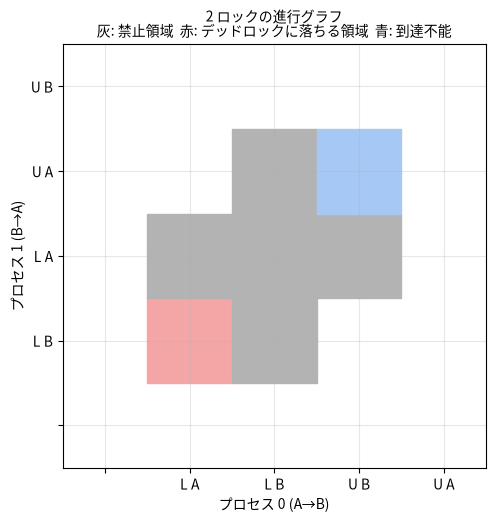

In [59]:
def held_after(ev, k):
    h = set()
    for e in ev[:k]:
        if e[0] == "L": h.add(e[1])
        else: h.discard(e[1])
    return h

def deadlock_geometry(ev0, ev1):
    n0, n1 = len(ev0), len(ev1)
    forb = {(x, y) for x in range(n0 + 1) for y in range(n1 + 1)
            if held_after(ev0, x) & held_after(ev1, y)}
    ok = lambda x, y: 0 <= x <= n0 and 0 <= y <= n1 and (x, y) not in forb
    reach = set(); st = [(0, 0)]
    while st:
        p = st.pop()
        if p in reach: continue
        reach.add(p)
        for d in [(1, 0), (0, 1)]:
            q = (p[0] + d[0], p[1] + d[1])
            if ok(*q): st.append(q)
    coreach = set(); st = [(n0, n1)]
    while st:
        p = st.pop()
        if p in coreach: continue
        coreach.add(p)
        for d in [(-1, 0), (0, -1)]:
            q = (p[0] + d[0], p[1] + d[1])
            if ok(*q): st.append(q)
    return n0, n1, forb, reach, coreach

ev0, ev1 = progress_events(pa), progress_events(pb)
n0, n1, forb, reach, coreach = deadlock_geometry(ev0, ev1)
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for x in range(n0 + 1):
    for y in range(n1 + 1):
        if (x, y) in forb:
            ax.add_patch(plt.Rectangle((x - .5, y - .5), 1, 1, color="0.7"))
        elif (x, y) in reach and (x, y) not in coreach:
            ax.add_patch(plt.Rectangle((x - .5, y - .5), 1, 1, color="#f4a6a6"))
        elif (x, y) not in reach:
            ax.add_patch(plt.Rectangle((x - .5, y - .5), 1, 1, color="#a6c8f4"))
lab0 = ["", "L A", "L B", "U B", "U A"]; lab1 = ["", "L B", "L A", "U A", "U B"]
ax.set_xticks(range(n0 + 1)); ax.set_xticklabels(lab0)
ax.set_yticks(range(n1 + 1)); ax.set_yticklabels(lab1)
ax.set_xlim(-.5, n0 + .5); ax.set_ylim(-.5, n1 + .5); ax.set_aspect("equal"); ax.grid(alpha=.3)
ax.set_xlabel("プロセス 0 (A→B)"); ax.set_ylabel("プロセス 1 (B→A)")
ax.set_title("2 ロックの進行グラフ\n灰: 禁止領域  赤: デッドロックに落ちる領域  青: 到達不能", fontsize=10)
plt.show()

灰色の禁止領域は「十字」の形をしている(A を両方が持つ帯と、B を両方が持つ帯の和)。左下の角の赤い点 (1, 1) は「プロセス 0 が A を持って B を待ち、プロセス 1 が B を持って A を待つ」状態で、右にも上にも進めない。ここに入った実実行は終われない。これがデッドロックの幾何学的な姿である。右上の青い点は、どの実行も到達できない領域である。

問 C の「デッドロックの連続・不連続」に一つの答え方をすると、こうなる。実行の道を連続的に変形していくと、ある道は禁止領域の左上側を、ある道は右下側を通る。その間を連続的に移ろうとすると、必ずデッドロック領域を通るか、禁止領域を横切らなければならない。**デッドロック領域は、実行の空間の二つの成分(正常終了の二つの結果 x = 6 と x = 15)の「境目」にあたる。** 有向代数的位相幾何は、この直観を、道の空間の位相として精密にする。

そして §8.3 で見たように、虚実行(禁止領域のすり抜け)を許せば赤い点からも右上へ抜けられる。虚の世界にはデッドロックがない。

### 9.3 wait_and_lock(ELDE その2)の再現

`WLOCK` は ELDE その2 の `wait_and_lock` で、「自分の直前の unlock(最初の lock なら開始)の後に、他のプロセスの CS が一つ以上あるまで待ってからロックを取る」。JRF の例を、実実行だけの探索で再現する。

In [60]:
def w0(out):
    s = yield LOCK
    out.append(get(s, "a")); s = put(s, "a", 1)
    yield unlock(s)
    s = yield WLOCK
    out.append(get(s, "a")); s = put(s, "a", 3)
    yield unlock(s)

def w1(out):
    s = yield WLOCK
    out.append(get(s, "a")); s = put(s, "a", 2)
    yield unlock(s)

for r in enumerate_real([Proc(w0), Proc(w1)]):
    print(spec_str(r.seq), r.status, " 出力:", r.outputs)

def d0(out):
    s = yield WLOCK; yield unlock(s)
def d1(out):
    s = yield WLOCK; yield unlock(s)
print()
print("両方が最初から wait_and_lock する場合:")
for r in enumerate_real([Proc(d0), Proc(d1)]):
    print("  ", spec_str(r.seq) or "(何も実行されない)", r.status)

P0L0,P1L0,P0L1 ok  出力: ((None, 2), (1,))

両方が最初から wait_and_lock する場合:
   (何も実行されない) deadlock


JRF のその2 の結論「π0υ0→π1λ0,π1υ0→π0λ1 という lock 仕様のときのみ、正常に終了する」と一致する(その3 の記法では P0L0,P1L0,P0L1)。実実行だけを探索すると、待ちで止まった実行は `deadlock` としてそのまま区別できる。その2 は虚実行を含む枠組みだったので、「wait を含むが、その子の仕様に正常終了したものがない場合」という回りくどい判定が必要だった。

### 9.4 確率(問 E)

その2 の「今後の課題」で JRF はこう書いた。

> 二つのプロセスがあって、一方では lock 後ある変数に 1 を足し他方では 1 を引くとする。例えば、それをそれぞれ２度繰り返したあと一方が答えを表示する。(...)「現実」は、lock が一度もブロックされないことが圧倒的に多いとなるだろう。(...) しかし、ここにそれぞれ wait_and_lock を挟むとどうなるか。とたんに中間的な値が「現実」味を帯びてくる。

これを確かめる。スケジューラは「直前に走ったプロセスが続けて走れるなら確率 $1-\varepsilon$ で続け、$\varepsilon$ で他のプロセスに切り換える」とする。$\varepsilon$ が小さいほど、横取り(preemption)の少ない、「現実」に近いスケジュールになる。

なし 実実行: [('P0L0,P0L1,P0L2,P1L0,P1L1', (2,)), ('P0L0,P0L1,P1L0,P0L2,P1L1', (1,)), ('P0L0,P0L1,P1L0,P1L1,P0L2', (0,)), ('P0L0,P1L0,P0L1,P0L2,P1L1', (1,))] ...
あり 実実行: [('P0L0,P1L0,P0L1,P0L2,P1L1', (1,)), ('P0L0,P1L0,P0L1,P1L1,P0L2', (0,)), ('P1L0,P0L0,P1L1,P0L1,P0L2', (0,))] ...


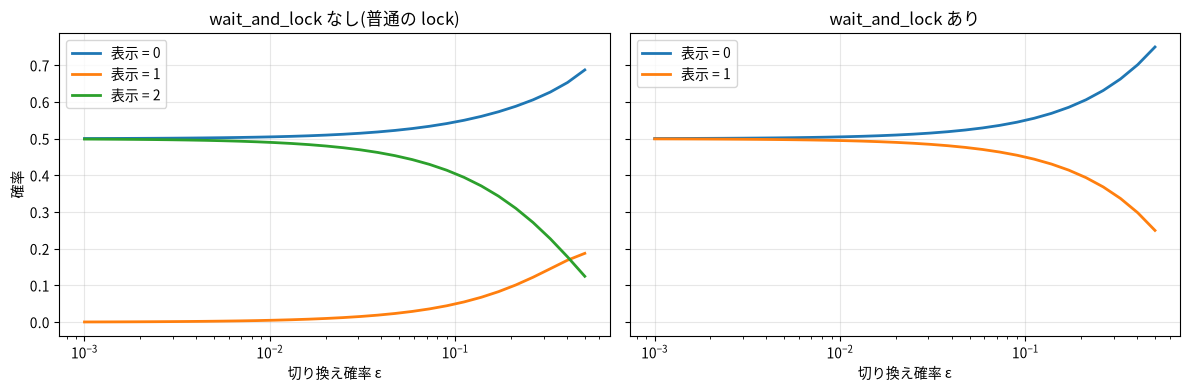

In [61]:
def mk_incdec(wait):
    def inc(out):
        for k in range(2):
            s = yield (WLOCK if (wait and k > 0) else LOCK)
            yield unlock(put(s, "v", get(s, "v", 0) + 1))
        s = yield LOCK
        out.append(get(s, "v", 0))             # 表示
        yield unlock(s)
    def dec(out):
        for k in range(2):
            s = yield (WLOCK if (wait and k > 0) else LOCK)
            yield unlock(put(s, "v", get(s, "v", 0) - 1))
    return [Proc(inc), Proc(dec)]

epss = np.logspace(-3, np.log10(0.5), 30)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, wait in zip(axes, [False, True]):
    ps = mk_incdec(wait)
    vals = sorted({r.outputs[0][0] for r in enumerate_real(ps) if r.outputs[0]})
    curves = {v: [] for v in vals}
    for eps in epss:
        d = scheduled_distribution(ps, eps, lambda o, s: o[0][0])
        for v in vals:
            curves[v].append(d.get(v, 0.0))
    for v in vals:
        ax.semilogx(epss, curves[v], label=f"表示 = {v}", lw=2)
    ax.set_xlabel("切り換え確率 ε"); ax.grid(alpha=.3); ax.legend()
    ax.set_title("wait_and_lock あり" if wait else "wait_and_lock なし(普通の lock)")
    print(("あり" if wait else "なし"), "実実行:", [(spec_str(r.seq), r.outputs[0]) for r in enumerate_real(ps)][:4], "...")
axes[0].set_ylabel("確率")
plt.tight_layout(); plt.show()

- 普通の lock では、$\varepsilon\to 0$ で表示は 2(足す方が全部先)か 0(引く方が先、または表示の前に全部終わる)にほぼ限られ、中間の 1 は消えていく。場合の数としては 1 もあるのに、「現実」の確率はほとんどない。JRF の「「現実」にはまともな「確率」が存在しない」はこのことだろう。
- wait_and_lock を挟むと、両端の値(2)は場合の数から消え、中間の 1 が $\varepsilon\to0$ でも半分近い確率を持つ。**wait_and_lock は場合の数を減らす(枝刈り)と同時に、確率の重みを大きく動かす。** JRF の「その場合の数以上にとても大きな「現実」も枝刈りしたとできるのかもしれない」の数値的な裏づけになる。

この問題は、その後の並列プログラムのテスト研究で中心的な主題になった。

- **文脈切り換えの回数を制限した探索**(Musuvathi & Qadeer 2007): 実際のバグの多くは横取りが 2 回程度以下のスケジュールで現れる。$\varepsilon$ が小さい「現実」の確率の重みと同じ発想である。
- **PCT**(Burckhardt ら 2010): 少数の「優先度変更点」を乱数で入れるスケジューラで、深さ $d$ のバグを見つける確率に下界を与える。JRF がその1 で書いた「sleep とはエラーの確率に干渉する操作ではないか」は、ちょうど PCT の優先度変更点(わざと遅らせる点)の役割にあたる。

## §10 虚数との関係

ここからが問 F、「虚実行」を「虚数」とどう関係づけられるか、である。言葉が似ているだけでなく、構造の上でも対応がつくことを、三つの方向から示す。

### 10.1 「虚」を経由して「実」に戻る

JRF は『宗教学雑考集』(2025)の「虚数と超ひも理論」の節でこう書いている。

> 虚数とは単に「2乗するとマイナスになる数」だが、それは現実には存在しないバーチャルな量である。しかし、それを物理学の理論に組み込むことで、説明が容易になることが多かった。バーチャルな「虚」の理論を経由して計算しても、結果、「虚」が外れた現実に解が戻ってくれば、それが正しい現実の解になるのだ。
>
> 虚数に限らず、ある理論を「仮設」して、それを経由して現実を説明するようなそのような理論を「虚」の理論と私は呼ぶ。

歴史的にも、虚数はまさにこの形で現れた。16 世紀、ボンベリ(Bombelli 1572)は 3 次方程式 $x^3 = 15x + 4$ にカルダノの公式を当てはめ、

$$ x = \sqrt[3]{2+\sqrt{-121}} + \sqrt[3]{2-\sqrt{-121}} $$

を得た。実数の答え $x=4$ があるのに、途中で負の数の平方根を通らないと公式が使えない。ボンベリは $(2+\sqrt{-1})^3 = 2+\sqrt{-121}$ に気づき、$x = (2+\sqrt{-1}) + (2-\sqrt{-1}) = 4$ と「実」に戻った。

In [62]:
z = (2 + 1j) ** 3
print("(2+i)^3 =", z)
x = (2 + 1j) + (2 - 1j)
print("x =", x, "  検算 x^3 - 15x - 4 =", x**3 - 15*x - 4)

(2+i)^3 = (2+11j)
x = (4+0j)   検算 x^3 - 15x - 4 = 0j


ELDE にもこれと同じ形の出来事があった。JRF はその3 で、虚実行を含む「失敗作」の `elde_0.pl` を、実実行だけを数える `elde_2.pl` の検算に使った(`elde_0_and_2.pl`)。「怪我の功名」と JRF は書いたが、これは「虚の理論を経由して実を確かめる」ことの小さな実例である。

以下では、虚実行を経由して実実行を取り出す計算を、文字どおり虚数を使って行う。

### 10.2 枝分かれの母関数と単位円上の積分

定理 1 により、虚実行 $E$ の **葉の数** $\ell(E)$ は「世界の数」で、$\ell(E)=1$ が実実行である。そこで、虚実行の集合(ここでは ELDE その1 の全体 E0)の上で母関数

$$ G(x) = \sum_{E\in \mathrm{E0}} x^{\ell(E)-1} $$

を考える。$x$ は「余分な世界一つあたりの重み」である。

- $x = 1$: $G(1) = |\mathrm{E0}|$。ELDE その1 が数えていたもの。
- $x = 0$: $G(0) = $ 実実行の数。ELDE その3 が数えていたもの。
- $0<x<1$: 虚実行を「虚の度合い」に応じて割り引いて数える。その1 とその3 を連続的につなぐ。

$G$ は多項式なので、定数項 $G(0)$ は単位円上の平均で取り出せる(コーシーの積分公式):

$$ G(0) = \frac{1}{2\pi}\int_0^{2\pi} G(e^{i\theta})\, d\theta = \frac{1}{K}\sum_{k=0}^{K-1} G(\omega^k),\quad \omega = e^{2\pi i/K},\ K > \deg G . $$

右辺の各項 $G(\omega^k)$ は複素数で、虚実行の寄与 $\omega^{k(\ell-1)}$ は単位円上をぐるりと回る。平均をとると虚実行の寄与は互いに打ち消し合い、実実行だけが残る。**虚実行の和に複素数の位相をつけて足し合わせると、干渉によって実実行だけが残る。** 物理学の経路積分で、古典的でない経路の寄与が位相の打ち消し合いで消えていくのと同じ形である(ただし物理では打ち消し合いは近似的で、ここでは厳密)。

JRF の最初の例では、E0 は 6 通りで、実が 3 通り、葉が 2 の虚が 3 通りだから $G(x) = 3 + 3x$、$K=2$ で $\{G(1) + G(-1)\}/2 = (6 + 0)/2 = 3$ である。$x=-1$ では、虚実行がちょうど $-1$ の重みを持って実実行を打ち消す。表示される値ごとに分けると次のようになる。

In [63]:
E0_ex = [r for r in enumerate_imag(procs) if is_elde0(r.rf)]
by_out = defaultdict(list)
for r in E0_ex:
    by_out[r.outputs[1][0]].append(r)
print("表示ごとの母関数 G_o(x) = Σ x^(ℓ-1):")
for o, rs in by_out.items():
    poly = leaf_poly(rs)
    val, vals = circle_filter(poly, K=2)
    print(f"  表示 {o!s:>5}: 係数 {dict(sorted(poly.items()))}   G_o(1) = {poly_eval(poly, 1)}, "
          f"G_o(-1) = {poly_eval(poly, -1)},  平均 = {val.real:.0f}  (実実行の数)")

表示ごとの母関数 G_o(x) = Σ x^(ℓ-1):
  表示 undef: 係数 {0: 1, 1: 2}   G_o(1) = 3, G_o(-1) = -1,  平均 = 1  (実実行の数)
  表示     1: 係数 {0: 1, 1: 1}   G_o(1) = 2, G_o(-1) = 0,  平均 = 1  (実実行の数)
  表示     2: 係数 {0: 1}   G_o(1) = 1, G_o(-1) = 1,  平均 = 1  (実実行の数)


表示 undef の行では $G(-1) = -1$ になる。$x=-1$ を「重み」と見ると、虚実行に **負の確率** を割り当てて実実行を取り出したことになる。ファインマンの「負の確率」(Feynman 1987)や量子力学の Wigner 関数の負の値と同じ種類のものである。

もう少し大きな例(二段階の加算、E0 が 1107 通り)で、$G(e^{i\theta})$ が複素平面上に描く曲線と、その平均を見る。

葉の数 -1 の分布: {0: 70, 1: 379, 2: 492, 3: 158, 4: 8}
G(1) = 1107  (ELDE0 の総数)
K = 5 点の単位円平均 = 70.000000 +4.0e-14i   実実行の数 = 70


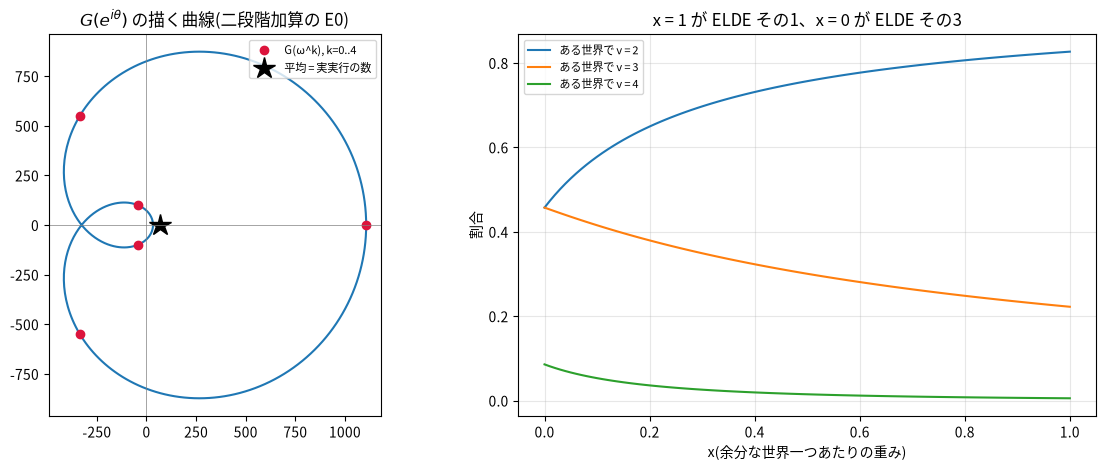

In [64]:
ps = [Proc(mk_twophase(2)), Proc(mk_twophase(2))]
E0_big = [r for r in enumerate_imag(ps) if is_elde0(r.rf)]
poly = leaf_poly(E0_big)
print("葉の数 -1 の分布:", dict(sorted(poly.items())))
print("G(1) =", poly_eval(poly, 1), " (ELDE0 の総数)")
K = max(poly) + 1
val, vals = circle_filter(poly, K)
print(f"K = {K} 点の単位円平均 = {val.real:.6f} {val.imag:+.1e}i   実実行の数 = {len(enumerate_real(ps))}")

th = np.linspace(0, 2 * np.pi, 400)
curve = np.array([poly_eval(poly, np.exp(1j * t)) for t in th])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ax = axes[0]
ax.plot(curve.real, curve.imag, lw=1.5)
pts = np.array(vals)
ax.plot(pts.real, pts.imag, "o", color="crimson", label=f"G(ω^k), k=0..{K-1}")
ax.plot([val.real], [val.imag], "*", ms=16, color="k", label="平均 = 実実行の数")
ax.axhline(0, color="0.5", lw=.5); ax.axvline(0, color="0.5", lw=.5)
ax.set_aspect("equal"); ax.legend(fontsize=8); ax.set_title(r"$G(e^{i\theta})$ の描く曲線(二段階加算の E0)")
ax = axes[1]
xs = np.linspace(0, 1, 101)
outs = defaultdict(list)
for r in E0_big:
    outs[tuple(sorted(get(s, "v", 0) for s in world_finals(r)))].append(r)
# 実実行の最終 v ごとに、x で割り引いた重み
for v in [2, 3, 4]:
    sel = [r for r in E0_big if any(get(s, "v", 0) == v for s in world_finals(r))]
    num = [sum(x ** (len(leaves(r.rf)) - 1) for r in sel) for x in xs]
    den = [poly_eval(poly, x) for x in xs]
    ax.plot(xs, np.array(num) / np.array(den), label=f"ある世界で v = {v}")
ax.set_xlabel("x(余分な世界一つあたりの重み)"); ax.set_ylabel("割合")
ax.set_title("x = 1 が ELDE その1、x = 0 が ELDE その3"); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

右の図は、$x$ を 1 から 0 へ動かすと、虚実行の世界観(その1)から実実行の世界観(その3)へ連続的に移ることを示す。$x$ は統計力学の **活量**(fugacity)のような働きをする。$x$ を確率の重みと見れば、「虚実行を少しだけ許すテスト」が定義できる。

**注意(実数でも足りるか).** 定数項の取り出しは、実数の点 $x_1,\dots,x_K$ での値からラグランジュ補間でも計算できる(係数には負の数が出る)。だから「虚数でなければできない」わけではない。2021 年に、量子力学は実数だけでは書けないことが実験で示された(Renou ら 2021。JRF も『宗教学雑考集』でこの記事を引いている)。ここでの虚数は、そういう意味での不可欠さではなく、「位相を回して平均する」という計算の自然さの点で現れている。

### 10.3 トンネル効果 ―― 禁止領域の中の虚数

定理 3 によれば、虚実行は進行グラフの禁止領域をすり抜ける道である。量子力学では、粒子が古典的に入れない領域(ポテンシャルの壁 $V > E$)に染み込み、通り抜けることがある(トンネル効果)。そこでは波数

$$ k = \frac{\sqrt{2m(E - V)}}{\hbar} $$

が **虚数** になり、波は振動せずに指数関数的に減衰する。トンネルの確率は壁の厚さに対して指数関数的に小さい。さらに、トンネルする経路は **虚時間** $t = -i\tau$ の中での古典的な運動(インスタントン、Coleman 1977)として計算できる。

ELDE に当てはめると、「禁止領域の中を進む実行は、実時間の実行ではない」。§10.2 の重み $x$ を「禁止領域の中を一歩進むごとの減衰」と読みかえれば、トンネルの深さに応じて指数関数的に小さくなる重みを虚実行につけることになる。これはまだ類比の段階だが、**「実行の可能性の空間で、本物の実行が通れない領域」に虚数が現れる** という対応は、物理と ELDE で同じ形をしている。

### 10.4 時間ループと虚数単位 ―― 嘘つきの値は $i$

虚実行の階層(§5.3)の一番上は「時間ループ」L であった。CS が、自分より後に書かれる状態、さらには **自分自身の出力** を入力として読む。こういう実行が意味を持つのは、ループに沿った状態が **自己無撞着**(一周して元に戻る)ときだけである。CS $c_1,\dots,c_n$ のループなら、状態 $s$ は

$$ s = f_{c_n}\circ\cdots\circ f_{c_1}(s) $$

を満たさなければならない。不動点がなければ、その時間ループは起こりえない(「親殺しのパラドックス」)。不動点が無数にあれば、何でも起こりうる(「ブートストラップのパラドックス」)。時間旅行の物理でいう **ノヴィコフの自己無撞着原理**(Friedman ら 1990)や、Deutsch(1991)の閉じた時間的曲線のモデルは、この不動点の条件を課すものである。

ここで、状態が実数 $x$ で、CS が **タンジェントの加法定理** で $x$ を更新する例を考える。

$$ f_\theta(x) = \frac{x + \tan\theta}{1 - x\tan\theta} \qquad (x = \tan\alpha \text{ なら } f_\theta(x) = \tan(\alpha+\theta)) $$

これは角度を $\theta$ だけ回す操作である。実実行ではループ $s_{k+1} = f_\theta(s_k)$ を何度も回し、$x$ は $\tan(\alpha + k\theta)$ と実数の範囲でぐるぐる回る。ところが「CS が自分の出力を読む」時間ループにすると、$x = f_\theta(x)$ から

$$ x(1 - x\tan\theta) = x + \tan\theta \iff x^2 = -1 \iff x = \pm i $$

で、**$\theta$ によらず、自己無撞着な状態は虚数単位 $\pm i$ しかない。** 実実行ではいつまでも回り続けるものを、時間を止めて(一つの状態で)表そうとすると、虚数が出てくる。

さらに見通しをよくするために、$w = (x - i)/(x + i)$(ケイリー変換)で実数直線を単位円に写す。$x = \tan\alpha$ は $w = -e^{2i\alpha}$ に写り、$f_\theta$ は単位円の **回転** $w\mapsto e^{2i\theta}w$ になる。実実行は円周上を回り、$x=i$ は円の **中心** $w=0$ に写る。虚数単位は、回り続ける実実行の「回転の中心」である。

**虚の不動点での微分が、実実行の回転の速さを与える.** $t=\tan\theta$ とおくと $f_\theta'(x) = (1+t^2)/(1-tx)^2$ で、不動点 $x=i$ では

$$ f_\theta'(i) = \frac{1+t^2}{(1-it)^2} = \frac{(1-it)(1+it)}{(1-it)^2} = \frac{1+it}{1-it} = \frac{\cos\theta + i\sin\theta}{\cos\theta - i\sin\theta} = e^{2i\theta} $$

となる。絶対値が 1 なので、$i$ は引き寄せも突き放しもしない「中立」な不動点で、その偏角 $2\theta$ が、実実行がケイリー変換後の円の上を一回の CS で回る角度にちょうど等しい(上の回転 $w\mapsto e^{2i\theta}w$ の倍率そのもの)。したがって、実実行が何回の CS で元に戻るか(周期)は $e^{2in\theta}=1$ となる最小の $n$ で、**時間ループの虚の解だけを見て、実実行の振動の周期が読める**。線形の力学系で、複素固有値の偏角が振動の周期を決めるのと同じ形である。この話は report3(時間ループと最適化)§1・§2 で一般のメビウス変換や発振条件に広げ、実実行が元に戻るのは乗数が 1 の冪根のときに限ることを示した(report3 の定理 F′)。

θ = 0.7 の回転 f の自己無撞着解(長さ 1 のループ): [(-0-1j), (-0+1j)]
f'(i) = 0.169967+0.985450j,  e^(2iθ) = 0.169967+0.985450j
  θ = π/2, ループの長さ 1: -0.000-1.000j, -0.000+1.000j
  θ = π/2, ループの長さ 2: すべての x(ブートストラップ)
  θ = π/3, ループの長さ 1: -0.000-1.000j, -0.000+1.000j
  θ = π/3, ループの長さ 2: -0.000-1.000j, -0.000+1.000j
  θ = π/3, ループの長さ 3: すべての x(ブートストラップ)
  θ = π/5, ループの長さ 1: -0.000-1.000j, -0.000+1.000j
  θ = π/5, ループの長さ 4: -0.000-1.000j, -0.000+1.000j
  θ = π/5, ループの長さ 5: すべての x(ブートストラップ)


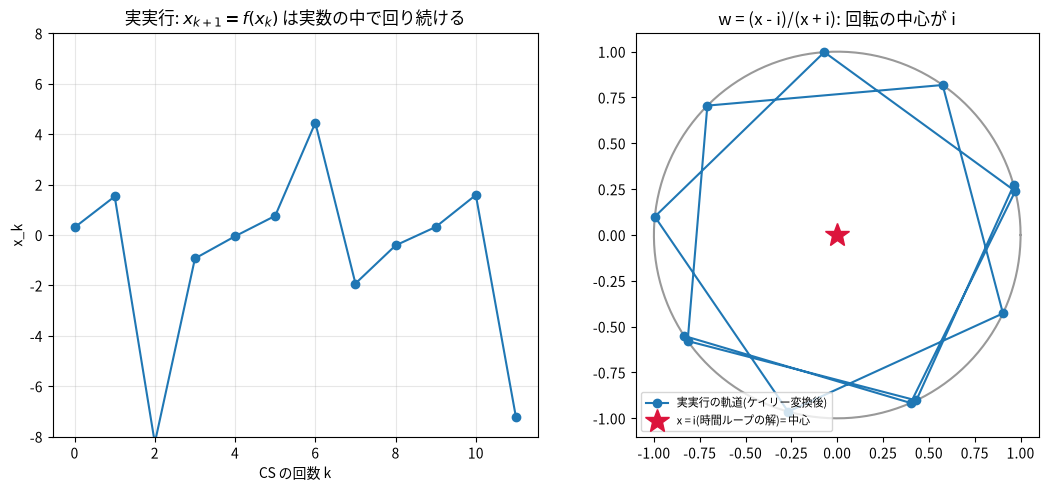

In [65]:
theta = 0.7
M = mobius_rot(theta)
print("θ = 0.7 の回転 f の自己無撞着解(長さ 1 のループ):", mobius_fixed_points(M))
h = 1e-6
fprime = (mobius_apply(M, 1j + h) - mobius_apply(M, 1j - h)) / (2 * h)   # 数値微分
print(f"f'(i) = {fprime:.6f},  e^(2iθ) = {cmath.exp(2j * theta):.6f}")
for n in [2, 3, 5]:
    th = math.pi / n
    for L in sorted({1, n - 1, n}):
        fp = mobius_fixed_points(mobius_power(mobius_rot(th), L))
        desc = "すべての x(ブートストラップ)" if fp == "all" else ", ".join(f"{z:.3f}" for z in fp)
        print(f"  θ = π/{n}, ループの長さ {L}: {desc}")

cay = lambda x: (x - 1j) / (x + 1j)
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
ax = axes[0]
x = 0.3; ks = range(12); xs_ = []
for k in ks:
    xs_.append(x); x = mobius_apply(M, x)
ax.plot(list(ks), xs_, "o-"); ax.set_ylim(-8, 8); ax.grid(alpha=.3)
ax.set_xlabel("CS の回数 k"); ax.set_ylabel("x_k"); ax.set_title(r"実実行: $x_{k+1} = f(x_k)$ は実数の中で回り続ける")
ax = axes[1]
t = np.linspace(0, 2 * np.pi, 300)
ax.plot(np.cos(t), np.sin(t), color="0.6")
ws = [cay(v) for v in xs_]
ax.plot([w.real for w in ws], [w.imag for w in ws], "o-", label="実実行の軌道(ケイリー変換後)")
ax.plot([0], [0], "*", ms=18, color="crimson", label="x = i(時間ループの解)= 中心")
ax.set_aspect("equal"); ax.legend(fontsize=8, loc="lower left"); ax.set_title("w = (x - i)/(x + i): 回転の中心が i")
plt.tight_layout(); plt.show()

**ELDE の言葉で確かめる.** この時間ループは、ELDE の部品でそのまま書ける。2 プロセスがそれぞれ CS を一つ持ち、P0 は x を角度 $\theta$ だけ、P1 は $\varphi$ だけ回すとする。普通の実実行は CS を順に走らせるだけだが、rf を $\mathrm{rf}(0,0)=(1,0)$, $\mathrm{rf}(1,0)=(0,0)$(互いに相手の出力を読む、§5.3 の L)にすると、どちらから走らせても入力が決まらない。ELDE の再生でできるのは、候補の状態を仮定して、一周して戻るかを確かめることだけである。§5.5 の `consistent_executions` は候補を有限集合から総当りするので、$x$ が実数(や複素数)のこの例にはそのまま使えない。そこで、その中の検査だけを取り出した `is_consistent` を使い、候補(上で解いた一周の写像の不動点 $\pm i$ も含める)を一つずつ確かめる。

In [66]:
def rot_proc(theta):
    t = math.tan(theta)
    def p(out):
        s = yield LOCK
        x = get(s, "x", 0.0)
        yield unlock(put(s, "x", (x + t) / (1 - x * t)))
    return Proc(p)

P0, P1 = rot_proc(0.7), rot_proc(0.4)
print("実実行(初期 x = 0.3):", [round(get(r.finals[r.seq[-1][0]], "x"), 4)
                             for r in enumerate_real([P0, P1], init=(("x", 0.3),))])
rf_loop = {(0, 0): (1, 0), (1, 0): (0, 0)}      # 互いに相手の出力を読む(階層 L)
fps = mobius_fixed_points(mobius_compose(mobius_rot(0.4), mobius_rot(0.7)))
print("一周の写像の不動点(解析的に求めたもの):", [f"{z:.3f}" for z in fps])
close = lambda a, b: abs(get(a, "x") - get(b, "x")) < 1e-9
for x in [0.0, 0.3, 1.0, -2.0] + list(fps):
    s0 = (("x", x),)
    u0 = P0.replay((s0,))[1][0]          # P0 が s0 を読んで置く状態 = P1 が読む状態
    ok = is_consistent([P0, P1], rf_loop, (1, 1), {(0, 0): s0, (1, 0): u0}, eq=close)
    print(f"   P0 が x = {complex(x):.3f} を読む → 自己無撞着: {ok}")

実実行(初期 x = 0.3): [5.5161, 5.5161]
一周の写像の不動点(解析的に求めたもの): ['-0.000-1.000j', '-0.000+1.000j']
   P0 が x = 0.000+0.000j を読む → 自己無撞着: False
   P0 が x = 0.300+0.000j を読む → 自己無撞着: False
   P0 が x = 1.000+0.000j を読む → 自己無撞着: False
   P0 が x = -2.000+0.000j を読む → 自己無撞着: False
   P0 が x = -0.000-1.000j を読む → 自己無撞着: True
   P0 が x = -0.000+1.000j を読む → 自己無撞着: True


実数の候補はどれも戻らず、整合するのは $x=\pm i$ だけである(θ+φ が π の倍数でない限り、実数の解はない)。§5.5 で見たとおり、**時間ループの実行は「走らせて決まる」のではなく「整合するものだけが存在する」**。この例では、整合する状態が実数の中になく、虚数単位として現れる。

$x=\tan\alpha$ は $\alpha$ について周期 $\pi$ なので、$\theta = \pi/n$ の回転を $n$ 回施すと元に戻る(ケイリー変換後の円をちょうど一周する)。このように、ループの長さがちょうど一周分のときだけ、すべての実数が自己無撞着になる(ブートストラップ型)。それ以外の長さでは解は $\pm i$ だけである(親殺し型。実数の解はない)。

**嘘つきのパラドックス.** 特に $\theta = \pi/2$(4 分の 1 回転)なら $f(x) = -1/x$ で、$x=0$ を「真」、$x=\infty$ を「偽」とすると、$f$ は真と偽を入れ替える **否定** になる($f(0)=\infty$, $f(\infty)=0$)。「この文は偽である」という嘘つきの文は、否定が自分自身を読む時間ループ $x = -1/x$ であり、真にも偽にも定まらない。実実行(時間に展開した評価)では真・偽・真・偽…と振動する。そしてこのループの自己無撞着な値は $x^2=-1$、つまり **$i$** である。一方「この文は真である」(否定を二度通る長さ 2 のループ $f\circ f = \mathrm{id}$)は、どの値でも自己無撞着になる(真と言っても偽と言ってもよい)。嘘つきと正直者の違いが、親殺し型とブートストラップ型の違いとして現れる。

自己言及のパラドックスと虚数を結びつける考えは古くからある。スペンサー=ブラウン『形式の法則』(1969)は、自己を再参照する式の値を「虚の値」と呼び、時間の中の振動として解釈した。カウフマン(Kauffman 1987)は、振動 $[+1,-1,+1,\dots]$ とその半周期ずらしを使って、論理の上で $i^2=-1$ を満たす「虚の値」を作った。ここでの見方は、それを ELDE の言葉で言い直したものである。**嘘つきの文の値 $i$ は、実実行では振動として時間の中に展開されるものを、時間ループ(虚実行の極限)で一つの状態に押し込めたときの値である。** この振動を実際に作る回路が、否定を奇数個輪につないだリング発振器で、report3 §2.3(定理 R)で扱った。

### 10.5 まとめ: 虚実行と虚数の対応表

| | 数 | 実行 |
|---|---|---|
| 実のもの | 実数 | 実実行(状態の移動、一本道) |
| 拡張 | 複素数 | 虚実行(状態のコピー、木) |
| 捨てた制約 | 「2 乗は 0 以上」 | 「一つの状態は一度だけ使う」(線形性) |
| 保たれる局所規則 | 四則演算の法則 | 各 CS は実在する過去の状態を読む |
| 「虚」を経由して「実」に戻る | ボンベリの 3 次方程式 | その1 でその3 を検算、葉の母関数の円周積分 |
| 禁止された領域 | トンネル効果の虚の波数 | 進行グラフの禁止領域のすり抜け |
| 自己無撞着 | $x^2=-1$ の解 $i$ | 時間ループ $x = -1/x$ の状態 |
| 回転 | $e^{i\theta}$ | 回り続ける実実行の、回転の中心 |

## §11 まとめと今後の課題

### 11.1 JRF の問いへの答え

- **問 A(判定)**: 実実行 ⇔ 読み出し関係の木で、どの状態も高々一度しか読まれない ⇔ 葉が一つ(定理 1)。判定は線形時間でできる。
- **問 B(意味)**: 虚実行は、局所的な制約(実在する過去の状態を読む)はすべて満たし、大域的な線形性(一つの状態は一度だけ)だけを破る実行である。存在しない出来事を参照するほかの cut とは、はっきり区別できる(§5.4)。帰納的な不変条件の検査には健全で、保存則の検査では偽の反例を生む(§7)。
- **問 C(連続性)**: 2 プロセスでは、虚実行は進行グラフの禁止領域をすり抜ける道である(定理 3)。道が禁止領域を通れば必ず虚になることは、プロセスがいくつでも成り立つ。デッドロック領域は、実行の空間の成分の境目にある(§9.2)。有向代数的位相幾何がこれを精密にする。
- **問 D(複数ロック)**: lock 事象だけを分岐点にしたモデル検査器で、デッドロックの検出と、その幾何学的な姿を示した(§9.2)。虚の世界にはデッドロックがない(§8.3)。
- **問 E(確率)**: 横取りの少ないスケジューラでは中間的な結果の確率が消え、wait_and_lock を挟むと中間的な結果が現実味を帯びる、という JRF の直観を数値で確かめた(§9.4)。
- **階層の上**: まだ書かれていない状態まで読んでよいとすると(時間逆行・時間ループ)、実行は前から計算できず、一周して整合するものだけが存在する(定理 4、§5.5)。時間ループの整合する状態が虚数単位になる例が §10.4 である。
- **問 F(拡張概念)**: 虚実行と虚数の間に、捨てた大域制約・保たれる局所規則・「虚」を経由した計算・禁止領域・自己無撞着・回転、の各点で対応がつく(§10.5)。

### 11.2 今後の課題

0.1.0 で最初に挙げた「定理 2 と定理 3(i) の完全な証明」は、Lean による形式的証明として済ませた。定理 4 も 0.4.0 で Lean で証明した。0.3 で挙げた課題のうち、後続のレポートで扱ったものには、その行き先を書く。

1. **2 プロセスの仕様数 $f(2a,2b)$ の閉じた式と漸近挙動**。→ 0.4.0 で解いた(§5.2: 母関数 $(1+x+y)/(1-x^2-xy-y^2)$、$f(2a,2a) \sim \sqrt{3/(8\pi a)}\,9^a$)。3 プロセス以上の数え上げは残る。
2. **合流(マージ)のある虚実行**。虚実行は「枝分かれはするが合流しない」歴史である。二つの世界の状態を合流させる操作を許すと、楽観的並行制御やスナップショット分離(write skew などの異常)、分散システムの結果整合性や CRDT(Shapiro ら 2011)の理論につながる。git の履歴(分岐と合流)や、コピーの上で並列に作業する AI エージェントも同じ形をしている。→ report1(虚実行と合流): 合流が直列実行と区別できない条件(定理 A)と、スナップショット分離の危険構造(定理 B)を Lean で証明した。
3. **部品に意味を与える**。並列プログラムをプロセスごとに理解するには、プロセス単体の意味を「相手がどんな状態を渡してきても」で定める必要があり、そこには実際の相手が渡さない虚の入力が含まれる(Brookes の完全抽象意味論、rely-guarantee)。実実行だけでは並列合成について閉じないこと、閉じるために足りる最小の虚は何か(E0 か)を調べる。§7.3 のスレッド・モジュラー検査による計算量の削減もここに入る。→ report2: 実実行だけでは閉じず(定理 C)、スケジュールを選べる検査者には各 lock に一つずつの虚の入力が必要十分(定理 H、E0 の形)、記憶のある相手は「外れたときに潰せる」虚の入力の列を見分ける(定理 J・K)。
4. **複数ロックの虚実行**。ロックごとに別々の木を持つ虚実行と、デッドロック領域のすり抜けの関係。
5. **重み $x$ と最適化**。JRF は 2025 年に「最適化にそれをどうつなげればいいのかはまだぜんぜんわからない」と書いた。一つの道筋は整数計画法の **緩和**(LP 緩和)で、虚実行は実行の空間の「線形性の緩和」、§10.2 の $x$ はその緩和の強さを連続的に調整するパラメータになっている。遺伝的アルゴリズムの選択、粒子フィルタのリサンプリング、ビームサーチは、どれも状態を「コピーし、捨てる」探索で、虚実行の木を育てて最後に一本の実の道を選ぶ過程と見られる。§10.4 の時間ループの周期もここで一般化する。→ report3: 時間ループの周期と乗数(定理 F・F′・F″・G)、コピーと破棄の探索で最適な $x$ が地平で切り換わること。
6. **継続(call/cc)との関係**。このノートの実装はプロセスを Python のジェネレータで書いた。ジェネレータは「一度しか再開できない継続」なので、虚実行を作るたびにプロセスを最初から再実行している。一度しか使えない継続が実実行に、何度でも再開できる継続(call/cc)が虚実行に対応している、と見られる。JRF は 2011 年に Haskell の callCC で goto や「排中律」を書いており(《Haskell の callCC で goto を作る》《時間泥棒の夕べ》)、そこで捨てられる「死んだ夢の世界」は虚実行の葉にあたる。→ report2 §8: 再実行は何度でも再開できる継続を作る方法と同じで、世界の数 = 1 + 継続を余分に再開した回数(定理 E)。線形な継続 = 実実行、継続のコピー = 虚実行 = 古典論理(状態が継続の中にしかない場合)。ただし、複数のプロセスが状態を受け渡す ELDE の設定では、一つの虚実行を作るのに継続のコピーは要らず、状態の値のコピーで rf ∪ po が循環しないもの(I 以下)がすべて作れる。ELDE の再実行が要ったのは、たくさんの世界を途中まで共有して総当りするためだった(report2 定理 E′)。

### 11.3 教材として

`kj_core.py` は、Python のジェネレータ(`yield`)を使って数百行で書いた小さなモデル検査器である。並列処理の総当り、実行の数え方、「実」と「虚」の区別、デッドロックの幾何、スケジューラの確率までを、手元で動かしながら確かめられる。並列処理を学ぶ人の教材としても使えるだろう。

## 参考文献

### JRF の文献(本稿の出発点)

- JRF《Exhaustive Lock Dependency Emulator その１ 並列処理の総当り》JRF のソフトウェア Tips, 2011-06-20(追記 2018-04-06)。 http://jrf.cocolog-nifty.com/software/2011/06/post-1.html
- JRF《Exhaustive Lock Dependency Emulator その２ wait_and_lock》同, 2011-07-01。 http://jrf.cocolog-nifty.com/software/2011/07/post.html
- JRF《Exhaustive Lock Dependency Emulator その３ 修正とチェック》同, 2018-04-13。 http://jrf.cocolog-nifty.com/software/2018/04/post-1.html (配布物 elde.zip: `elde_0.pl`, `elde_0wl.pl`, `elde_2.pl`, `elde_0_and_2.pl`)
- JRF《組み合わせと順列の数え上げのアルゴリズム》同, 2018-04-11。 http://jrf.cocolog-nifty.com/software/2018/04/post.html
- JRF《Haskell の callCC で goto を作る》同, 2011-01-20。 http://jrf.cocolog-nifty.com/software/2011/01/post-2.html
- JRF《時間泥棒の夕べ − 排中律と call/cc》JRF の私見：雑記, 2011-01-20。 http://jrf.cocolog-nifty.com/column/2011/01/post-1.html
- JRF「ひとこと」[cocolog:69727785] 2011-09-08(lock とラムダ式)、[cocolog:89156596] 2018-04-06(《ショック。ELDE に大きなミスを発見。実際にはありえない「虚実行」を数え上げてた。》 http://jrf.cocolog-nifty.com/statuses/2018/04/post-683a.html )、[cocolog:89194943] 2018-04-13、[cocolog:93692583] 2022-08-24(『GEB』の超自然数と拡張概念)、[cocolog:95231673] 2025-01-12(最適化の拡張)。
- JRF『宗教学雑考集 易理・始源論・神義論』第 1.0 版, 2025-03-11(「虚数と超ひも理論」の節)。
- JRF & Claude Opus 5.5『虚実行と合流』(report1)、『虚実行があるからこそ解ける問題 ―― 部品の意味と計算量』(report2)、『時間ループと最適化』(report3)。本稿の後続のレポート。

### 並列処理・検証

- E. W. Dijkstra, "Cooperating sequential processes", EWD123, 1965/1968.
- E. G. Coffman, M. J. Elphick, A. Shoshani, "System deadlocks", *ACM Computing Surveys* 3(2), 67–78, 1971.
- L. Fajstrup, E. Goubault, E. Haucourt, S. Mimram, M. Raussen, *Directed Algebraic Topology and Concurrency*, Springer, 2016.
- L. Lamport, "How to make a multiprocessor computer that correctly executes multiprocess programs", *IEEE Trans. Computers* C-28(9), 1979(逐次一貫性)。
- M. Herlihy, J. Wing, "Linearizability: a correctness condition for concurrent objects", *ACM TOPLAS* 12(3), 1990.
- P. B. Gibbons, E. Korach, "Testing shared memories", *SIAM J. Computing* 26(4), 1208–1244, 1997(観測から逐次一貫性を判定する問題は一般に NP 完全。本稿の定理 1 が簡単なのは、読み出し関係がわかっているから)。
- D. Mazières, D. Shasha, "Building secure file systems out of Byzantine storage", *PODC* 2002, 108–117(fork 一貫性)。
- A. Mazurkiewicz, "Concurrent program schemes and their interpretations", DAIMI PB-78, Aarhus University, 1977(トレース)。
- P. Godefroid, *Partial-Order Methods for the Verification of Concurrent Systems*, LNCS 1032, Springer, 1996.
- C. Flanagan, P. Godefroid, "Dynamic partial-order reduction for model checking software", *POPL* 2005.
- R. J. Lipton, "Reduction: a method of proving properties of parallel programs", *Communications of the ACM* 18(12), 717–721, 1975.
- S. V. Adve, M. D. Hill, "Weak ordering — a new definition", *Proc. 17th ISCA*, 2–14, 1990(DRF 保証)。
- P. Godefroid, "Model checking for programming languages using VeriSoft", *POPL* 1997, 174–186(ステートレス・モデル検査)。
- M. Musuvathi, S. Qadeer, T. Ball, G. Basler, P. A. Nainar, I. Neamtiu, "Finding and reproducing Heisenbugs in concurrent programs", *OSDI* 2008, 267–280(CHESS)。
- M. Chalupa, K. Chatterjee, A. Pavlogiannis, N. Sinha, K. Vaidya, "Data-centric dynamic partial order reduction", *Proc. ACM Program. Lang.* 2(POPL), Article 31, 2018(読み出し関係にもとづく探索)。
- P. A. Abdulla, M. F. Atig, B. Jonsson, M. Lång, T. P. Ngo, K. Sagonas, "Optimal stateless model checking for reads-from equivalence under sequential consistency", *Proc. ACM Program. Lang.* 3(OOPSLA), Article 150, 2019.
- J. Alglave, L. Maranget, M. Tautschnig, "Herding cats: modelling, simulation, testing, and data mining for weak memory", *ACM TOPLAS* 36(2), Article 7, 2014(候補実行と一貫性の公理)。
- H.-J. Boehm, B. Demsky, "Outlawing ghosts: avoiding out-of-thin-air results", *MSPC* 2014(out-of-thin-air 問題)。
- M. Batty, K. Memarian, K. Nienhuis, J. Pichon-Pharabod, P. Sewell, "The problem of programming language concurrency semantics", *ESOP* 2015, LNCS 9032, 283–307.
- M. Musuvathi, S. Qadeer, "Iterative context bounding for systematic testing of multithreaded programs", *PLDI* 2007.
- S. Burckhardt, P. Kothari, M. Musuvathi, S. Nagarakatte, "A randomized scheduler with probabilistic guarantees of finding bugs", *ASPLOS* 2010(PCT)。
- P. Cousot, R. Cousot, "Abstract interpretation: a unified lattice model for static analysis of programs by construction or approximation of fixpoints", *POPL* 1977.
- E. Clarke, O. Grumberg, S. Jha, Y. Lu, H. Veith, "Counterexample-guided abstraction refinement", *CAV* 2000.
- C. Flanagan, S. Qadeer, "Thread-modular model checking", *SPIN* 2003, LNCS 2648, doi:10.1007/3-540-44829-2_14.
- S. Owicki, D. Gries, "An axiomatic proof technique for parallel programs I", *Acta Informatica* 6, 1976.
- C. B. Jones, "Tentative steps toward a development method for interfering programs", *ACM TOPLAS* 5(4), 1983(rely-guarantee)。
- M. Shapiro, N. Preguiça, C. Baquero, M. Zawirski, "Conflict-free replicated data types", *SSS* 2011.
- R. Milner, *Communicating and Mobile Systems: the π-Calculus*, Cambridge University Press, 1999.

### 論理・数学・物理

- J.-Y. Girard, "Linear logic", *Theoretical Computer Science* 50, 1987.
- L. de Moura, S. Ullrich, "The Lean 4 theorem prover and programming language", *CADE-28*, LNCS 12699, 2021. / The mathlib Community, "The Lean mathematical library", *CPP* 2020(付録の証明に使用)。
- W. K. Wootters, W. H. Zurek, "A single quantum cannot be cloned", *Nature* 299, 1982.
- R. Bombelli, *L'Algebra*, 1572.
- G. Spencer-Brown, *Laws of Form*, Allen & Unwin, 1969.
- L. H. Kauffman, "Imaginary values in mathematical logic", *Proc. 17th International Symposium on Multiple-Valued Logic*, 282–289, 1987.
- D. R. ホフスタッター『ゲーデル，エッシャー，バッハ ―― あるいは不思議の環』野崎昭弘・はやしはじめ・柳瀬尚紀 訳, 白揚社, 1985(原著 1979)。
- R. P. Feynman, "Negative probability", in B. J. Hiley, F. D. Peat (eds.), *Quantum Implications*, Routledge, 1987.
- M.-O. Renou ら, "Quantum theory based on real numbers can be experimentally falsified", *Nature* 600, 2021.
- S. Coleman, "Fate of the false vacuum: semiclassical theory", *Physical Review D* 15, 1977(インスタントン)。
- J. Friedman, M. S. Morris, I. D. Novikov, F. Echeverria, G. Klinkhammer, K. S. Thorne, U. Yurtsever, "Cauchy problem in spacetimes with closed timelike curves", *Physical Review D* 42(6), 1915–1930, 1990(自己無撞着原理)。
- D. Deutsch, "Quantum mechanics near closed timelike lines", *Physical Review D* 44, 1991.
- M. J. Wainwright, M. I. Jordan, "Graphical models, exponential families, and variational inference", *Foundations and Trends in Machine Learning* 1, 2008(局所整合ポリトープ)。

### 謝辞と注意

本稿の理論(定理 1〜4、階層、母関数、時間ループの対応)は、Claude Opus 5.5 が JRF の記事と配布プログラムを読んで組み立てたものである。定理 1〜4 は Lean 4 + Mathlib で形式的に証明した(各定理の直後のセルと付録)。$f(2a,2b)$ の閉じた式と母関数は文章で導き、漸化式と計算機で照合した(漸近式は鞍点の評価と数値による)。ただし Lean の定理は本文の定理を抽象化した形で述べており、ELDE のプログラムが実際に生成する仕様と一致することは、本文の総当りで確かめている(たとえば「CS の中で状態を読み書きするプロセス」が lock 仕様どおりに状態を受け渡すことは、Lean では仮定せず、rf の組合せ的な性質として扱った)。§10 の物理との対応(トンネル効果・インスタントン・時間旅行)は類比であって、物理の主張ではない。文献は 0.2.0 で照合し、0.4.0 で残っていた二件(Friedman ら 1990 の著者と頁、Flanagan & Qadeer 2003 の DOI)を確かめた(照合の記録は refs/BIBLIO.md)。

## 付録: Lean による一括検証

ここまでの `%%writefile` セルで `test.lean` が出来上がっている。最後に、使った公理を表示する行を足し、Lean 4(v4.34.1)+ Mathlib(v4.34.1)をそろえてまとめて検証する。

* **Colab**: elan をインストールし、`imagexec_lean/` に Mathlib を依存に持つ Lake プロジェクトを作る。`lake exe cache get` でビルド済みの .olean を取得する(初回は数分)。
* **ローカル**: カレントディレクトリかその親に、すでに Mathlib 入りの `lakefile.lean` があれば、それをそのまま使う。

エラーがなく、`#print axioms` が標準の公理(`propext`, `Classical.choice`, `Quot.sound`)だけを挙げれば、証明は通っている。

In [67]:
%%writefile -a test.lean
#print axioms ImagExec.T1.thm1
#print axioms ImagExec.valid_cond
#print axioms ImagExec.cond_valid
#print axioms ImagExec.srcE_eq_iff
#print axioms ImagExec.valid_unique
#print axioms ImagExec.not_unique_four
#print axioms ImagExec.thm3_ii
#print axioms ImagExec.thm3_ii_strong
#print axioms ImagExec.thm3_i
#print axioms ImagExec.tunnel_not_e0_three
#print axioms ImagExec.T4.thm4_1
#print axioms ImagExec.T4.thm4_2


Appending to test.lean


In [68]:
%%bash
set -e
export PATH="$HOME/.elan/bin:$PATH"
if [ -f lakefile.lean ] && grep -q mathlib lakefile.lean; then
  echo "using the existing Lake project in the current directory"
  echo "." > .leandir
elif [ -f ../lakefile.lean ] && grep -q mathlib ../lakefile.lean; then
  echo "using the existing Lake project in the parent directory"
  echo ".." > .leandir
else
  if ! command -v lake >/dev/null 2>&1; then
    curl -sSfL https://raw.githubusercontent.com/leanprover/elan/master/elan-init.sh \
      | sh -s -- -y --default-toolchain none
  fi
  mkdir -p imagexec_lean && cd imagexec_lean
  echo 'leanprover/lean4:v4.34.1' > lean-toolchain
  cat > lakefile.lean <<'EOF'
import Lake
open Lake DSL

package imagexec_lean

require mathlib from git
  "https://github.com/leanprover-community/mathlib4.git" @ "v4.34.1"
EOF
  lake update 2>&1 | tail -3
  lake exe cache get 2>&1 | tail -3
  cd ..
  echo "imagexec_lean" > .leandir
fi

using the existing Lake project in the parent directory


In [69]:
%%bash
export PATH="$HOME/.elan/bin:$PATH"
LEANDIR=$(cat .leandir)
FILE=$(pwd)/test.lean
cd "$LEANDIR"
time lake env lean "$FILE" && echo "=== test.lean: all theorems checked ==="


'ImagExec.T1.thm1' depends on axioms: [propext, Classical.choice, Quot.sound]
'ImagExec.valid_cond' 

depends on axioms: [propext, Classical.choice, Quot.sound]
'ImagExec.cond_valid' depends on axioms: 

[propext, Classical.choice, Quot.sound]
'ImagExec.srcE_eq_iff' depends on axioms: [propext, Classica

l.choice, Quot.sound]
'ImagExec.valid_unique' depends on axioms: [propext, Quot.sound]
'ImagExec.not

_unique_four' depends on axioms: [propext, Classical.choice, Quot.sound]
'ImagExec.thm3_ii' depends 

on axioms: [propext, Quot.sound]
'ImagExec.thm3_ii_strong' depends on axioms: [propext, Classical.ch

... (2 outputs left out)

m4_1' depends on axioms: [propext, Classical.choice, Quot.sound]
'ImagExec.T4.thm4_2' depends on axi

oms: [propext, Classical.choice, Quot.sound]



real	0m5.143s
user	0m9.268s
sys	0m1.189s


=== test.lean: all theorems checked ===
